# scKNIFE: complete 10,000-cell Bassez tutorial

Run this notebook from top to bottom in the scKNIFE environment. It fits a representative 10,000-cell sample and generates every figure from that run.

**Workflow:** prepare inputs → fit scKNIFE → examine cell-type retention → metabolic activity → factor interpretation → cell–cell signaling.

The primary fit uses 16 factors. Factor interpretation groups these into four consensus clusters (CC1–CC4); this is distinct from the model rank. Source cell types remain metadata for interpretation, not supervised training targets or newly assigned labels.

Install Python 3.9 and the package from the repository root:

```bash
python -m pip install -e '.[tutorial]'
```

Follow [input preparation](../docs/tutorial-inputs.md) to obtain and convert the cohort-2 counts, matching metadata and pinned CellChat interaction export. Set `SCKNIFE_COUNTS`, `SCKNIFE_METADATA` and `SCKNIFE_INTERACTION_DB` before launching Jupyter, or set them in the first cell. Input data are not bundled with this notebook.

Run interactively, or execute the entire notebook with `python scripts/run_tutorial.py`. The latter saves an executed copy in the selected output directory. Use a new output directory for a fresh run. Existing graph files are used without modification.

In [1]:
import os
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "graphs/version_1/unified_graph.graphml").exists())
os.chdir(ROOT)
# Uncomment and set your own input paths if not already set in the environment.
# os.environ["SCKNIFE_COUNTS"] = str(ROOT / "tutorial/inputs/bassez_cohort2_counts.h5ad")
# os.environ["SCKNIFE_METADATA"] = "/absolute/path/1871-BIOKEY_metaData_cohort2_web.csv"
# os.environ["SCKNIFE_INTERACTION_DB"] = str(ROOT / "tutorial/inputs/interactions.csv")
for name in ("SCKNIFE_COUNTS", "SCKNIFE_METADATA", "SCKNIFE_INTERACTION_DB"):
    if not os.environ.get(name) or not Path(os.environ[name]).is_file():
        raise FileNotFoundError(f"Set {name} to the prepared input file; see docs/tutorial-inputs.md")
os.environ.setdefault("SCKNIFE_TUTORIAL_OUTPUT", str(ROOT / "tutorial/outputs_10000"))
for name in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "NUMBA_NUM_THREADS"):
    os.environ.setdefault(name, "2")
os.environ["MPLBACKEND"] = "Agg"
from IPython.display import Image, display

def show_generated(relative_path):
    path = Path(os.environ["SCKNIFE_TUTORIAL_OUTPUT"]) / relative_path
    if not path.is_file():
        raise FileNotFoundError(f"Run the preceding analysis cell to generate {path.name}")
    display(Image(filename=str(path), width=850))

# Run full scKNIFE on 10,000 cells



## Purpose and inputs

Complete [Documentation](../docs/installation.md) and [Documentation](../docs/tutorial-inputs.md). Obtain the Bassez cohort-2 count matrix from the cited public source, its matching metadata CSV, and the directional CellChat interaction export. Use unnormalized nonnegative counts, gene symbols as variables and cell barcodes as observations. The metadata requires `patient_id`, `timepoint`, `BC_type` and `cellType`. `Pre` and `On` denote treatment timepoints; `expansion` (E/NE) is clonotype expansion, not clinical response.

If the source counts are RDS, convert them using the supplied R and Python helpers described in [Documentation](../docs/tutorial-inputs.md). A separate preselected dataset is not required. The full source pool has 50,693 cells, including 36,721 TNBC cells; these are input-pool sizes, not plotted-cell counts. Resource citations and permissions remain in [Documentation](../docs/graph-resources.md) and [Documentation](../docs/release-checklist.md).

## Sample and fit

Select 10,000 TNBC cells across patient × timepoint × source-cell-type strata with seed 42. All 86 source strata and six patients are represented. Normalize counts to 10,000 per cell, apply log1p, select 2,000 shared genes, and fit 16 factors with the unchanged graph.

The original `cellType` values remain attached by cell barcode. Model clusters are separate outputs and do not replace these cell labels. Cell-state activity summaries are an optional analysis, separate from this core fit.

## Sample, fit and reconstruct node activities

In [2]:
"""Fit the 10,000-cell sample, reconstruct activities and save the core outputs."""
import os, time, json, resource
from pathlib import Path
os.environ["MPLBACKEND"]="Agg"
os.environ.setdefault("SCKNIFE_TUTORIAL_OUTPUT", str(Path.cwd()/"tutorial/outputs_10000"))
started=time.perf_counter()
from pathlib import Path
import os
import numpy as np
import pandas as pd
import scipy.sparse as sp
import networkx as nx
import scanpy as sc
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 12, "axes.titlesize": 14,
                     "axes.labelsize": 12, "xtick.labelsize": 11,
                     "ytick.labelsize": 11, "legend.fontsize": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
from IPython.display import display, Image
from scknife import (run_full_pipeline, compute_activity_scores,
    run_h_graph_clustering_fixed)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "graphs/version_1/unified_graph.graphml").exists())
OUT = Path(os.environ.get("SCKNIFE_TUTORIAL_OUTPUT", ROOT / "tutorial/outputs_10000"))
OUT.mkdir(parents=True, exist_ok=True)
SEED = 42
G = nx.read_graphml(ROOT / "graphs/version_1/unified_graph.graphml")
# %% Sample the cohort with authentic metadata
raw = sc.read_h5ad(os.environ["SCKNIFE_COUNTS"])
meta = pd.read_csv(os.environ["SCKNIFE_METADATA"], index_col=0)
assert raw.obs_names.is_unique and meta.index.is_unique
assert raw.obs_names.isin(meta.index).all()
raw.obs = meta.loc[raw.obs_names].copy()
raw = raw[raw.obs["BC_type"].eq("TNBC")].copy()
assert raw.n_obs >= 10000
strata = ["patient_id", "timepoint", "cellType"]
sizes = raw.obs.groupby(strata, observed=True, sort=True).size()
# Reserve one cell per stratum, then distribute the remaining budget proportionally.
assert len(sizes) < 10000
remaining = sizes - 1
quotas = (10000 - len(sizes)) * remaining / remaining.sum()
allocation = 1 + np.floor(quotas).astype(int)
extra = 10000 - int(allocation.sum())
allocation.loc[(quotas - np.floor(quotas)).sort_values(ascending=False, kind="stable").head(extra).index] += 1
rng = np.random.default_rng(SEED)
selected = []
for key, group in raw.obs.groupby(strata, observed=True, sort=True):
    selected.extend(rng.choice(group.index.to_numpy(), int(allocation.loc[key]), replace=False))
audit = pd.DataFrame({"cohort_cells": sizes, "tutorial_cells": allocation})
audit["cohort_fraction"] = sizes / sizes.sum()
audit["tutorial_fraction"] = allocation / 10000
audit.to_csv(OUT / "sampling_audit.csv")
raw = raw[sorted(selected)].copy()
assert raw.n_obs == 10000 and raw.obs_names.is_unique
raw.obs.to_csv(OUT / "sample_metadata.csv")
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
pd.crosstab(raw.obs.patient_id, raw.obs.timepoint).plot.bar(ax=axes[0], stacked=True)
axes[0].set_ylabel("Selected cells"); axes[0].set_title("Donor and treatment representation")
raw.obs.cellType.value_counts().plot.barh(ax=axes[1]); axes[1].set_title("Reference cell types")
fig.tight_layout(); fig.savefig(OUT / "sample_representation.png", dpi=160); plt.close(fig)
print("Selected cells × input genes:", raw.shape, flush=True)

Selected cells × input genes: (10000, 22889)


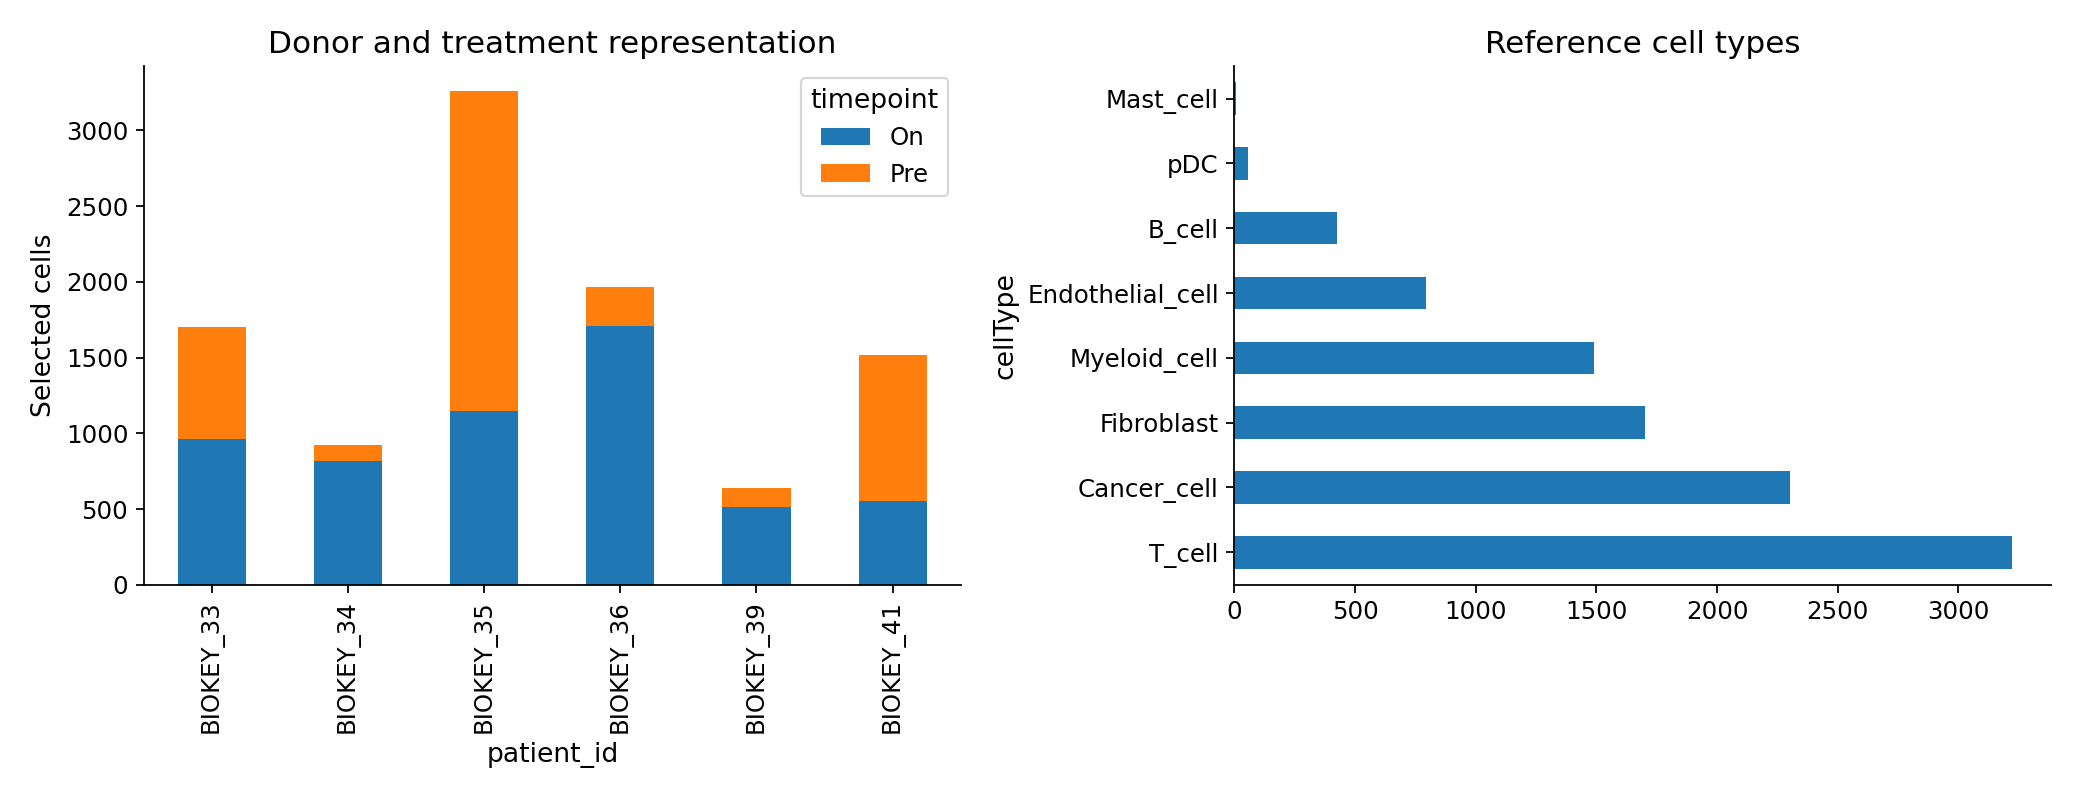

In [3]:
show_generated('sample_representation.png')

Sampling composition across patients, timepoints and source cell types.

In [4]:
# %% Prepare expression

adata = raw.copy()
values = adata.X.data if sp.issparse(adata.X) else np.asarray(adata.X)
assert np.isfinite(values).all() and (values >= 0).all()
assert np.allclose(values, np.round(values)), "Supply unnormalized counts"
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
shared = adata.var_names.isin(G.nodes)
adata = adata[:, shared].copy()
means = np.asarray(adata.X.mean(axis=0)).ravel()
top = np.argsort(means, kind="stable")[-2000:]
adata = adata[:, np.sort(top)].copy()
assert adata.n_vars == 2000
print("Prepared cells × genes:", adata.shape)

# %% Fit the graph model
fit = run_full_pipeline(adata.copy(), G, k=16, lambda_reg=1,
    beta_W=0.01, beta_H=0.01, n_iter=100, tol=0, random_state=SEED, verbose=False)

plt.close("all")
plt.figure(figsize=(7, 4))
plt.plot(np.arange(1, len(fit.uns["loss_history"]) + 1), fit.uns["loss_history"])
plt.xlabel("Iteration")
plt.ylabel("Normalized optimization objective")
plt.tight_layout()
plt.savefig(OUT / "convergence.png", dpi=150)
plt.show()

Prepared cells × genes: (10000, 2000)
Starting Full scKNIFE (Graph-Regularized NMF) Pipeline...
Params - k=16, lambda=1, beta_W=0.01, beta_H=0.01, Iterations=100



Building gene-to-KG node mapping (Rg)...
Mapped 2000 genes to KG nodes.


Running scKNIFE Graph-Regularized NMF on CPU...
Epoch 0: Normalized Loss = 0.227558


Epoch 99: Normalized Loss = 0.179979
Storing H_graph components in adata.obs...
Stored W_graph in `adata.uns['W_graph']` (0.179979 final normalized loss)
Stored H_graph components in `adata.obs`
Running Standard NMF...


Storing H_std components in adata.obs...
Stored W_std in `adata.uns['W_std']`
Stored H_std components in `adata.obs`
Std NMF -> Corr: 0.7205, Frobenius: 3119.77, Relative: 0.5992



Standard NMF:
   Pearson Correlation     : 0.7205
   Frobenius Error         : 3119.7711
   Relative Frobenius Error: 0.5992

scKNIFE (Graph-Regularized NMF):
   Pearson Correlation     : 0.7201
   Frobenius Error         : 3121.5945
   Relative Frobenius Error: 0.5995

Pipeline complete!
Results stored in `adata.obs` and `adata.uns`:
   - `W_std`, `W_graph`
   - `H_std_{i}`, `H_graph_{i}`
   - `loss_history`
   - `Rg`, `node_names`



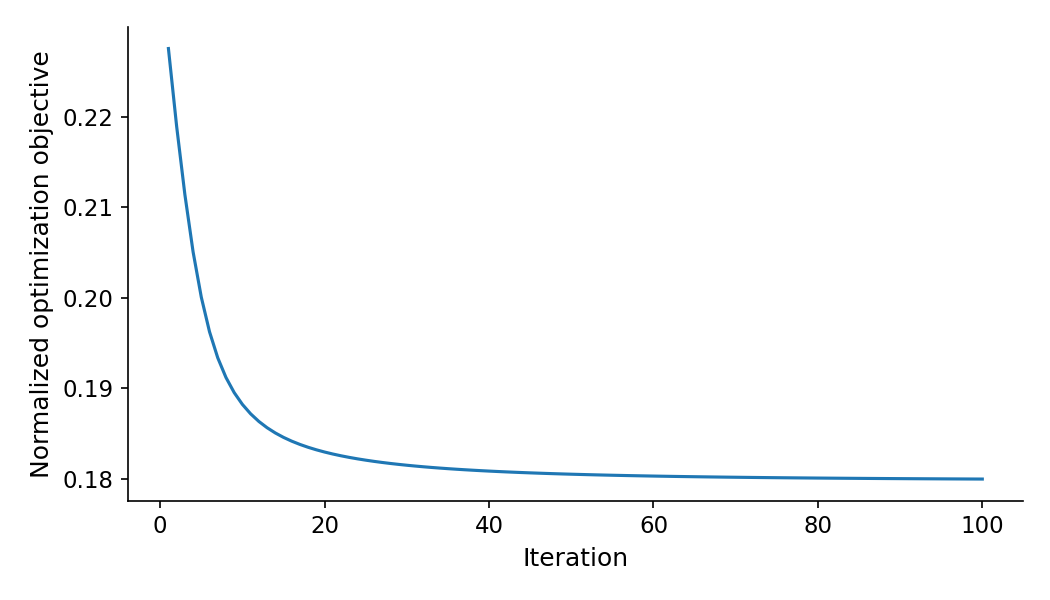

In [5]:
show_generated('convergence.png')

Optimization history of the 10,000-cell fit.

In [6]:
# %% Cluster the learned cell representation
fit, clustering = run_h_graph_clustering_fixed(fit, pca_dims=6,
    n_neighbors=15, resolution=0.5, random_state=SEED)
assert np.isfinite(fit.uns["W_graph"]).all()
assert len(fit.uns["loss_history"]) == 100
clustering.to_csv(OUT / "clustering.csv", index=False)
display(clustering)

fit = compute_activity_scores(fit, batch_size=256)
activity = fit.uns["activity_scores"]
assert activity.shape == (G.number_of_nodes(), fit.n_obs)
assert activity.columns.equals(fit.obs_names)
def nodes_of_kind(kind):
    return [n for n, attrs in G.nodes(data=True) if attrs.get("kind") == kind]
# Retain the original supplied cell identities; clustering does not assign cell types.
assert fit.obs["cellType"].astype(str).equals(raw.obs.loc[fit.obs_names,"cellType"].astype(str))
# %% Export and verify results
activity.to_parquet(OUT / "activity_scores.parquet")
fit.obs.to_csv(OUT / "cell_annotations.csv")
fit.uns.pop("activity_scores", None)
fit.write_h5ad(OUT / "fitted_subset.h5ad")
reloaded = sc.read_h5ad(OUT / "fitted_subset.h5ad")
assert reloaded.shape == fit.shape
assert reloaded.uns["W_graph"].shape == (G.number_of_nodes(), 16)
print("Tutorial completed; results saved to the configured output directory.")
report={"cells":int(fit.n_obs),"genes":int(fit.n_vars),"elapsed_seconds":time.perf_counter()-started,"peak_rss_native_units":resource.getrusage(resource.RUSAGE_SELF).ru_maxrss,"peak_rss_units":"KiB on Linux; bytes on macOS"}
assert fit.n_obs==10000
(OUT/"tutorial_run_report.json").write_text(json.dumps(report,indent=2))
print(report)

import hashlib, platform, importlib.metadata
report.update({"seed": SEED, "rank": 16, "iterations": 100, "python": platform.python_version(),
 "versions": {p: importlib.metadata.version(p) for p in ["numpy", "pandas", "scanpy", "scipy", "scikit-learn"]},
 "graph_sha256": hashlib.sha256((ROOT / "graphs/version_1/unified_graph.graphml").read_bytes()).hexdigest()})
(OUT / "tutorial_run_report.json").write_text(json.dumps(report, indent=2))

,n_clusters,best_pca_dims,best_n_neighbors,best_resolution,metric,random_state,silhouette
0,16,6,15,0.5,cosine,42,0.421956


Computing activity scores from W and H...


  Activity batch 1/40: cells 0-256
  Activity batch 2/40: cells 256-512


  Activity batch 3/40: cells 512-768
  Activity batch 4/40: cells 768-1024


  Activity batch 5/40: cells 1024-1280
  Activity batch 6/40: cells 1280-1536


...

  Activity batch 37/40: cells 9216-9472
  Activity batch 38/40: cells 9472-9728


  Activity batch 39/40: cells 9728-9984
  Activity batch 40/40: cells 9984-10000


Stored activity scores in `adata.uns['activity_scores']`


Tutorial completed; results saved to the configured output directory.
{'cells': 10000, 'genes': 2000, 'elapsed_seconds': 155.9452685760334, 'peak_rss_native_units': 3732264, 'peak_rss_units': 'KiB on Linux; bytes on macOS'}


463

Expected outputs are `fitted_subset.h5ad`, `activity_scores.parquet`, `sample_metadata.csv` and `cell_annotations.csv` under `SCKNIFE_TUTORIAL_OUTPUT`.

## Continue with the fitted outputs

The saved object contains cell factors H and node loadings W. The activity table contains graph nodes × cells and supports the downstream tasks. Next, perform the [cell-type retention](../docs/tutorials/10000-annotation.md), then explore [metabolism](../docs/tutorials/10000-metabolic.md), [factors](../docs/tutorials/10000-factors.md) and [cell–cell signaling](../docs/tutorials/10000-signaling.md).

# Cell-type retention



This section assesses cell-type retention after fitting. First inspect the [optimization history](../docs/tutorials/10000-setup.md), then assess whether the learned representation retains recognizable cell-type organization.

## Biological question

Does the learned scKNIFE representation retain recognizable epithelial, immune and stromal organization? Compare clusters formed from H with source cell-type annotations on the same cells. The factorization does not use those per-cell labels as targets, although cell-identity gene sets enter through the knowledge graph and metadata are used for sample stratification.

This is a visual exploration of cellular organization; scKNIFE does not assign new cell-type labels in this workflow.

## Inputs and code

Complete [model fitting](../docs/tutorials/10000-setup.md). Load its H-space clusters, UMAP and original source cell-type labels. Run from the repository root:

## Compare the learned organization with source labels

In [7]:
import os
from pathlib import Path
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 12, "axes.titlesize": 14,
                     "axes.labelsize": 12, "xtick.labelsize": 11,
                     "ytick.labelsize": 11, "legend.fontsize": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
base = Path(os.environ.get("SCKNIFE_TUTORIAL_OUTPUT", "tutorial/outputs_10000"))
adata = sc.read_h5ad(base / "fitted_subset.h5ad")
assert adata.n_obs == 10000 and adata.obs_names.is_unique
assert adata.obs[["leiden_clusters", "cellType"]].notna().all().all()
clusters = adata.obs["leiden_clusters"].astype(str)
adata.obs["leiden_clusters"] = pd.Categorical(clusters)
out = base / "cellular_organization"
out.mkdir(exist_ok=True)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, key, title in zip(axes, ["leiden_clusters", "cellType"],
                        ["H-space clusters", "Source cell-type annotations"]):
    sc.pl.umap(adata, color=key, ax=ax, show=False, frameon=False, title=title)
fig.tight_layout()
fig.savefig(out / "organization_umap.png", dpi=160, bbox_inches="tight")
plt.close(fig)

<python-environment>/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
<python-environment>/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
<python-environment>/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
<python-environment>/lib/pyt

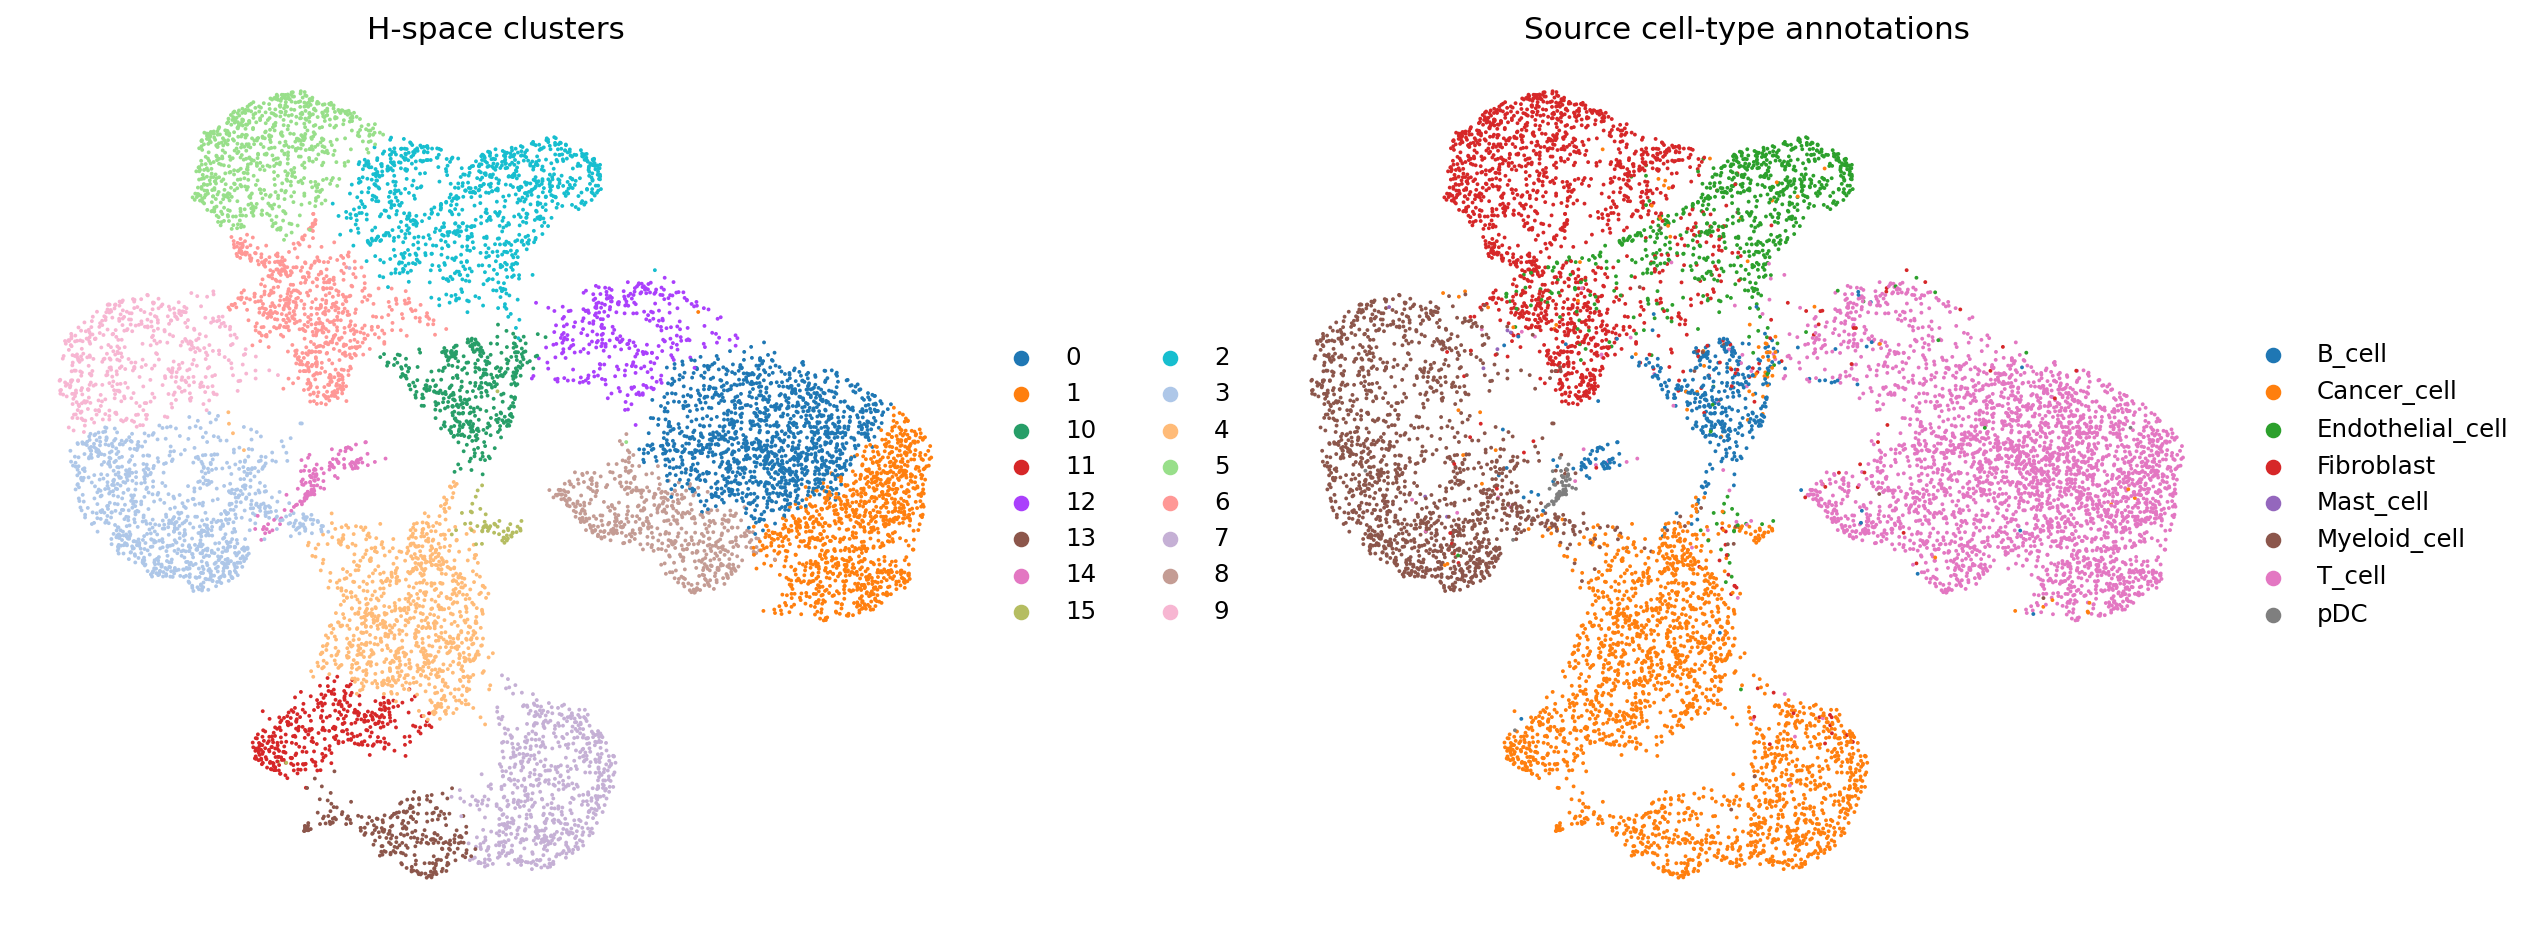

In [8]:
show_generated('cellular_organization/organization_umap.png')

Shared UMAP coordinates colored by H-space cluster and source cell type.

## Interpretation

The panels show the same 10,000 cells on identical UMAP coordinates. One panel colors H-space clusters and the other colors the source cell types, allowing visual inspection of cell-type organization in the learned representation.

## Outputs and next step

Outputs are written to `cellular_organization/`. Next, explore [metabolic activity](../docs/tutorials/10000-metabolic.md) using the same fitted model.

# Metabolic analysis



Explore metabolic-task activity in five steps: **overview → spatial patterns → cell-level variation → linked reactions and genes → condition differences**. All analyses use the same 10,000-cell fit and source `cellType` metadata.

**Prerequisite:** complete [model fitting](../docs/tutorials/10000-setup.md) and [cell-type retention](../docs/tutorials/10000-annotation.md). [Download the complete runnable script](../docs/downloads/metabolic_walkthrough.py). Each step provides one worked example; commented code shows alternative selections.

## Load aligned activities and metadata

Run the following blocks in order in one Python session from the repository root. They load the saved activity matrix and UMAP; no new fit or embedding is computed.

In [9]:
from pathlib import Path
import os, json, hashlib, textwrap
import numpy as np
import pandas as pd
import scanpy as sc
import networkx as nx
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
BASE=Path(os.environ.get('SCKNIFE_TUTORIAL_OUTPUT','tutorial/outputs_10000'))
OUT=BASE/'metabolic_walkthrough';OUT.mkdir(exist_ok=True)
fit=sc.read_h5ad(BASE/'fitted_subset.h5ad')
activity=pd.read_parquet(BASE/'activity_scores.parquet')
assert fit.n_obs==10000 and fit.obs_names.is_unique
assert activity.columns.equals(fit.obs_names) and activity.index.is_unique
assert 'X_umap' in fit.obsm and fit.obsm['X_umap'].shape==(10000,2)
meta=fit.obs[['cellType','patient_id','timepoint']].astype(str)
G=nx.read_graphml('graphs/version_1/unified_graph.graphml')
tasks=sorted(n for n,d in G.nodes(data=True) if d.get('kind')=='task' and n in activity.index)
assert len(tasks)>0
scores=activity.loc[tasks].T
assert np.isfinite(scores.to_numpy()).all() and scores.min().min()>=0
plt.rcParams.update({'font.size':12,'axes.titlesize':13,'axes.labelsize':12,'xtick.labelsize':10,'ytick.labelsize':10,'axes.spines.top':False,'axes.spines.right':False})
def save(name):
 plt.gcf().savefig(OUT/(name+'.png'),dpi=170,bbox_inches='tight');plt.close()
def heat(table,title,name,label,cmap='viridis',signed=False):
 fig,ax=plt.subplots(figsize=(10,max(5,.48*len(table)+1)))
 limit=max(float(np.abs(table.to_numpy()).max()),1e-12)
 im=ax.imshow(table,aspect='auto',cmap=cmap,vmin=-limit if signed else 0,vmax=limit)
 ax.set_xticks(range(table.shape[1]),table.columns,rotation=35,ha='right')
 ax.set_yticks(range(len(table)),[textwrap.fill(str(x),48) for x in table.index])
 ax.set_title(title);fig.colorbar(im,ax=ax,label=label);fig.tight_layout();save(name)

## 1. Overview of task activity across cell types

Begin with the eight task nodes with the highest pooled mean activity. The selection is deterministic and does not use treatment differences.

In [10]:
means=scores.groupby(meta.cellType,observed=True).mean().T
ranked=scores.mean().sort_values(ascending=False,kind='stable')
chosen=ranked.head(8).index
# chosen=ranked.head(12).index  # Show more tasks if needed.
means.to_csv(OUT/'task_means.csv')
heat(means.loc[chosen],'Selected metabolic-task activity','task_overview','Mean reconstructed task activity')

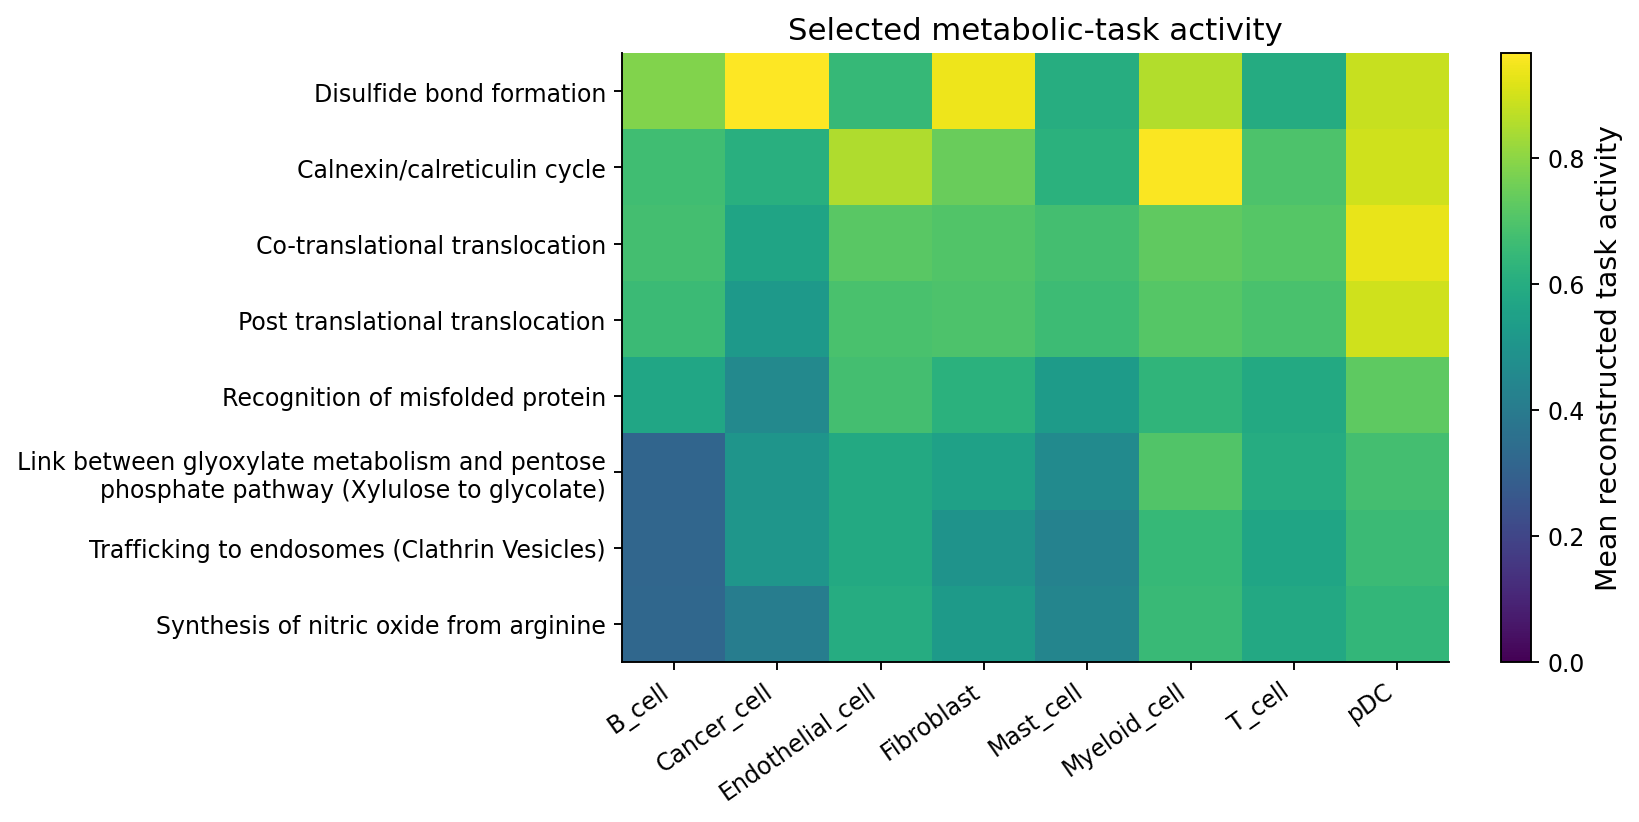

In [11]:
show_generated('metabolic_walkthrough/task_overview.png')

Each row is a task and each column a source cell type. Colors show mean reconstructed activity. The task collection includes processing and trafficking functions as well as metabolic transformations. These are model-derived activity scores, not measured metabolic flux.

## 2. Locate task activity on the shared UMAP

Compare three named task examples on the same saved embedding: glycolytic ATP generation, oxidative ATP regeneration and acetoacetate synthesis. The commented alternative selects the three highest-activity tasks.

In [12]:
example_tasks=[
 'ATP generation from glucose (hypoxic conditions) - glycolysis',
 'ATP regeneration from glucose (normoxic conditions) - glycolysis + krebs cycle',
 'Acetoacetate synthesis',
]
# example_tasks=ranked.head(3).index.tolist()  # Data-ranked alternative.
assert set(example_tasks).issubset(scores.columns)
xy=fit.obsm['X_umap']
fig,axes=plt.subplots(1,3,figsize=(14,4.5))
for ax,task in zip(axes,example_tasks):
 values=np.log1p(scores[task].to_numpy())
 lo,hi=np.quantile(values,[.02,.98])
 order=np.argsort(values,kind='stable')
 im=ax.scatter(xy[order,0],xy[order,1],c=values[order],s=3,cmap='viridis',vmin=lo,vmax=hi,rasterized=True)
 ax.set_title(textwrap.fill(task,30),fontsize=11);ax.set_xticks([]);ax.set_yticks([])
 ax.set_xlabel('UMAP 1');ax.set_ylabel('UMAP 2')
 fig.colorbar(im,ax=ax,label='log(1 + task activity)',shrink=.7)
fig.tight_layout();save('task_umaps')

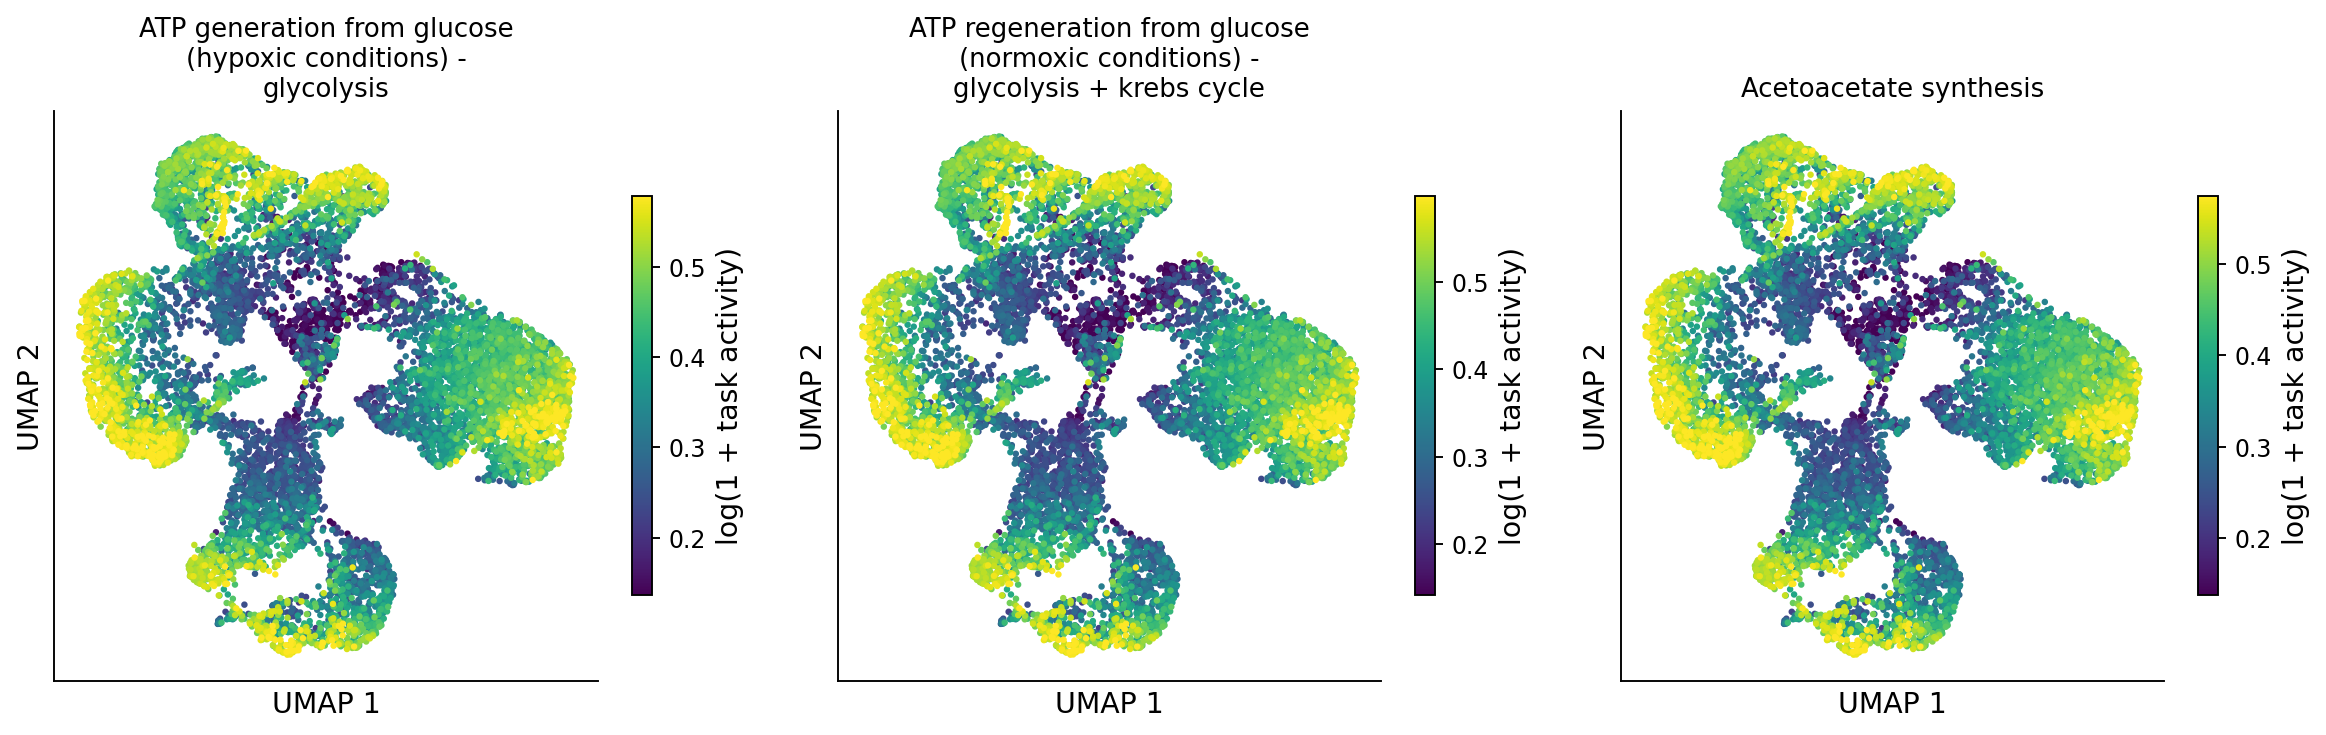

In [13]:
show_generated('metabolic_walkthrough/task_umaps.png')

All three panels contain the same 10,000 cells in identical positions. Color shows log(1 + task activity); each panel clips its display range at its own 2nd and 98th percentiles. Compare spatial patterns within each task rather than color intensity between panels. Task names describe the graph functions; they do not establish measured hypoxia, oxygen consumption or flux.

## 3. Examine variation within cell types

Use glycolytic ATP generation as the single worked example. Uncomment one of the alternative EXAMPLE_TASK assignments to inspect another task.

In [14]:
EXAMPLE_TASK=example_tasks[0]
# EXAMPLE_TASK=example_tasks[1]  # Oxidative ATP regeneration.
# EXAMPLE_TASK=example_tasks[2]  # Acetoacetate synthesis.
types=sorted(meta.cellType.unique())
values=np.log1p(scores[EXAMPLE_TASK])
fig,ax=plt.subplots(figsize=(10,5))
ax.violinplot([values.loc[meta.cellType.eq(t)].to_numpy() for t in types],showmedians=True)
ax.set_xticks(range(1,len(types)+1),[f'{t}\n(n={meta.cellType.eq(t).sum():,})' for t in types],rotation=35,ha='right')
ax.set_ylabel('log(1 + reconstructed task activity)')
ax.set_title(textwrap.fill(EXAMPLE_TASK,65));fig.tight_layout();save('task_distribution')

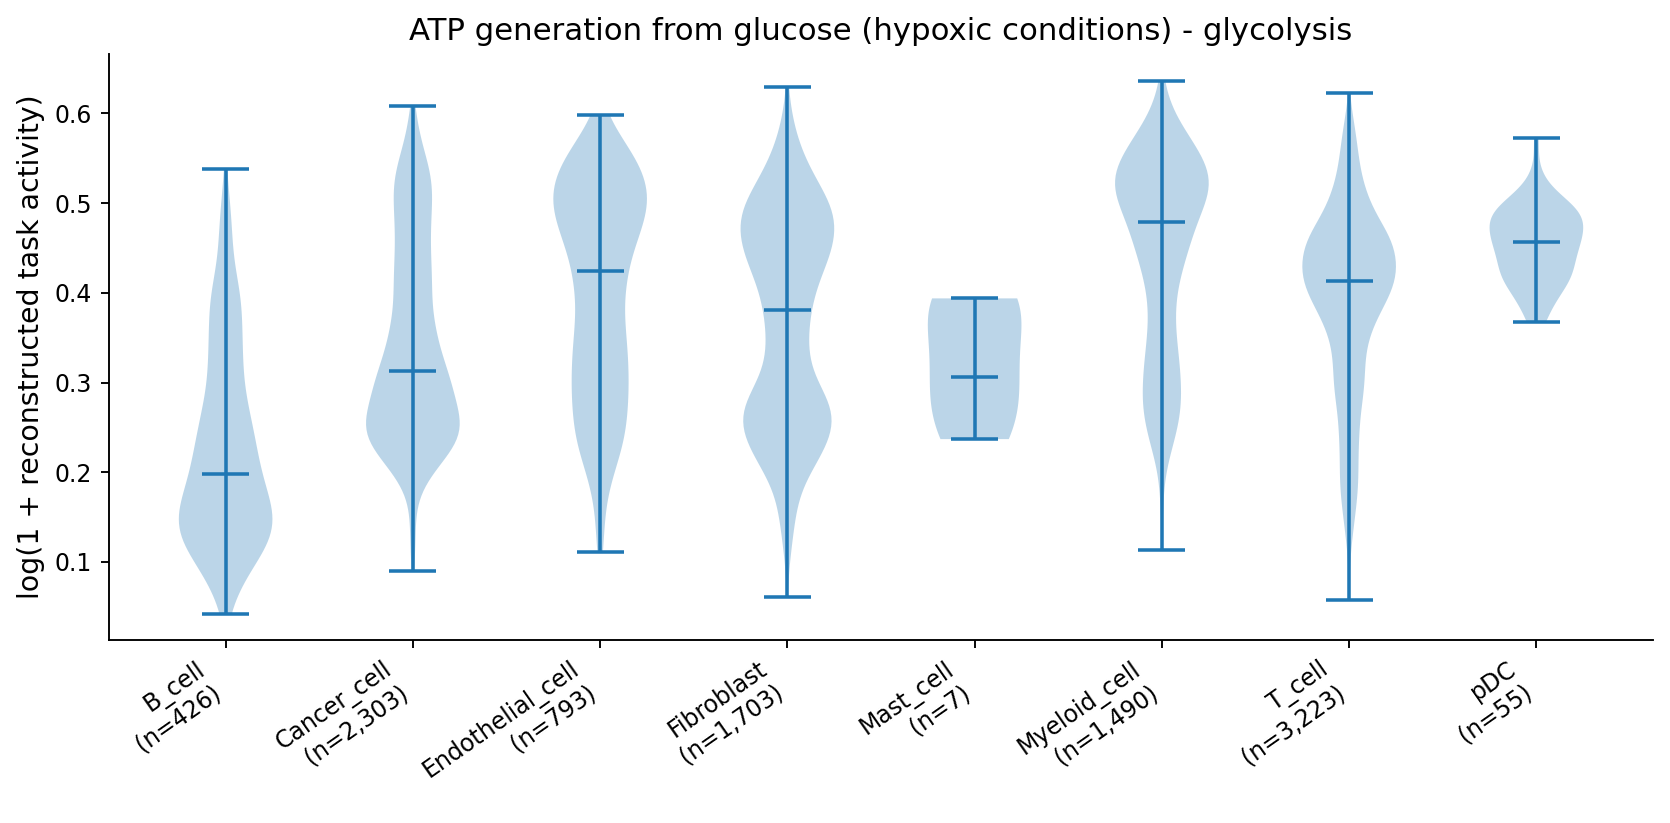

In [15]:
show_generated('metabolic_walkthrough/task_distribution.png')

Each violin shows the distribution of reconstructed activity among cells of one source cell type, with its median and cell count. This reveals heterogeneity hidden by a mean heatmap. The seven mast cells provide limited information about distribution shape. These pooled cell distributions are descriptive, not independent patient replicates.

## 4. Inspect connected reaction and gene activities

Follow existing task–reaction and reaction–gene edges for the selected task. Display the six highest-mean linked reactions and eight highest-mean linked genes. Gene candidates come from all reactions linked to the task, including reactions outside the displayed subset.

In [16]:
# Traverse only existing task–reaction and reaction–gene edges.
reactions=sorted(n for n in G.neighbors(EXAMPLE_TASK) if G.nodes[n].get('kind')=='reaction' and n in activity.index)
assert reactions, 'No linked reactions available for this task'
genes=sorted({n for r in reactions for n in G.neighbors(r) if G.nodes[n].get('kind')=='gene' and n in activity.index})
assert genes, 'No linked genes available for this task'
def top_nodes(names,n):
 return activity.loc[names].mean(axis=1).sort_values(ascending=False,kind='stable').head(n).index.tolist()
shown_reactions=top_nodes(reactions,6)
shown_genes=top_nodes(genes,8)
# shown_reactions=top_nodes(reactions,10)
# shown_genes=top_nodes(genes,12)
linked=[EXAMPLE_TASK]+shown_reactions+shown_genes
linked_means=activity.loc[linked].T.groupby(meta.cellType,observed=True).mean().T
logged=np.log1p(linked_means)
relative=logged.sub(logged.mean(axis=1),axis=0).div(logged.std(axis=1,ddof=0).clip(lower=1e-12),axis=0)
relative.index=[f'{G.nodes[n].get("kind")}: {n}' for n in linked]
heat(relative,'Task and connected reaction/gene activity','linked_support','Row z-score of log(1 + mean activity)','RdBu_r',True)
linked_means.to_csv(OUT/'linked_node_means.csv')
edges=[{'source':EXAMPLE_TASK,'target':r,'relation':'task–reaction'} for r in reactions]
edges += [{'source':r,'target':g,'relation':'reaction–gene'} for r in reactions for g in G.neighbors(r) if g in genes]
pd.DataFrame(edges).to_csv(OUT/'task_reaction_gene_links.csv',index=False)

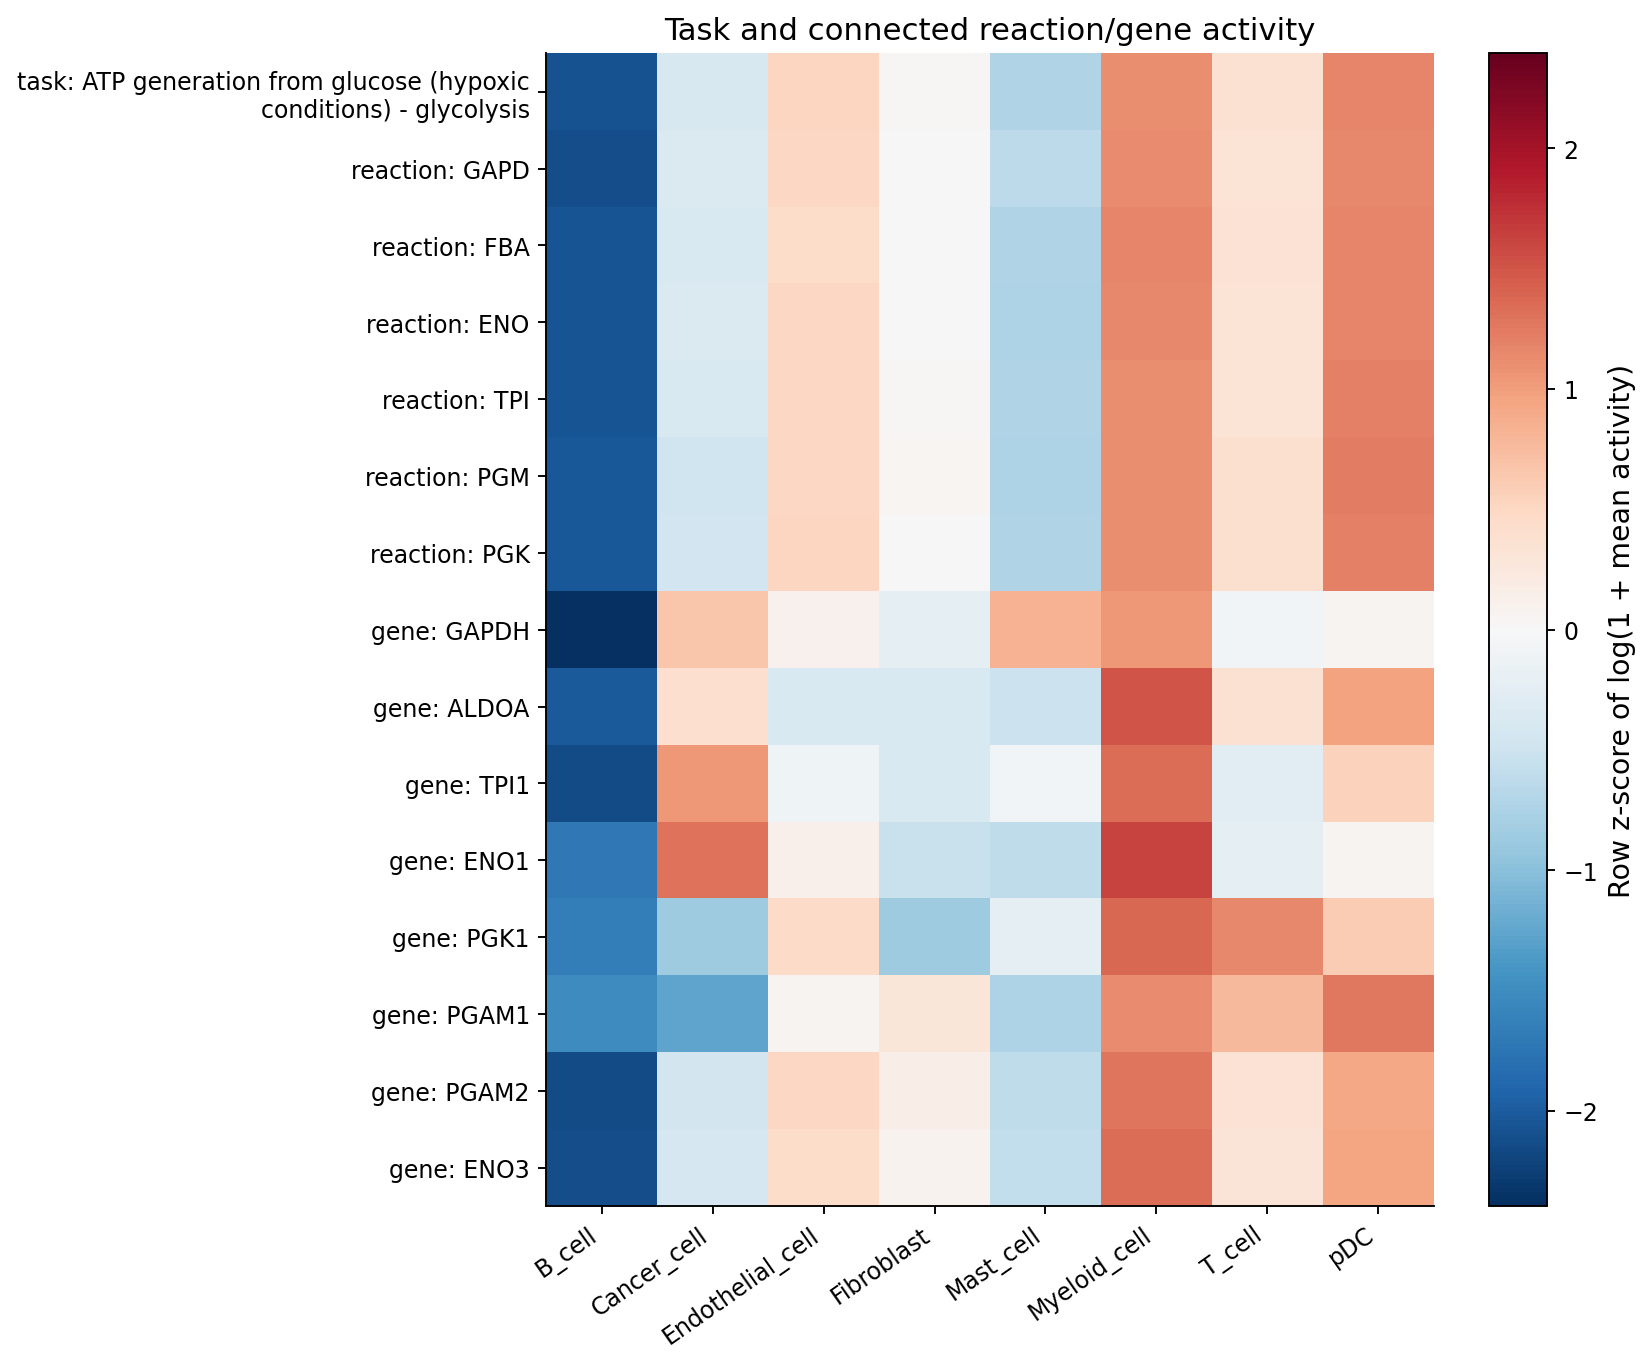

In [17]:
show_generated('metabolic_walkthrough/linked_support.png')

Rows show the selected task and linked biological nodes. Each row is standardized across cell types after log-transforming its mean activity, so colors compare relative patterns within a node. The heatmap provides biological context through existing graph links. It shows reconstructed node activities rather than a decomposition of task flux. The full traced connections and displayed node means are exported.

## 5. Rank descriptive On-minus-Pre task differences

Use cancer cells as the worked example; T cells and myeloid cells remain commented alternatives. Calculate pooled mean task activity within each timepoint, then display eight tasks with the largest absolute On-minus-Pre differences.

In [18]:
CELL_TYPE='Cancer_cell'
# CELL_TYPE='T_cell'
# CELL_TYPE='Myeloid_cell'
mask=meta.cellType.eq(CELL_TYPE) & meta.timepoint.isin(['Pre','On'])
counts=meta.loc[mask].groupby('timepoint').size()
assert all(counts.get(t,0)>=10 for t in ['Pre','On'])
condition_means=scores.loc[mask].groupby(meta.loc[mask,'timepoint']).mean()
delta=condition_means.loc['On']-condition_means.loc['Pre']
selected_delta=delta.loc[delta.abs().sort_values(ascending=False,kind='stable').head(8).index].sort_values()
fig,ax=plt.subplots(figsize=(10,6))
ax.barh(range(len(selected_delta)),selected_delta,color=np.where(selected_delta>=0,'#b85b63','#367fa5'))
ax.set_yticks(range(len(selected_delta)),[textwrap.fill(t,48) for t in selected_delta.index])
ax.axvline(0,color='#333333',lw=.8);ax.set_xlabel('Mean reconstructed activity: On − Pre')
ax.set_title(f'{CELL_TYPE} · descriptive task differences\nPre n={counts["Pre"]:,}; On n={counts["On"]:,}')
fig.tight_layout();save('ranked_differences')
condition_means.T.assign(On_minus_Pre=delta).to_csv(OUT/'condition_task_means.csv')
meta.loc[mask].groupby(['patient_id','timepoint']).size().unstack(fill_value=0).to_csv(OUT/'condition_patient_counts.csv')
summary={'cells':fit.n_obs,'tasks':len(tasks),'example_tasks':example_tasks,'example_task':EXAMPLE_TASK,'cell_type':CELL_TYPE,'linked_reactions':len(reactions),'linked_genes':len(genes),'condition_cells':counts.to_dict(),'cell_id_sha256':hashlib.sha256('\n'.join(fit.obs_names).encode()).hexdigest()}
(OUT/'summary.json').write_text(json.dumps(summary,indent=2));print(summary)

{'cells': 10000, 'tasks': 218, 'example_tasks': ['ATP generation from glucose (hypoxic conditions) - glycolysis', 'ATP regeneration from glucose (normoxic conditions) - glycolysis + krebs cycle', 'Acetoacetate synthesis'], 'example_task': 'ATP generation from glucose (hypoxic conditions) - glycolysis', 'cell_type': 'Cancer_cell', 'linked_reactions': 7, 'linked_genes': 15, 'condition_cells': {'On': 617, 'Pre': 1686}, 'cell_id_sha256': 'a47ad5d98b131c0e47129c7657dcc35515c675cddd510c60e89f986c21212d63'}


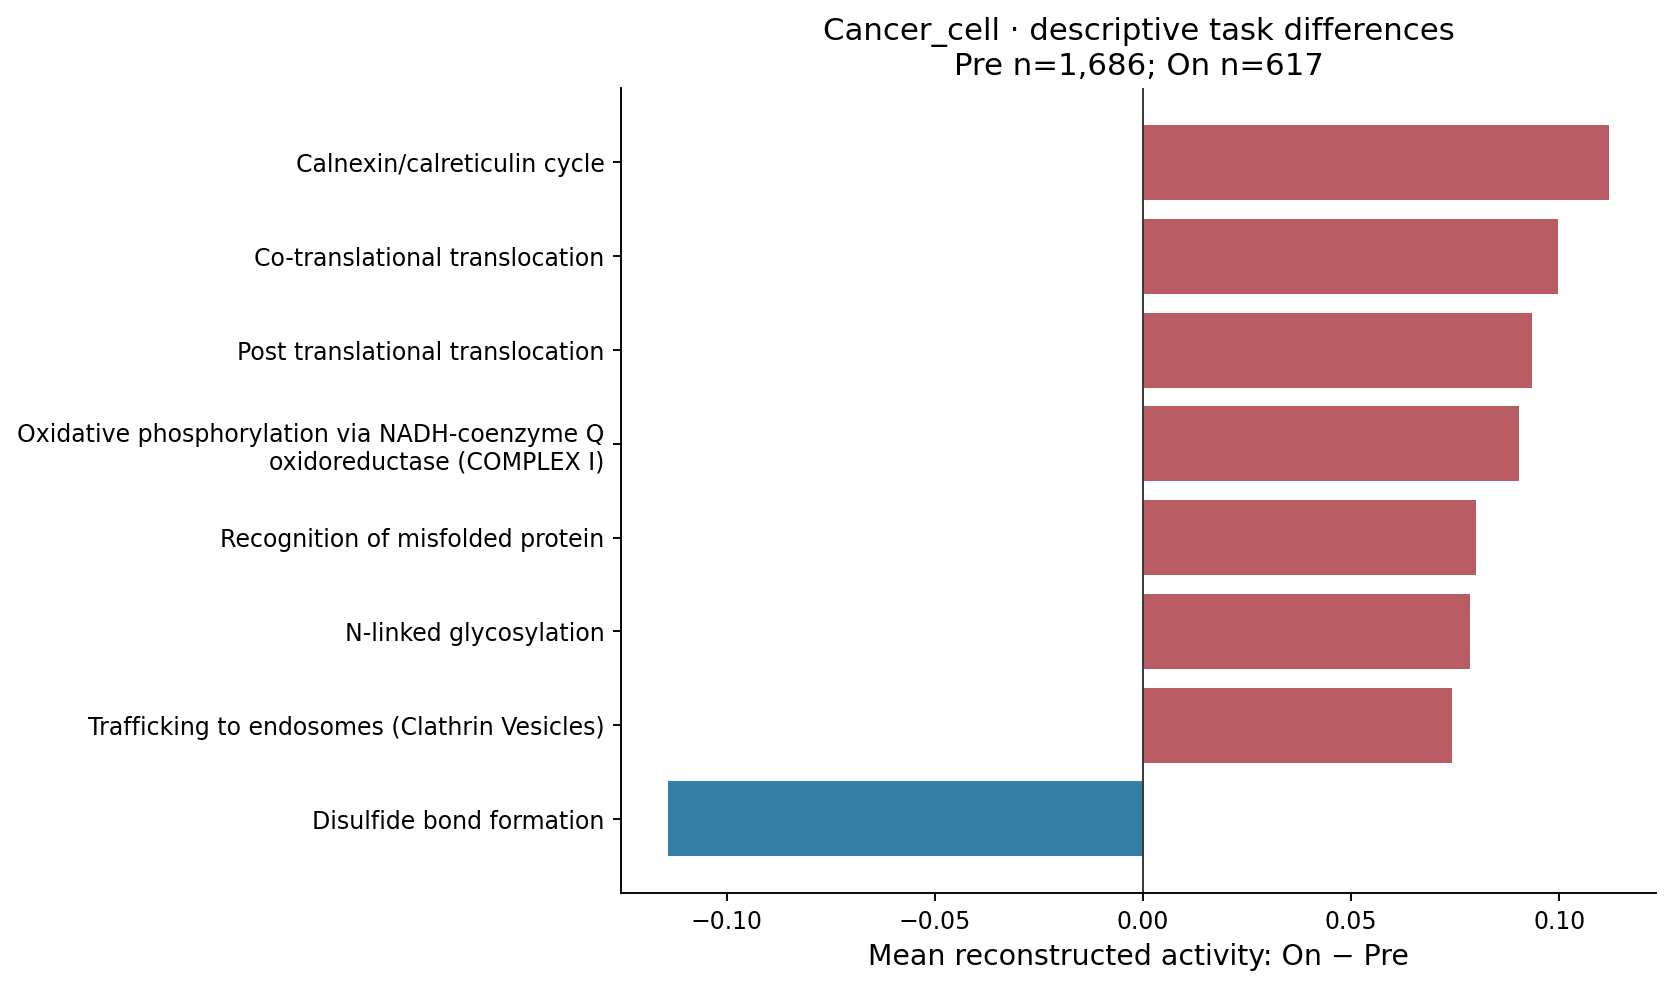

In [19]:
show_generated('metabolic_walkthrough/ranked_differences.png')

Positive bars indicate higher pooled mean activity On-treatment; negative bars indicate higher activity Pre-treatment. These are unstandardized differences in model-derived scores, with no significance test or p-values. Differences can reflect patient composition and cellular-state composition as well as treatment-associated changes. The exported patient-by-timepoint counts document representation. 

## Outputs and next step

Results are saved under `metabolic_walkthrough/`: task means, linked-node means, graph connections, condition means, patient counts, the run summary and five figures. Change an example selection and rerun the relevant blocks to explore other tasks or cell types.

Continue to [factor interpretation](../docs/tutorials/10000-factors.md).

# Factor interpretation



Interpret the fitted model through **factor usage → consensus clusters → representative biological nodes → cell-level activities**. This page uses the same 10,000 cells, 16 fitted factors and source `cellType` metadata.

**Prerequisite:** complete [model fitting](../docs/tutorials/10000-setup.md). Run the blocks in order in one Python session from the repository root. [Download the complete runnable script](../docs/downloads/factor_interpretation.py).

## How to read the output

**CC** (consensus cluster) identifies a group of factors with related W profiles; **NG** identifies the biological nodes selected to interpret that group. NG activity reconstructs those nodes using all aligned factors. CC activity averages H over the factors assigned to that group. The interpretation resolution is **k=4**, while the fitted model rank remains 16. NG activity and CC activity summarize different aspects of the fitted model.

## Load the same fitted model

Load W, its aligned H columns and cell metadata. Exclude cell-type and cell-state nodes only from the interpretation view of W; this does not modify the graph or fit.

In [20]:
from pathlib import Path
import os, json, hashlib, textwrap, time
import numpy as np
import pandas as pd
import scanpy as sc
import networkx as nx
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, fcluster, leaves_list
from scipy.spatial.distance import squareform
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from matplotlib.patches import Patch
START=time.time()
BASE=Path(os.environ.get('SCKNIFE_TUTORIAL_OUTPUT','tutorial/outputs_10000'))
OUT=BASE/'factor_interpretation_k4';OUT.mkdir(exist_ok=True)
plt.rcParams.update({'font.size':12,'axes.titlesize':14,'axes.labelsize':12,'xtick.labelsize':10,'ytick.labelsize':10,'axes.spines.top':False,'axes.spines.right':False})
a=sc.read_h5ad(BASE/'fitted_subset.h5ad')
assert a.n_obs==10000 and a.obs_names.is_unique
nodes=np.asarray(a.uns['node_names']).astype(str)
W=np.asarray(a.uns['W_graph'],dtype=float)
hcols=sorted([c for c in a.obs if c.startswith('H_graph_')],key=lambda c:int(c.rsplit('_',1)[1]))
H=a.obs[hcols].to_numpy(float)
assert H.shape==(10000,16) and W.shape==(len(nodes),16)
assert np.isfinite(W).all() and np.isfinite(H).all() and W.min()>=0 and H.min()>=0
meta=a.obs[['cellType','patient_id','timepoint']].astype(str)
types=sorted(meta.cellType.unique())
G=nx.read_graphml('graphs/version_1/unified_graph.graphml')
kinds=np.array([str(G.nodes[n].get('kind','')) for n in nodes])
keep=(~np.isin(kinds,['cell_type','cell_state'])) & (W.sum(axis=1)>0)
W_ELIGIBLE=pd.DataFrame(W[keep],index=nodes[keep],columns=[str(i) for i in range(16)])
NODE_METADATA_ELIGIBLE=pd.DataFrame({'node_name':nodes[keep],'node_kind':kinds[keep]})
def row_z(x):
 x=np.log1p(np.asarray(x,dtype=float))
 return (x-x.mean(axis=1,keepdims=True))/np.maximum(x.std(axis=1,keepdims=True),1e-12)
def save(name):
 plt.gcf().savefig(OUT/(name+'.png'),dpi=170,bbox_inches='tight');plt.close()
def heat(table,title,name,label='Row z-score of log(1 + mean activity)',signed=True):
 fig,ax=plt.subplots(figsize=(9,max(4,.33*len(table)+1.5)))
 lim=max(float(np.max(np.abs(table.to_numpy()))),1e-12)
 im=ax.imshow(table,aspect='auto',cmap='RdBu_r' if signed else 'viridis',vmin=-lim if signed else 0,vmax=lim)
 ax.set_xticks(range(table.shape[1]),table.columns,rotation=40,ha='right')
 ax.set_yticks(range(len(table)),table.index);ax.set_title(title)
 fig.colorbar(im,ax=ax,label=label);fig.tight_layout();save(name)

## Begin with H: factor usage across cell types

Start with the original factor activities before grouping factors.

In [21]:
factor_means=pd.DataFrame(H,index=a.obs_names,columns=hcols).groupby(meta.cellType).mean().reindex(types).T
heat(factor_means,'Mean H activity by source cell type','factor_usage','Mean H activity',False)
factor_means.to_csv(OUT/'factor_usage.csv')

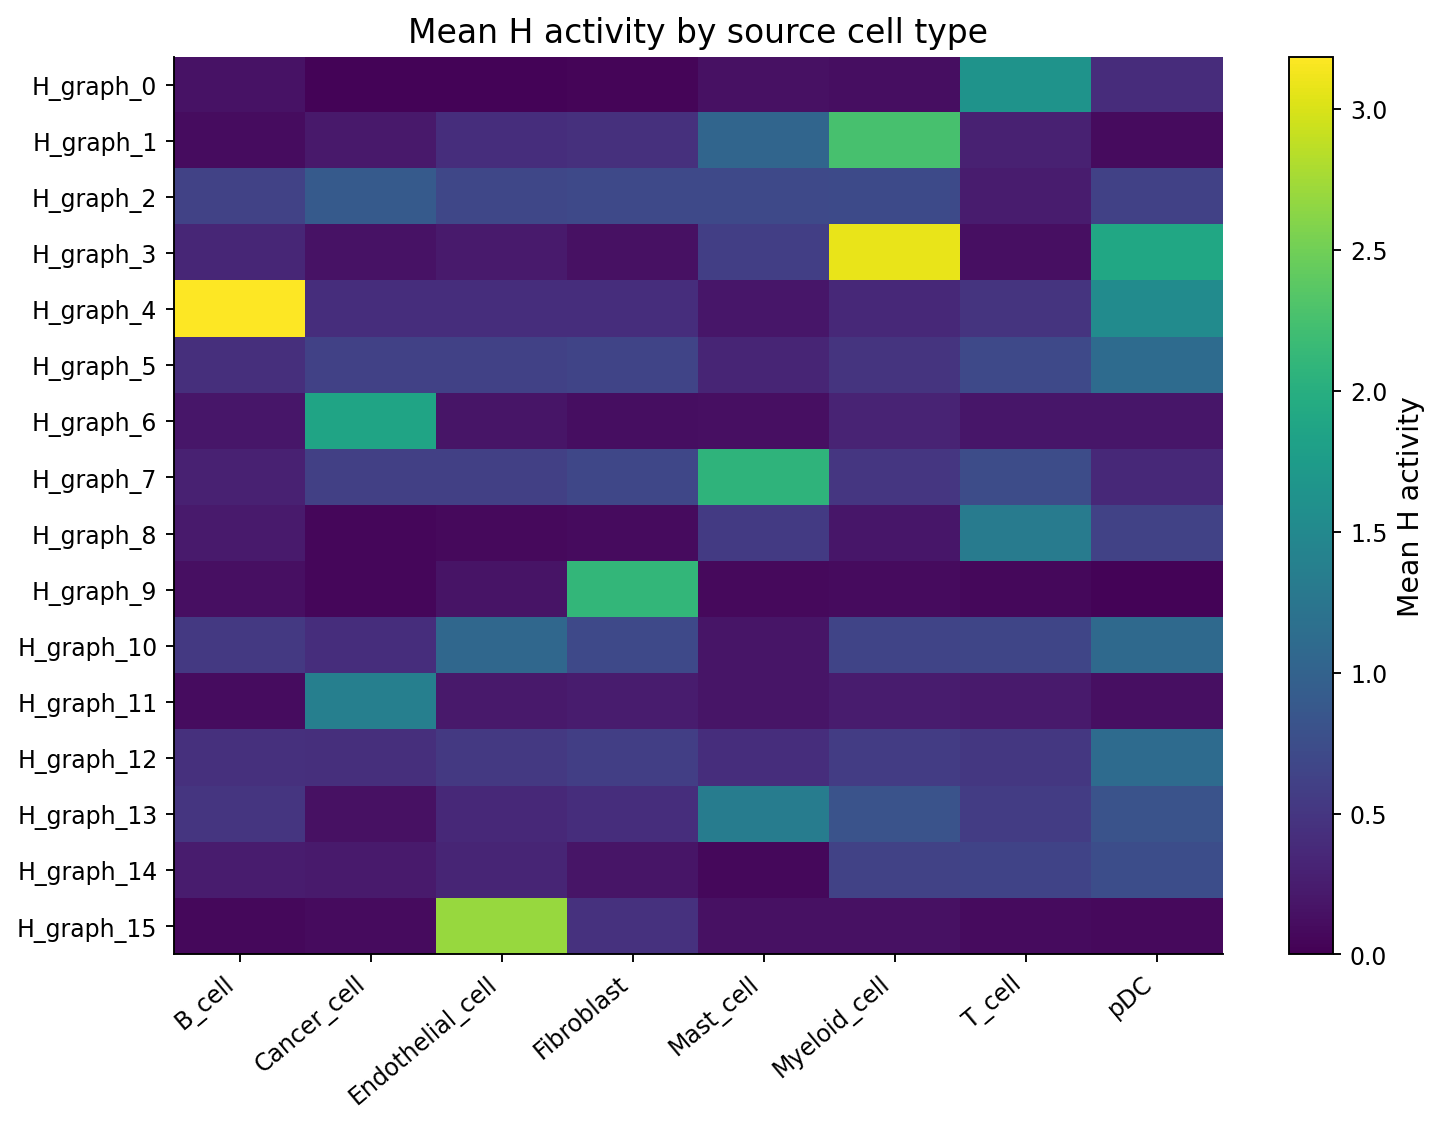

In [22]:
show_generated('factor_interpretation_k4/factor_usage.png')

Each row is one fitted H factor; each column is a source cell type. Colors show mean H activity. This is a descriptive view of factor usage, not a cell-label prediction.

## Choose the number of factor groups using W consensus

The analysis standardizes log(1 + W) within each node, resamples 80% of eligible nodes with replacement 200 times, and clusters factors using correlation distance and average linkage. We test k=2–12 for this 16-factor fit. PAC measures the fraction of factor pairs with ambiguous consensus (between 0.1 and 0.9). After reviewing these diagnostics, this tutorial uses the chosen resolution **k=4**. The fitted model rank remains 16.

In [23]:
SEED=42;BOOTSTRAPS=200;RESAMPLE_FRACTION=.8
K_VALUES=range(2,13)
W_Z=row_z(W_ELIGIBLE)
rng=np.random.default_rng(SEED)
sums={k:np.zeros((16,16)) for k in K_VALUES}
for b in range(BOOTSTRAPS):
 rows=rng.choice(len(W_Z),int(.8*len(W_Z)),replace=True)
 d=np.clip(1-np.corrcoef(W_Z[rows].T),0,2);np.fill_diagonal(d,0)
 for k in K_VALUES:
  lab=AgglomerativeClustering(n_clusters=k,metric='precomputed',linkage='average').fit_predict(d)
  sums[k]+=lab[:,None]==lab[None,:]
records=[];solutions={}
for k in K_VALUES:
 c=sums[k]/BOOTSTRAPS;d=1-c;np.fill_diagonal(d,0)
 tree=linkage(squareform(d,checks=False),method='average')
 lab=fcluster(tree,t=k,criterion='maxclust')-1
 sizes=np.bincount(lab);upper=c[np.triu_indices(16,1)]
 records.append({'k':k,'actual_groups':len(sizes),'PAC':np.mean((upper>.1)&(upper<.9)),
  'silhouette':silhouette_score(d,lab,metric='precomputed'),'min_size':sizes.min(),'max_size':sizes.max()})
 solutions[k]=(c,lab,tree)
metrics=pd.DataFrame(records)
# Review consensus diagnostics, then use the chosen four-group resolution.
eligible=metrics[(metrics.min_size>=2)&(metrics.actual_groups==metrics.k)]
assert not eligible.empty
SELECTED_K=4  # Chosen tutorial resolution; fitted model rank remains 16.
assert SELECTED_K in eligible.k.values
metrics.to_csv(OUT/'k_diagnostics.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,col,title in zip(axes,['PAC','silhouette'],['Ambiguous consensus fraction · lower is better','Consensus silhouette · higher is better']):
 ax.plot(metrics.k,metrics[col],'o-',color='#247b87')
 ax.scatter(eligible.k,eligible[col],s=110,facecolors='none',edgecolors='#d7832c',label='No singleton groups')
 ax.axvline(SELECTED_K,color='#9b456b',ls='--',label=f'Selected k={SELECTED_K}')
 ax.set_xlabel('Number of factor groups (k)');ax.set_title(title,fontsize=12);ax.set_xticks(list(K_VALUES))
axes[0].legend(fontsize=9);fig.tight_layout();save('choose_k')
print(metrics.to_string(index=False),flush=True);print('SELECTED_K',SELECTED_K,flush=True)

 k  actual_groups      PAC  silhouette  min_size  max_size
 2              2 0.000000    0.999373         7         9
 3              3 0.000000    0.998121         3         7
 4              4 0.000000    0.998246         3         6
 5              5 0.083333    0.904060         1         6
 6              6 0.041667    0.876563         1         4
 7              7 0.000000    0.875000         1         4
 8              8 0.050000    0.858750         1         3
 9              9 0.000000    0.804375         1         3
10             10 0.000000    0.687500         1         3
11             11 0.016667    0.526250         1         3
12             12 0.000000    0.433125         1         3


SELECTED_K 4


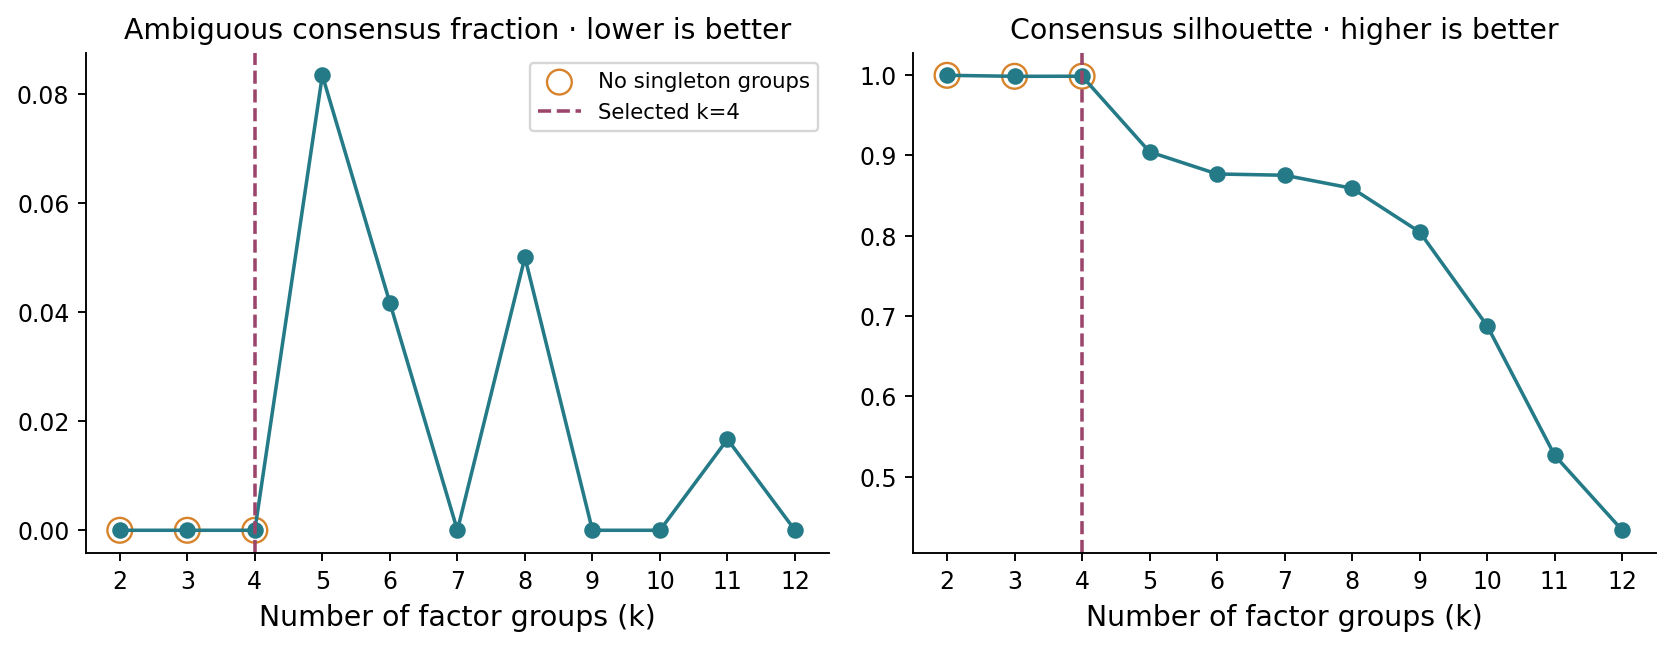

In [24]:
show_generated('factor_interpretation_k4/choose_k.png')

At **k=4**, the solution has PAC=0 and a consensus silhouette of approximately 0.998; every group has at least three factors. k=2 and k=3 also have strong support, so k=4 is a selected interpretation resolution rather than a uniquely established biological optimum. 

## Inspect consensus and factor membership

Relabel groups consistently by their smallest factor index, then inspect pairwise co-clustering.

In [25]:
consensus,raw,tree=solutions[SELECTED_K]
raw_order=sorted(set(raw),key=lambda l:np.flatnonzero(raw==l)[0])
labels=np.array([raw_order.index(l) for l in raw])
groups=[f'CC{i+1}' for i in range(SELECTED_K)]
ngroups=[f'NG{i+1}' for i in range(SELECTED_K)]
COMPONENT_ASSIGNMENTS=pd.DataFrame({'component':[str(i) for i in range(16)],'consensus_cluster':labels})
COMPONENT_ASSIGNMENTS.to_csv(OUT/'factor_groups.csv',index=False)
order=np.lexsort((np.arange(16),labels))
ticks=[f'H{i} · {groups[labels[i]]}' for i in order]
heat(pd.DataFrame(consensus[np.ix_(order,order)],index=ticks,columns=ticks),'Bootstrap factor co-clustering','consensus','Co-clustering fraction',False)

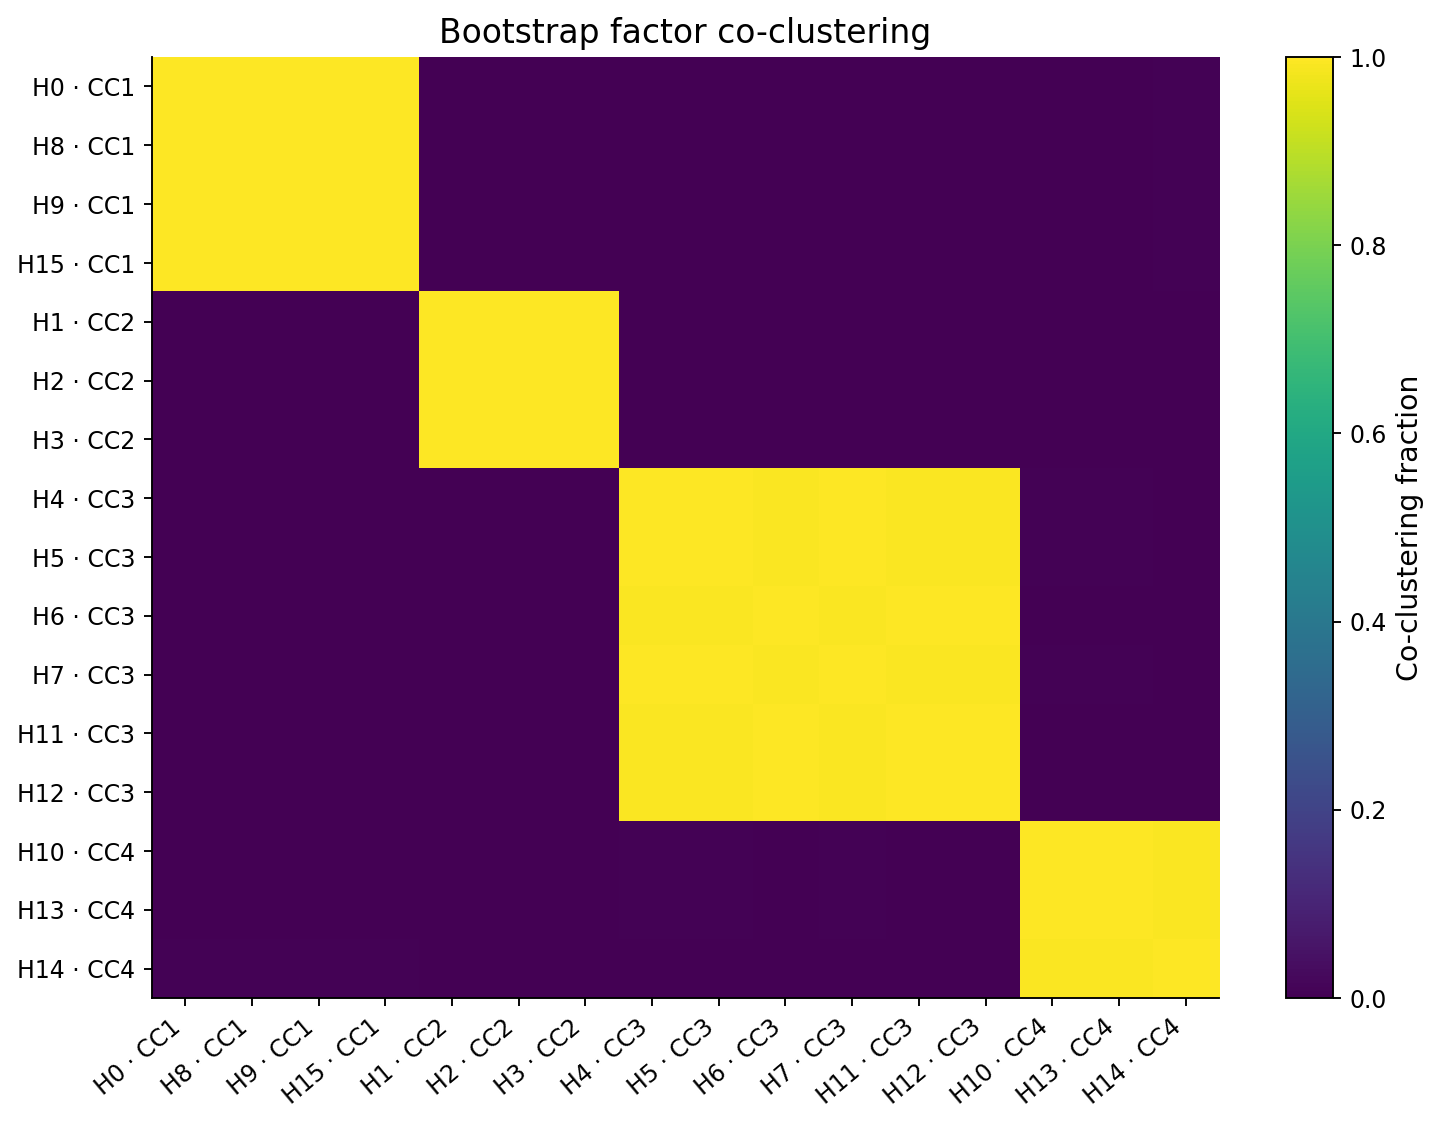

In [26]:
show_generated('factor_interpretation_k4/consensus.png')

Each tile is the fraction of bootstrap runs in which two factors were assigned together. Labels identify factor membership. Strong within-group blocks indicate stable grouping under the specified node resampling.

## Compare nearby grouping resolutions

Review k=2, 3 and 4 before proceeding. The selected resolution is used consistently in every subsequent calculation.

In [27]:
sensitivity=[]
for k in [2,3,4]:
 lab=solutions[k][1]
 ordered_labels=sorted(set(lab),key=lambda v:np.flatnonzero(lab==v)[0])
 sensitivity.append([ordered_labels.index(v)+1 for v in lab])
fig,ax=plt.subplots(figsize=(10,3))
ax.imshow(sensitivity,cmap='tab10',aspect='auto',vmin=1,vmax=10)
for i,row in enumerate(sensitivity):
 for j,v in enumerate(row):ax.text(j,i,str(v),ha='center',va='center',color='white')
ax.set_xticks(range(16),[f'H{i}' for i in range(16)],rotation=45)
ax.set_yticks(range(3),['k=2','k=3','k=4']);ax.set_title('Factor membership at nearby resolutions')
fig.tight_layout();save('resolution_sensitivity')

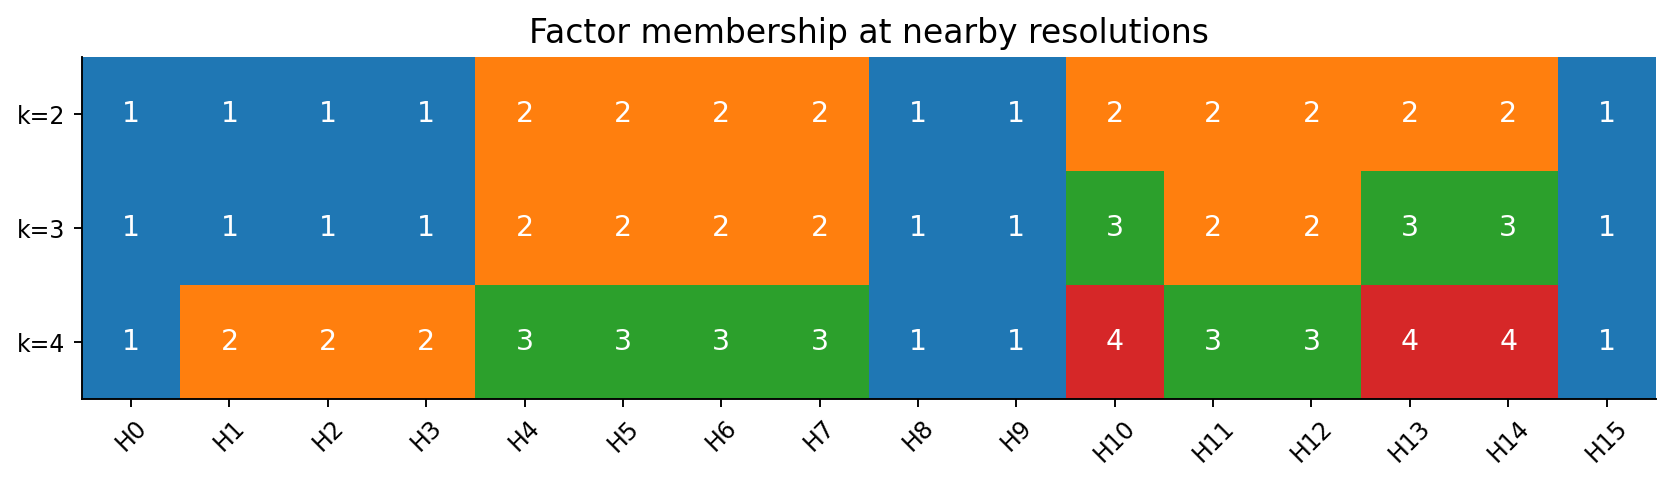

In [28]:
show_generated('factor_interpretation_k4/resolution_sensitivity.png')

Each row shows factor membership at one resolution. Group numbers are local to that row. To explore a finer resolution, set SELECTED_K to a reviewed value after the sweep and rerun every subsequent block; do not mix figures from different resolutions.

## Select representative biological nodes

For each group, calculate the difference between mean node-wise W z-scores inside and outside the group. Assign each node to its strongest positive group. Within each group × node kind, rank nodes and use exp(−(rank−1)/5) weights to retain a prefix covering 95% of the weight, capped at 20 nodes. The selection procedure fills a globally unique budget of 20 mixed nodes per group, prioritizing strongest assignments and recording any local backfill.

In [29]:
DECAY_TAU=5.;DECAY_CUMULATIVE_MASS=.95;MAX_NODES_PER_CLUSTER_KIND=20;TOP_N=20
def score_nodes(node_zscores, metadata, assignments):
    labels_local = assignments["consensus_cluster"].to_numpy()
    records = []
    for cluster_id in range(SELECTED_K):
        inside = labels_local == cluster_id
        outside = ~inside
        frame = metadata.copy()
        frame["consensus_cluster"] = cluster_id
        frame["n_cluster_components"] = int(inside.sum())
        frame["mean_z_inside"] = node_zscores[:, inside].mean(axis=1)
        frame["mean_z_outside"] = node_zscores[:, outside].mean(axis=1)
        frame["enrichment_delta_z"] = (
            frame["mean_z_inside"] - frame["mean_z_outside"]
        )
        frame["category_percentile"] = frame.groupby(
            "node_kind"
        )["enrichment_delta_z"].rank(method="average", pct=True)
        records.append(frame)
    return pd.concat(records, ignore_index=True)

def assign_nodes_to_strongest_cluster(scores):
    """Assign each node once to its strongest positive-enrichment cluster."""
    ordered = scores.sort_values(
        [
            "node_name",
            "enrichment_delta_z",
            "mean_z_inside",
            "consensus_cluster",
        ],
        ascending=[True, False, False, True],
        kind="mergesort",
    )
    assigned = ordered.drop_duplicates("node_name", keep="first").copy()
    assigned = assigned[assigned["enrichment_delta_z"] > 0].copy()
    return assigned.sort_values(
        ["consensus_cluster", "node_kind", "node_name"],
        kind="mergesort",
    ).reset_index(drop=True)

def rank_nodes_with_exponential_decay(
    assigned,
    tau=DECAY_TAU,
    cumulative_mass=DECAY_CUMULATIVE_MASS,
    max_per_group=MAX_NODES_PER_CLUSTER_KIND,
):
    """Rank independently within cluster × node kind and select a decay prefix."""
    if tau <= 0:
        raise ValueError("DECAY_TAU must be positive")
    if not 0 < cumulative_mass <= 1:
        raise ValueError("DECAY_CUMULATIVE_MASS must be in (0, 1]")
    if int(max_per_group) < 1:
        raise ValueError("MAX_NODES_PER_CLUSTER_KIND must be positive")

    ranked_parts = []
    summary_records = []
    group_columns = ["consensus_cluster", "node_kind"]
    for (cluster_id, node_kind), group in assigned.groupby(
        group_columns, sort=True, observed=True
    ):
        group = group.sort_values(
            ["enrichment_delta_z", "mean_z_inside", "node_name"],
            ascending=[False, False, True],
            kind="mergesort",
        ).reset_index(drop=True)
        group["category_rank"] = np.arange(1, len(group) + 1)
        group["decay_weight"] = np.exp(
            -(group["category_rank"].to_numpy(dtype=float) - 1.0) / tau
        )
        total_weight = float(group["decay_weight"].sum())
        group["decay_mass_fraction"] = group["decay_weight"] / total_weight
        group["decay_cumulative_mass"] = group[
            "decay_mass_fraction"
        ].cumsum()

        reached = np.flatnonzero(
            group["decay_cumulative_mass"].to_numpy() >= cumulative_mass
        )
        uncapped_cutoff = int(reached[0] + 1) if len(reached) else len(group)
        cutoff_rank = min(uncapped_cutoff, int(max_per_group))
        group["decay_cutoff_rank"] = cutoff_rank
        group["category_quota"] = cutoff_rank
        group["decay_selected"] = group["category_rank"] <= cutoff_rank
        group["decay_backfill"] = False
        group["selection_reason"] = np.where(
            group["decay_selected"], "decay_prefix", "not_selected"
        )
        achieved_mass = float(
            group.loc[cutoff_rank - 1, "decay_cumulative_mass"]
        )
        summary_records.append({
            "consensus_cluster": int(cluster_id),
            "node_kind": str(node_kind),
            "eligible_positive": int(len(group)),
            "decay_selected": int(cutoff_rank),
            "decay_tau": float(tau),
            "target_cumulative_mass": float(cumulative_mass),
            "achieved_cumulative_mass": achieved_mass,
            "maximum_per_cluster_kind": int(max_per_group),
            "cap_reached": bool(uncapped_cutoff > max_per_group),
            "target_reached": bool(achieved_mass >= cumulative_mass),
        })
        ranked_parts.append(group)

    ranked = pd.concat(ranked_parts, ignore_index=True)
    ranked = ranked.sort_values(
        ["consensus_cluster", "node_kind", "category_rank"],
        kind="mergesort",
    ).reset_index(drop=True)
    summary = pd.DataFrame(summary_records).sort_values(
        ["consensus_cluster", "node_kind"], kind="mergesort"
    ).reset_index(drop=True)
    return ranked, summary

def select_mixed_decay_budget(
    assigned_ranked, cluster_local_ranked, per_cluster_budget, selected_k
):
    """Fill a globally unique fixed budget, prioritizing strongest assignments."""
    selected_parts = []
    used_nodes = set()
    priority_columns = [
        "decay_weight",
        "enrichment_delta_z",
        "mean_z_inside",
        "node_name",
    ]
    priority_ascending = [False, False, False, True]

    assigned_prefix_counts = (
        assigned_ranked[assigned_ranked["decay_selected"]]
        .groupby("consensus_cluster")
        .size()
        .reindex(range(selected_k), fill_value=0)
    )
    cluster_order = assigned_prefix_counts.sort_values(
        ascending=True, kind="mergesort"
    ).index.tolist()

    for cluster_id in cluster_order:
        assigned_rows = assigned_ranked[
            assigned_ranked["consensus_cluster"].eq(cluster_id)
            & assigned_ranked["decay_selected"]
            & ~assigned_ranked["node_name"].isin(used_nodes)
        ].sort_values(
            priority_columns,
            ascending=priority_ascending,
            kind="mergesort",
        )
        chosen = assigned_rows.head(per_cluster_budget).copy()
        chosen["decay_backfill"] = False
        chosen["selection_reason"] = "strongest_cluster_decay_prefix"

        if len(chosen) < per_cluster_budget:
            local_rows = cluster_local_ranked[
                cluster_local_ranked["consensus_cluster"].eq(cluster_id)
                & cluster_local_ranked["decay_selected"]
                & ~cluster_local_ranked["node_name"].isin(used_nodes)
                & ~cluster_local_ranked["node_name"].isin(
                    chosen["node_name"]
                )
            ].sort_values(
                priority_columns,
                ascending=priority_ascending,
                kind="mergesort",
            )
            local_fill = local_rows.head(
                per_cluster_budget - len(chosen)
            ).copy()
            local_fill["decay_backfill"] = True
            local_fill["selection_reason"] = "cluster_local_decay_prefix"
            chosen = pd.concat([chosen, local_fill], ignore_index=True)

        if len(chosen) < per_cluster_budget:
            remaining = cluster_local_ranked[
                cluster_local_ranked["consensus_cluster"].eq(cluster_id)
                & ~cluster_local_ranked["node_name"].isin(used_nodes)
                & ~cluster_local_ranked["node_name"].isin(
                    chosen["node_name"]
                )
            ].sort_values(
                priority_columns,
                ascending=priority_ascending,
                kind="mergesort",
            )
            backfill = remaining.head(
                per_cluster_budget - len(chosen)
            ).copy()
            backfill["decay_backfill"] = True
            backfill["selection_reason"] = "budget_backfill"
            chosen = pd.concat([chosen, backfill], ignore_index=True)

        if len(chosen) != per_cluster_budget:
            raise RuntimeError(
                f"Cluster {cluster_id} has only {len(chosen)} available "
                f"unique positive nodes for a {per_cluster_budget}-node budget"
            )
        chosen = chosen.sort_values(
            priority_columns,
            ascending=priority_ascending,
            kind="mergesort",
        ).reset_index(drop=True)
        chosen["cluster_rank"] = np.arange(1, len(chosen) + 1)
        used_nodes.update(chosen["node_name"].tolist())
        selected_parts.append(chosen)

    return pd.concat(selected_parts, ignore_index=True).sort_values(
        ["consensus_cluster", "cluster_rank"], kind="mergesort"
    ).reset_index(drop=True)
ALL_NODE_SCORES=score_nodes(W_Z,NODE_METADATA_ELIGIBLE,COMPONENT_ASSIGNMENTS)
assigned=assign_nodes_to_strongest_cluster(ALL_NODE_SCORES)
ranked,decay_audit=rank_nodes_with_exponential_decay(assigned)
local,local_audit=rank_nodes_with_exponential_decay(ALL_NODE_SCORES[ALL_NODE_SCORES.enrichment_delta_z>0])
selected=select_mixed_decay_budget(ranked,local,TOP_N,SELECTED_K)
assert selected.node_name.is_unique and len(selected)==TOP_N*SELECTED_K
assert selected.enrichment_delta_z.gt(0).all()
selected.to_csv(OUT/'selected_nodes.csv',index=False);decay_audit.to_csv(OUT/'decay_audit.csv',index=False)

The resulting dictionary contains 80 unique biological nodes. `selected_nodes.csv` records node kind, enrichment, rank and selection reason; `decay_audit.csv` records the category-specific cutoffs. Enrichment here is a relative loading contrast, not a statistical enrichment test.

## Read the node dictionary and relative W profiles

Each heatmap combines all 80 selected nodes from NG1–NG4. Horizontal boundaries separate node groups. Read the individual-factor profiles first, then the CC-mean summary and node-kind composition.

In [30]:
wmean=np.column_stack([W_ELIGIBLE.to_numpy()[:,labels==g].mean(axis=1) for g in range(SELECTED_K)])
wz=pd.DataFrame(row_z(wmean),index=W_ELIGIBLE.index,columns=groups)
rows=selected.sort_values(['consensus_cluster','cluster_rank'])
row_groups=rows.consensus_cluster.to_numpy()
row_names=[textwrap.fill(f'{ngroups[g]}: {n} [{kind}]',52)
           for g,n,kind in zip(row_groups,rows.node_name,rows.node_kind)]
def combined_node_heatmap(values,columns,title,filename,color_label,factor_columns=False):
 fig,ax=plt.subplots(figsize=(12,max(6,.36*len(rows)+2)))
 limit=max(float(np.abs(values).max()),1e-12)
 im=ax.imshow(values,aspect='auto',cmap='RdBu_r',vmin=-limit,vmax=limit)
 ax.set_yticks(range(len(rows)),row_names,fontsize=10)
 ax.set_xticks(range(len(columns)),columns,rotation=45,ha='right')
 for boundary in np.flatnonzero(np.diff(row_groups)!=0)+.5:
  ax.axhline(boundary,color='#273e50',lw=1.2)
 if factor_columns:
  for boundary in np.flatnonzero(np.diff(labels[order])!=0)+.5:
   ax.axvline(boundary,color='#273e50',lw=1.2)
  top=ax.secondary_xaxis('top')
  top.set_xticks([np.flatnonzero(labels[order]==g).mean() for g in range(SELECTED_K)],groups)
  top.tick_params(length=0)
 ax.set_title(title,pad=30 if factor_columns else 12)
 fig.colorbar(im,ax=ax,label=color_label,fraction=.025,pad=.03)
 fig.tight_layout();save(filename)
combined_node_heatmap(wz.loc[rows.node_name].to_numpy(),groups,
 'Representative biological nodes · NG1–NG4','node_dictionary_all',
 'Node-wise z-score of log(1 + mean W)')
combined_node_heatmap(W_Z[W_ELIGIBLE.index.get_indexer(rows.node_name)][:,order],
 [f'H{i}' for i in order],'Biological nodes across factors · NG1–NG4',
 'node_factors_all','Node-wise z-score of log(1 + W)',factor_columns=True)
composition=pd.crosstab(selected.consensus_cluster,selected.node_kind);composition.index=ngroups
ax=composition.plot.bar(stacked=True,figsize=(9,5),colormap='tab20',rot=0)
ax.set_ylabel('Selected nodes');ax.set_xlabel('Node group');ax.set_title('Biological node-kind composition')
ax.legend(title='Node kind',bbox_to_anchor=(1.02,1),loc='upper left',fontsize=10);plt.tight_layout();save('composition')

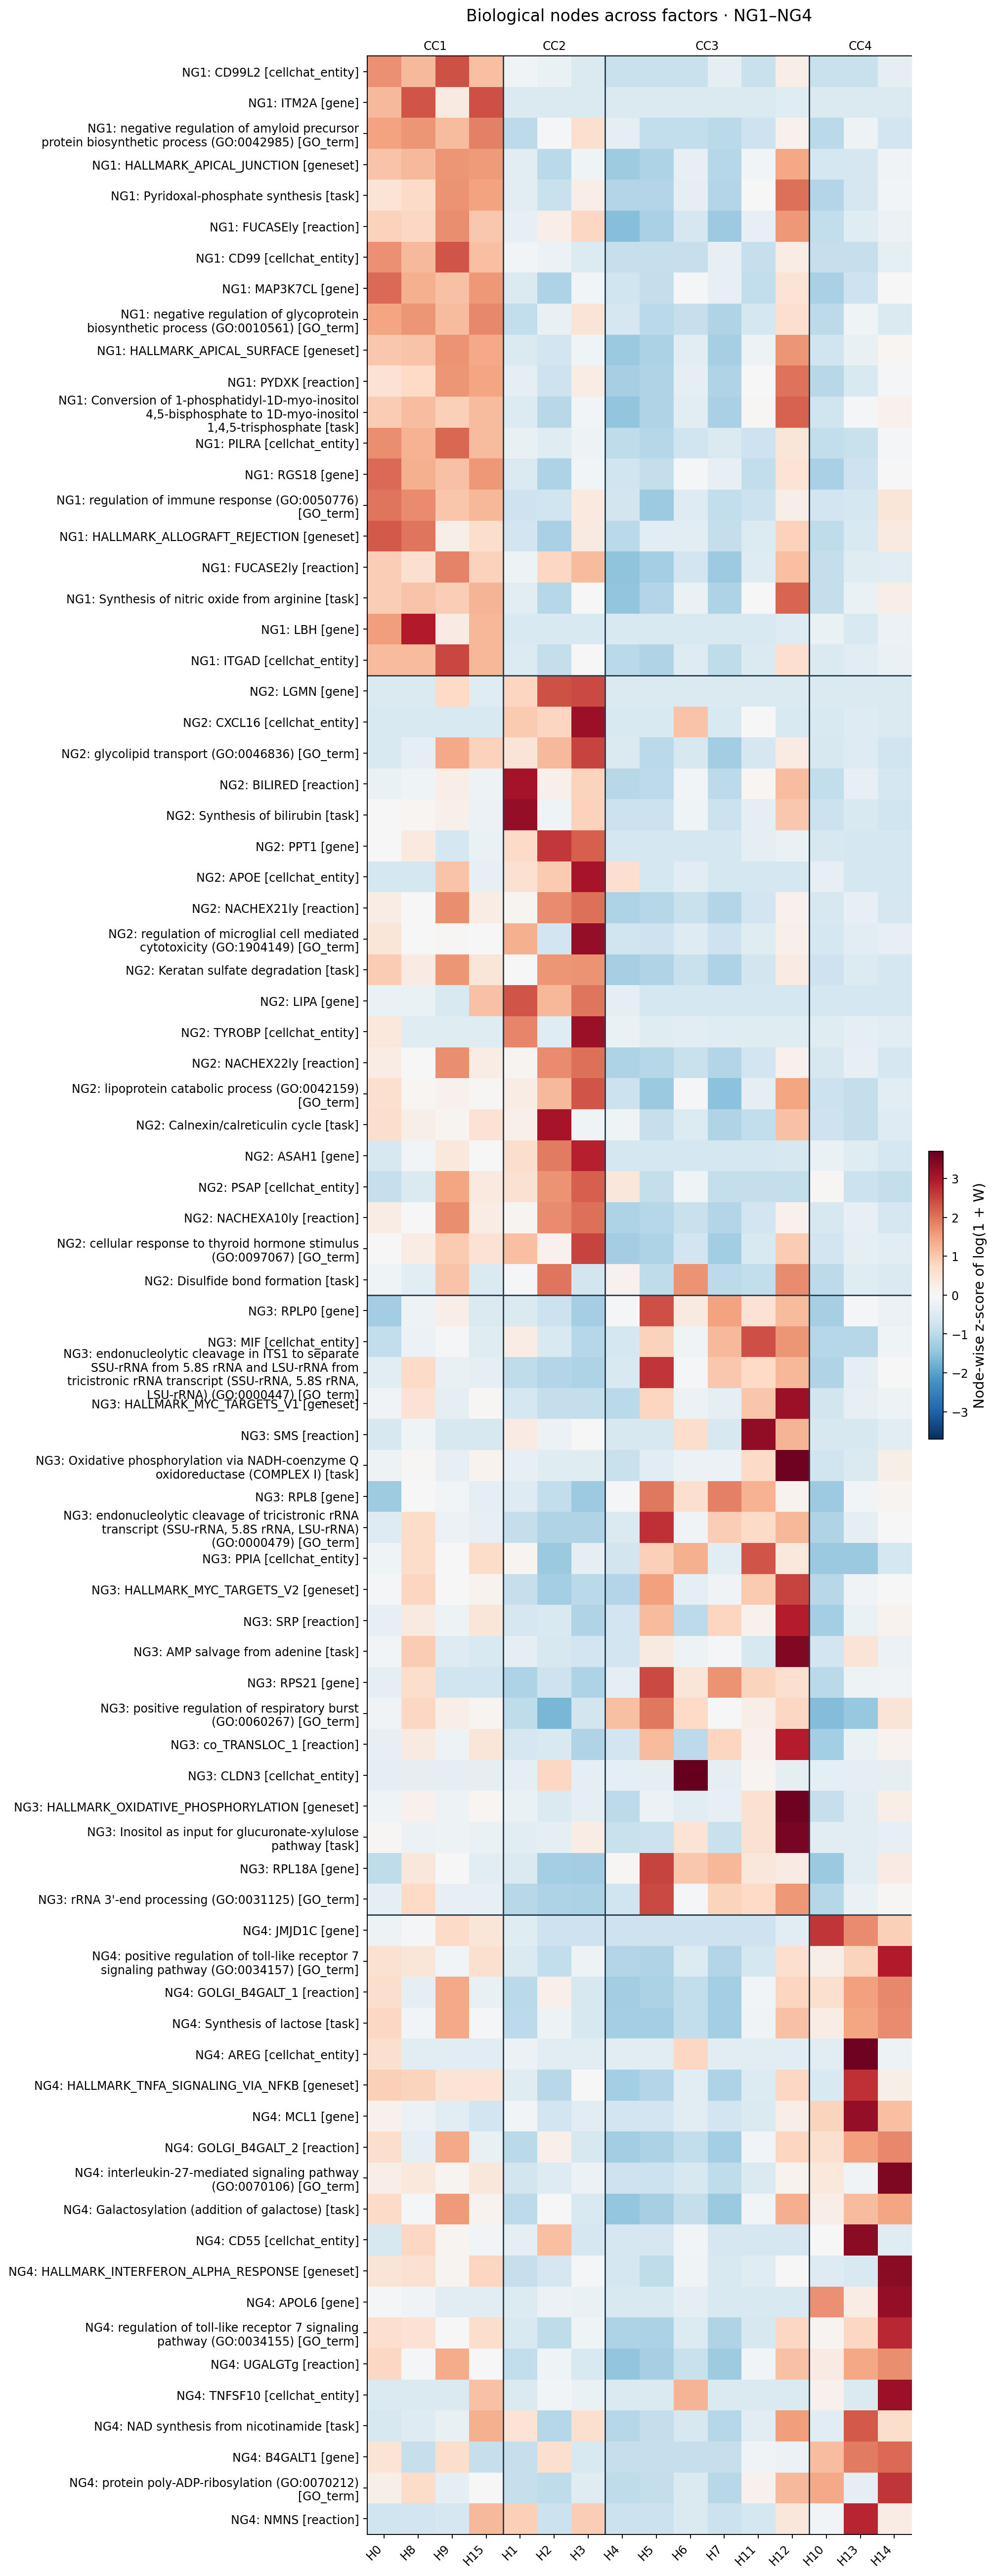

In [31]:
show_generated('factor_interpretation_k4/node_factors_all.png')

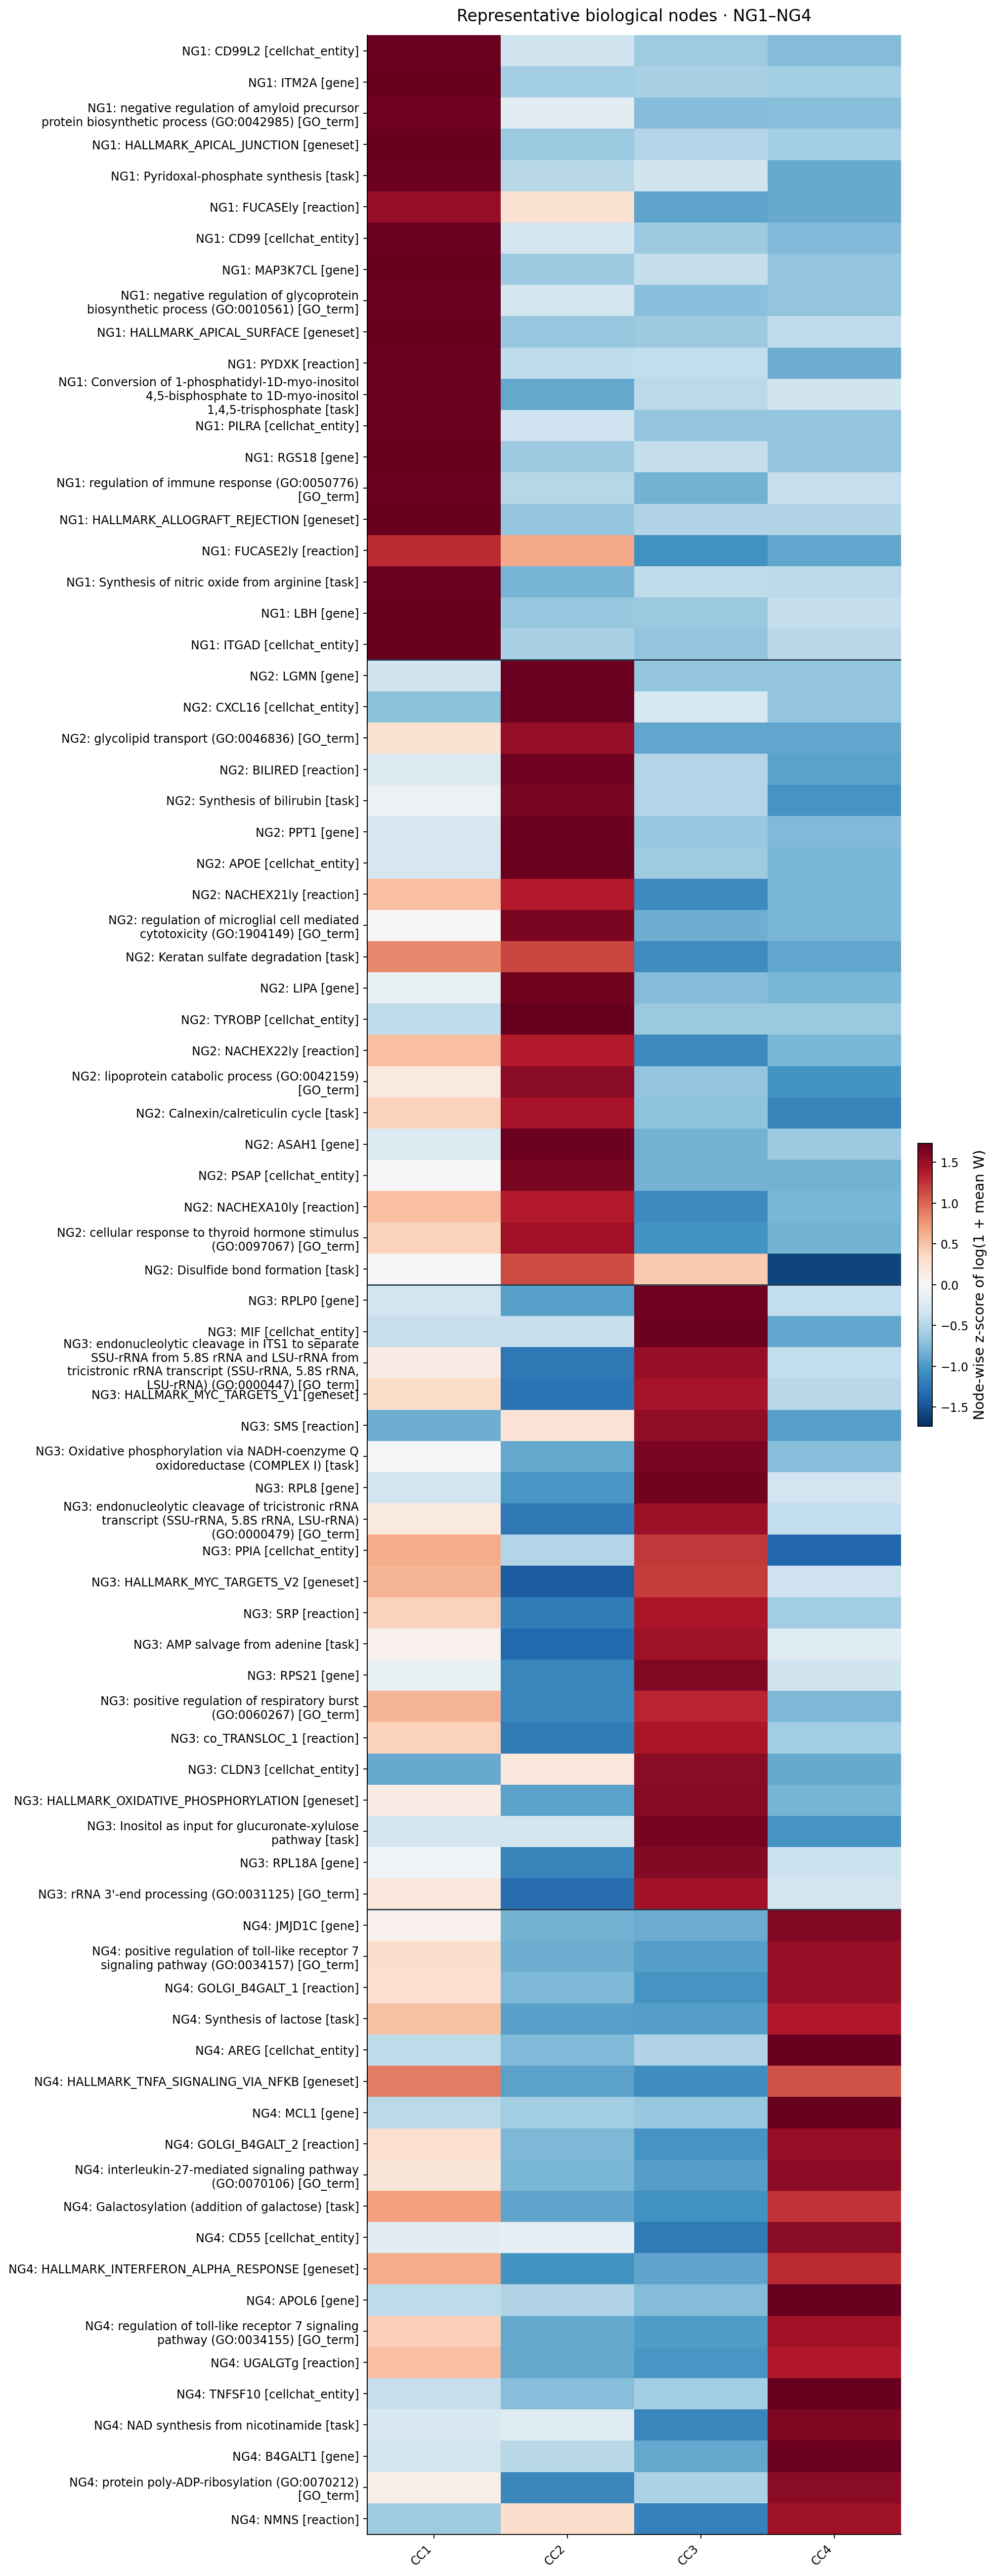

In [32]:
show_generated('factor_interpretation_k4/node_dictionary_all.png')

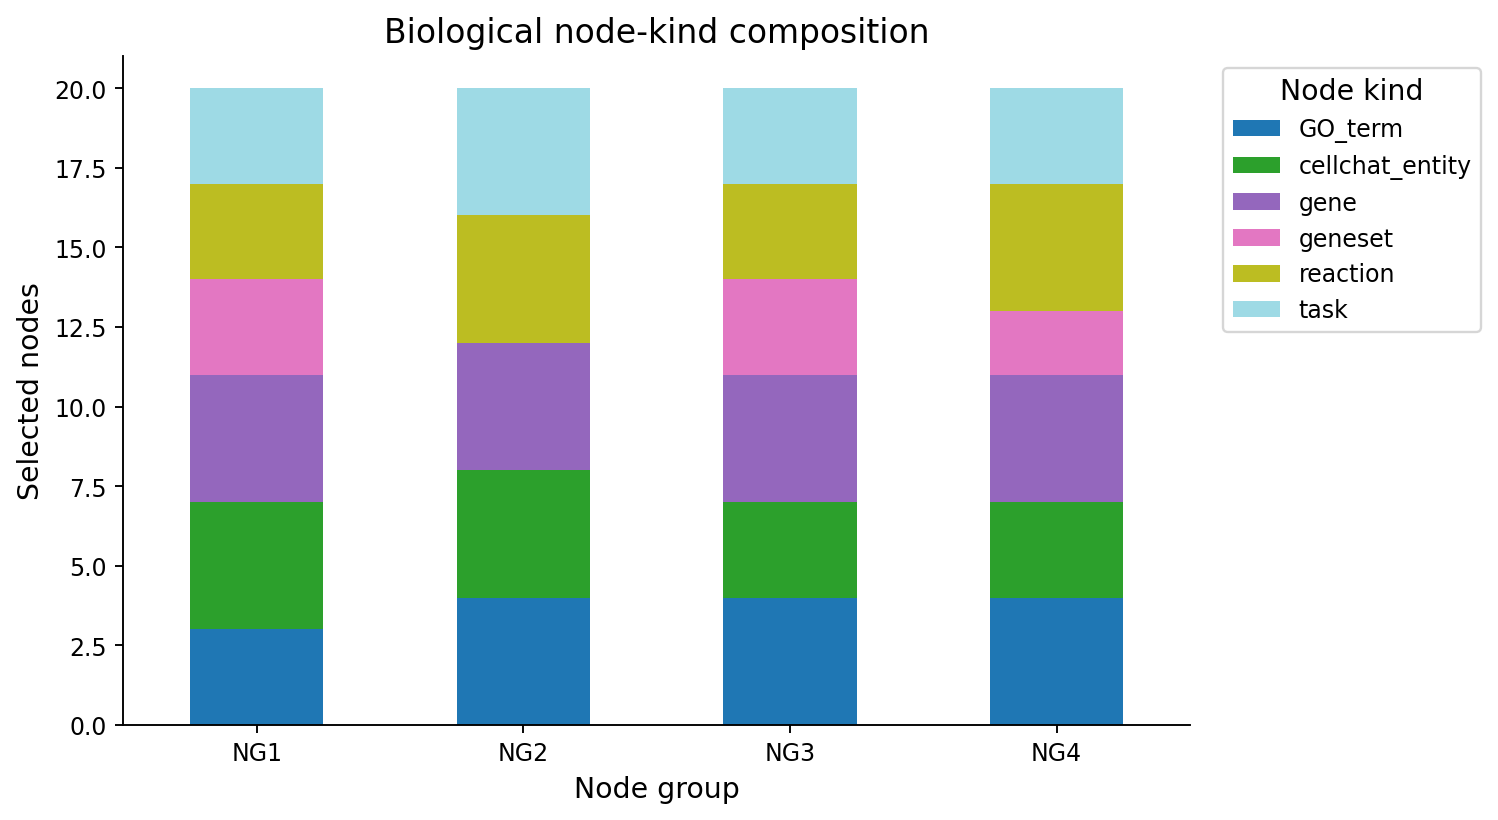

In [33]:
show_generated('factor_interpretation_k4/composition.png')

The first heatmap shows node-wise standardized loadings across all 16 factors; the second shows standardized mean loadings across the four CCs. Both use the same 80 nodes. These colors describe relative W loadings, not reconstructed cell activity. Use individual-factor profiles and exported enrichment values to assess differences in strength. The stacked bars count the selected node kinds; they do not measure activity or pathway flux.

## Examine category-specific loading profiles

Use gene sets as the worked example, showing the decay-selected nodes across all four programs. Uncomment the corresponding `entity_types.append(...)` line to generate the same view for genes, GO terms, reactions, metabolic tasks or CellChat entities. Rows are grouped by NG and columns by CC; divider lines mark the group boundaries. Node labels identify their NG membership. A group with no selected nodes of that type contributes no rows, while all factor groups remain visible.

In [34]:
# Select one entity type for the worked example.
entity_types = ['geneset']
# entity_types.append('gene')
# entity_types.append('GO_term')
# entity_types.append('reaction')
# entity_types.append('task')
# entity_types.append('cellchat_entity')
for kind in entity_types:
 rows=ranked[ranked.decay_selected & ranked.node_kind.eq(kind)]
 rows=rows.sort_values(['consensus_cluster','category_rank'])
 values=W_Z[W_ELIGIBLE.index.get_indexer(rows.node_name)][:,order]
 row_groups=rows.consensus_cluster.to_numpy()
 names=[textwrap.fill(f'{ngroups[g]}: {n}',52) for g,n in zip(row_groups,rows.node_name)]
 fig,ax=plt.subplots(figsize=(12,max(6,.36*len(rows)+2)))
 limit=max(float(np.abs(values).max()),1e-12)
 im=ax.imshow(values,aspect='auto',cmap='RdBu_r',vmin=-limit,vmax=limit)
 ax.set_yticks(range(len(rows)),names,fontsize=10)
 ax.set_xticks(range(16),[f'H{i}' for i in order],rotation=45,ha='right')
 for boundary in np.flatnonzero(np.diff(row_groups)!=0)+.5:
  ax.axhline(boundary,color='#273e50',lw=1.2)
 for boundary in np.flatnonzero(np.diff(labels[order])!=0)+.5:
  ax.axvline(boundary,color='#273e50',lw=1.2)
 top=ax.secondary_xaxis('top')
 centers=[np.flatnonzero(labels[order]==g).mean() for g in range(SELECTED_K)]
 top.set_xticks(centers,groups);top.tick_params(length=0)
 ax.set_title(f'{kind.replace("_"," ")} · all four programs',pad=30)
 ax.set_xlabel('Factors ordered by factor group')
 fig.colorbar(im,ax=ax,label='Node-wise z-score of log(1 + W)',fraction=.025,pad=.03)
 fig.tight_layout();save(f'category_all_{kind}')

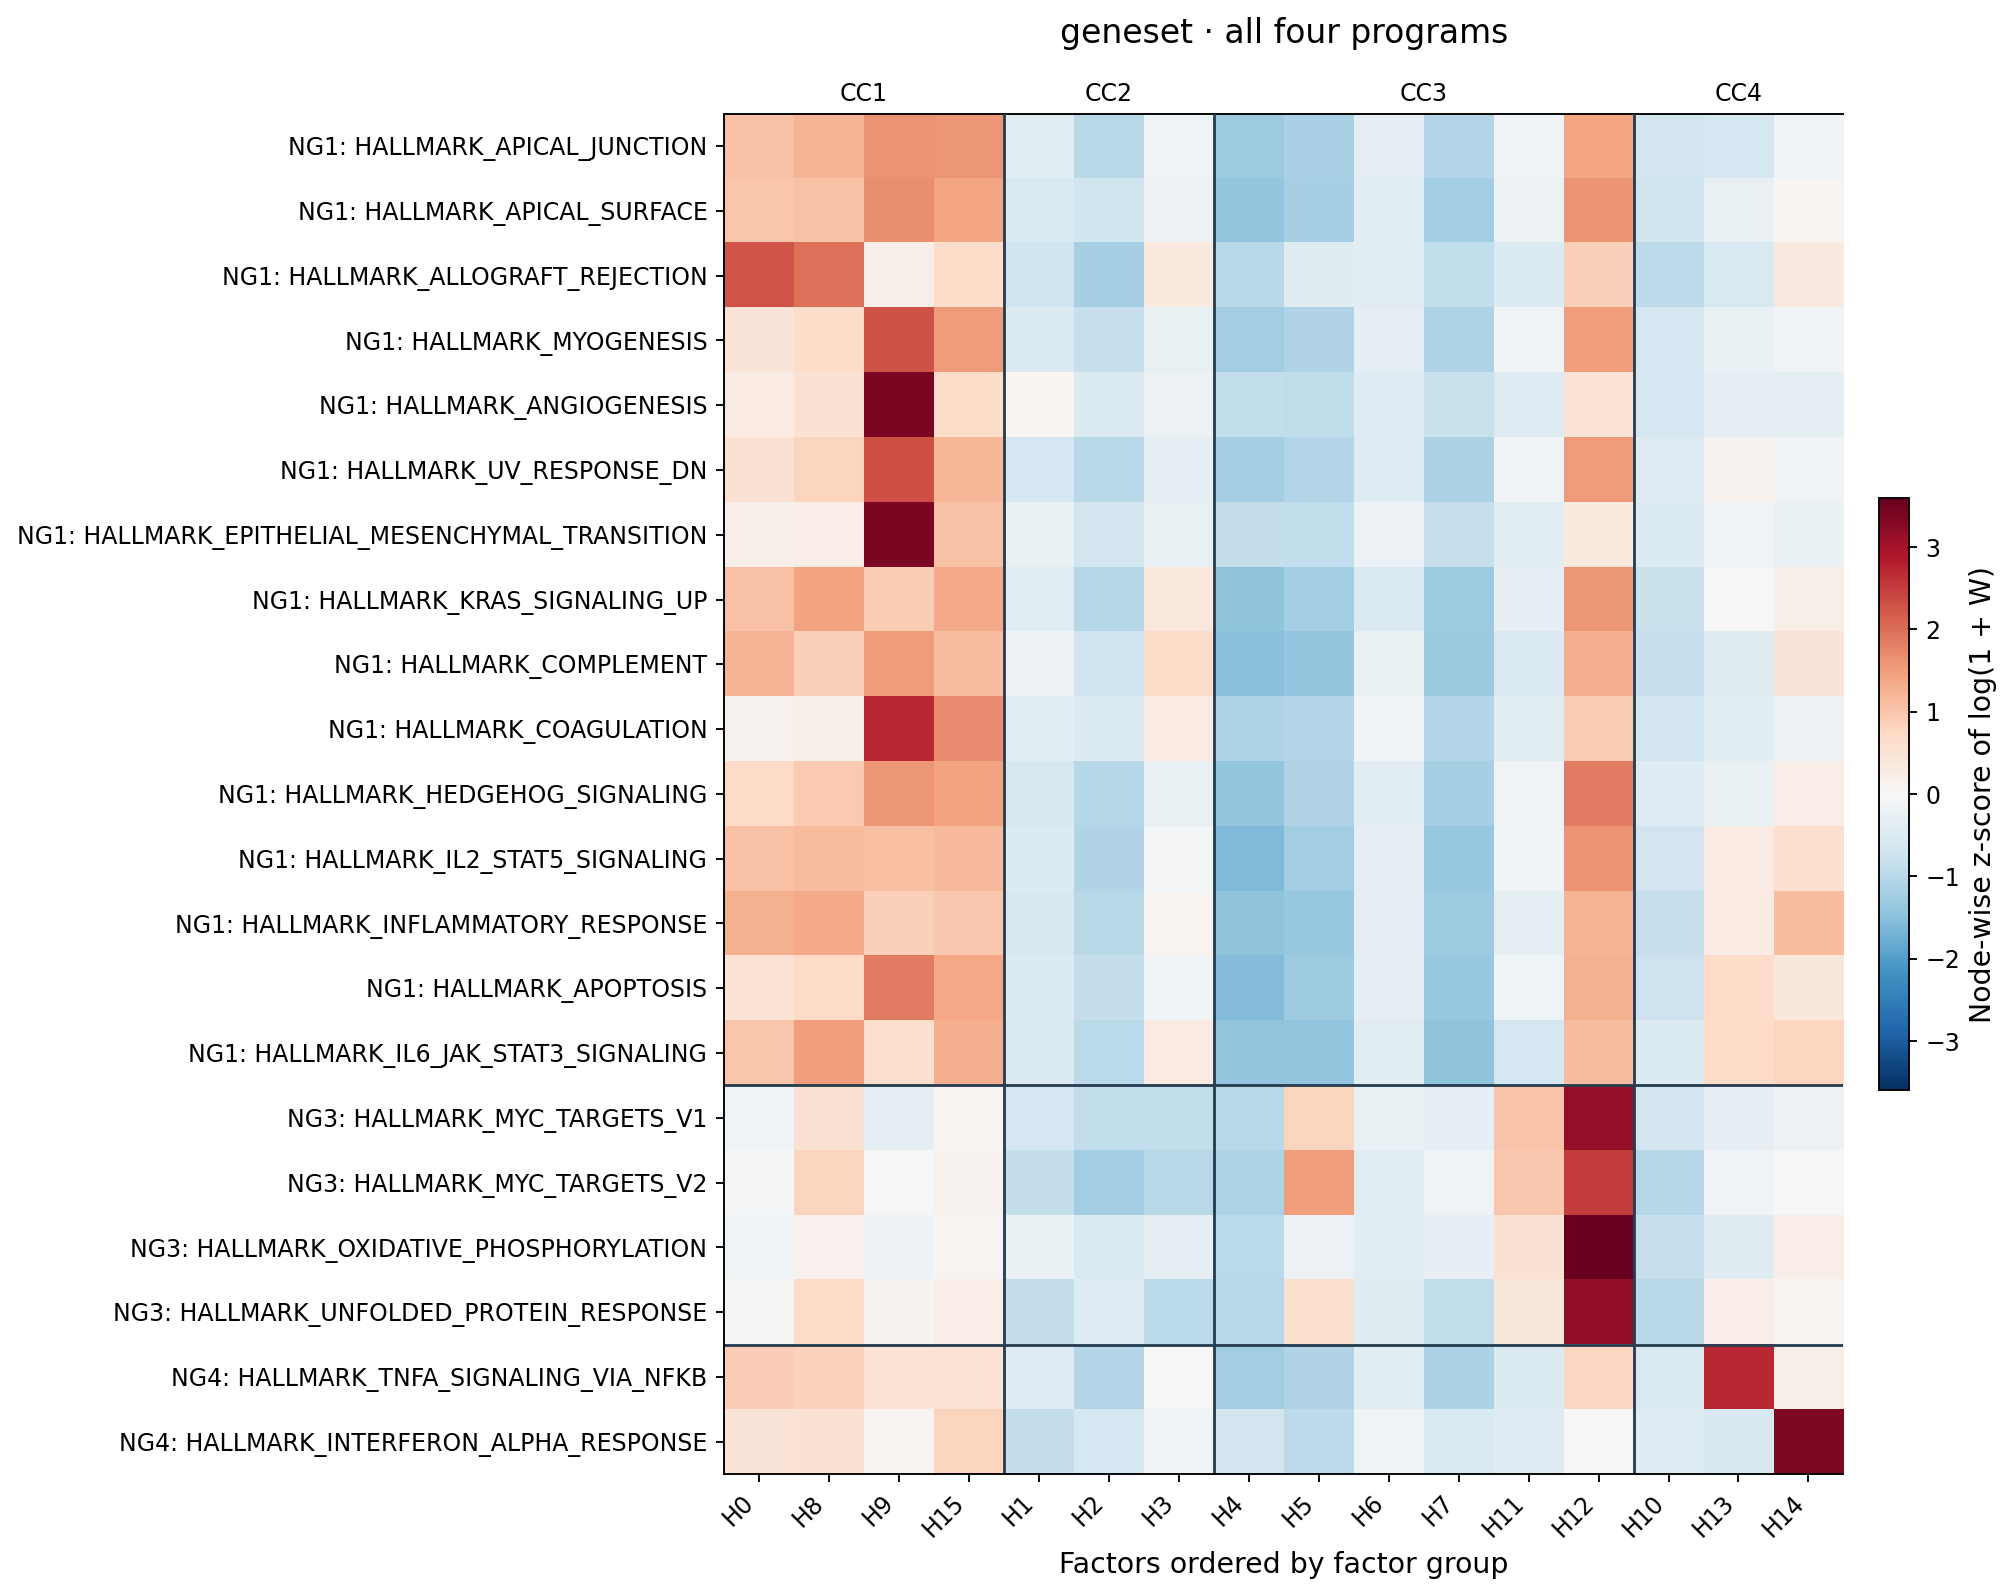

In [35]:
show_generated('factor_interpretation_k4/category_all_geneset.png')

This gene-set heatmap uses node-wise z-scores of log(1 + W) across factors. Selection here follows the per-category decay prefixes, so these lists can differ from the mixed 20-node dictionary. A graph term is an annotation of model loading; its name alone does not establish that a tissue-specific process occurs in these cells.

## Reconstruct NG activity and summarize CC activity

For each NG, average the raw W profiles of its selected nodes and multiply by H. For each CC, average the H columns assigned to that group. Then compute cell-type means and standardize log(1 + mean) across types within each row.

In [36]:
profiles=np.vstack([W[np.isin(nodes,selected.loc[selected.consensus_cluster==g,'node_name'])].mean(axis=0) for g in range(SELECTED_K)])
node_raw=H@profiles.T
factor_raw=np.column_stack([H[:,labels==g].mean(axis=1) for g in range(SELECTED_K)])
node_mean=pd.DataFrame(node_raw,index=a.obs_names,columns=ngroups).groupby(meta.cellType).mean().reindex(types).T
factor_mean=pd.DataFrame(factor_raw,index=a.obs_names,columns=groups).groupby(meta.cellType).mean().reindex(types).T
node_type=pd.DataFrame(row_z(node_mean),index=ngroups,columns=types)
factor_type=pd.DataFrame(row_z(factor_mean),index=groups,columns=types)
heat(node_type,'Reconstructed node-group activity','node_activity')
heat(factor_type,'Shared W–H factor-group activity','factor_activity')
node_mean.to_csv(OUT/'node_group_means.csv');factor_mean.to_csv(OUT/'factor_group_means.csv')

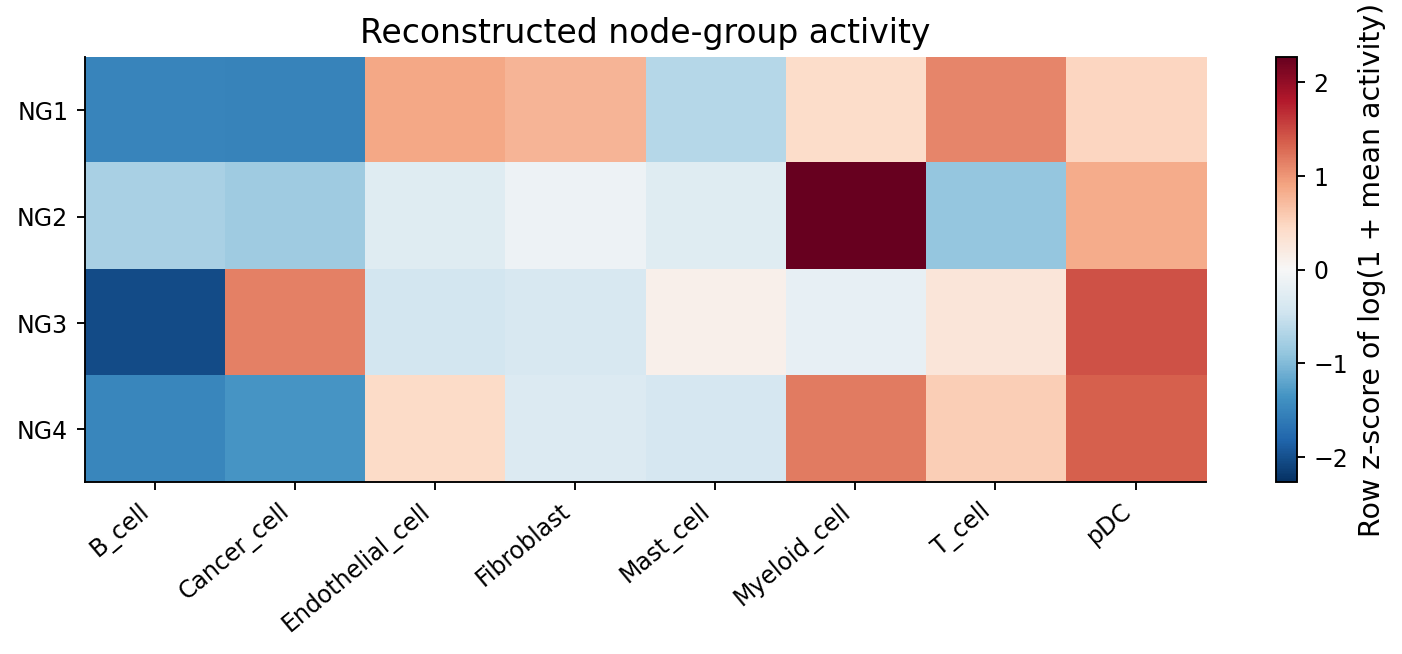

In [37]:
show_generated('factor_interpretation_k4/node_activity.png')

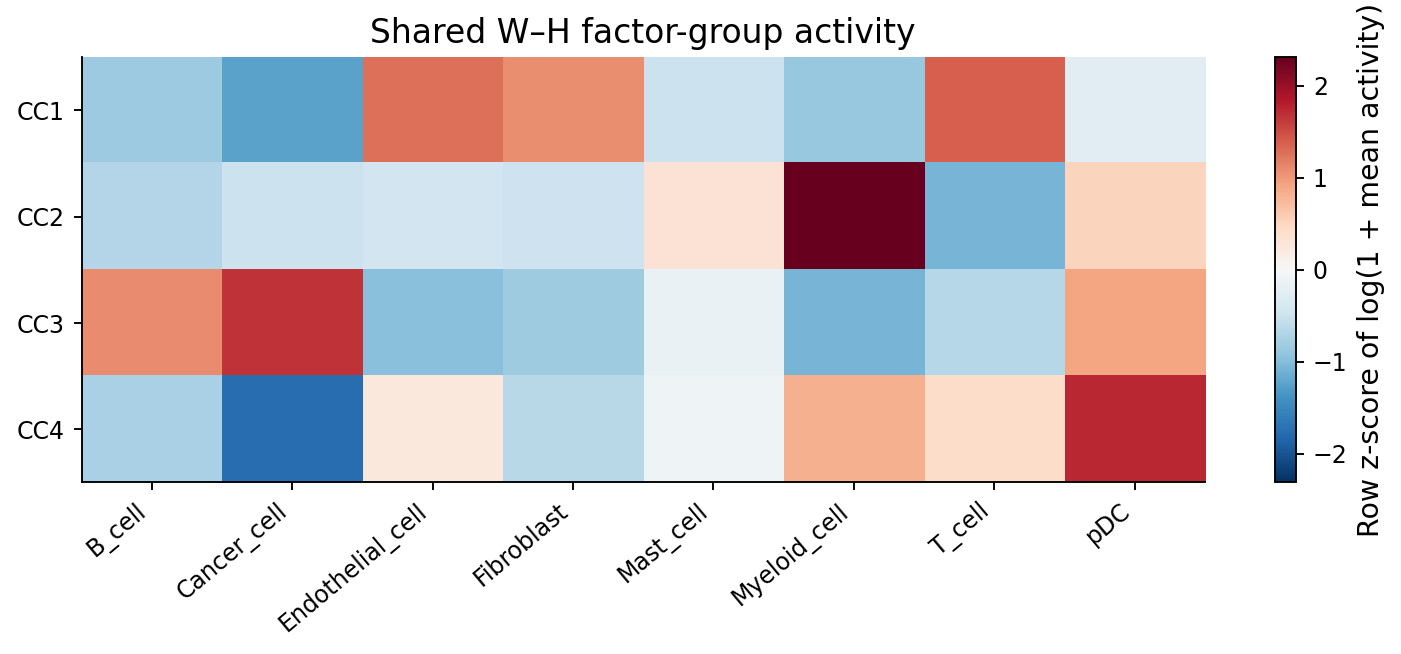

In [38]:
show_generated('factor_interpretation_k4/factor_activity.png')

The first plot shows reconstructed NG activity; the second shows CC usage. Warm colors indicate above-row-average activity across the displayed cell types. Reconstruction uses all factors, so an NG need not share the same activity pattern as its corresponding CC. 

## Connect node groups, factor groups and cell types

Connect NGs to CCs using mean standardized W summaries, and CCs to cell types using standardized mean H activity. Display all signed associations.

In [39]:
node_factor=pd.DataFrame(np.vstack([wz.loc[selected.loc[selected.consensus_cluster==g,'node_name']].mean(axis=0) for g in range(SELECTED_K)]),index=ngroups,columns=groups)
fig,ax=plt.subplots(figsize=(10,6))
ys=[np.linspace(0,1,len(x)) for x in [ngroups,groups,types]]
edges=[]
for layer,table in enumerate([node_factor,factor_type]):
 for i,src in enumerate(table.index):
  for j,dst in enumerate(table.columns):
   v=float(table.iloc[i,j]);edges.append({'source':src,'target':dst,'relative_score':v})
   ax.plot([layer,layer+1],[ys[layer][i],ys[layer+1][j]],color='#b24b55' if v>=0 else '#357eaa',lw=.3+2*abs(v),alpha=.38)
for x,names in enumerate([ngroups,groups,types]):
 ax.scatter([x]*len(names),ys[x],s=85,color='#273e50',zorder=3)
 for y,name in zip(ys[x],names):ax.text(x+.04,y,name,va='center',fontsize=11)
for x,title in enumerate(['W node groups','Shared factor groups','Source cell types']):ax.text(x,1.08,title,weight='bold')
ax.set_xlim(-.05,2.5);ax.set_ylim(-.06,1.15);ax.axis('off')
ax.legend(handles=[Patch(color='#b24b55',label='Positive relative score'),Patch(color='#357eaa',label='Negative relative score')],loc='lower center',bbox_to_anchor=(.5,-.12),ncol=2)
plt.tight_layout();save('associations');pd.DataFrame(edges).to_csv(OUT/'all_associations.csv',index=False)

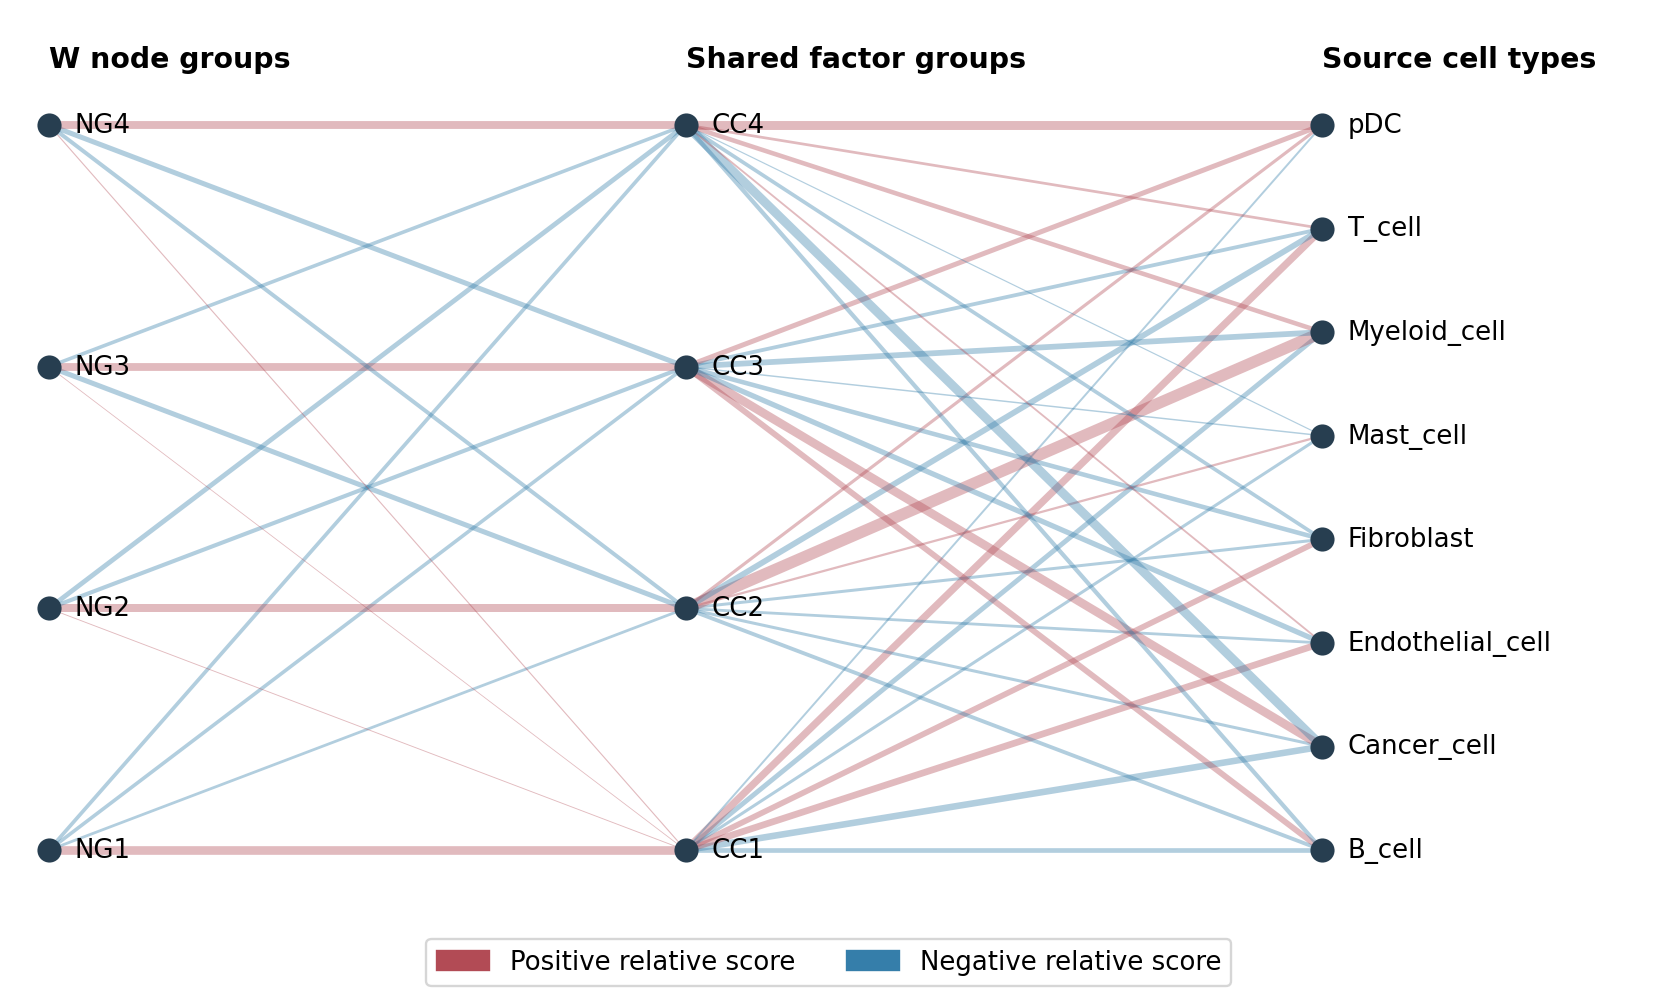

In [40]:
show_generated('factor_interpretation_k4/associations.png')

Red edges are positive relative scores and blue edges negative scores; width scales with absolute score. These are descriptive associations between model summaries, not causal links, cell–cell communication, probabilities or mass-conserving flows. `all_associations.csv` retains every value.

## View all 10,000 cells with metadata tracks

Order cells deterministically by source cell type, patient and timepoint. Standardize log(1 + NG activity) across cells separately for each NG.

In [41]:
logged=np.log1p(node_raw);cell_z=(logged-logged.mean(axis=0))/np.maximum(logged.std(axis=0),1e-12)
ordered=meta.sort_values(['cellType','patient_id','timepoint'],kind='stable').index
positions=a.obs_names.get_indexer(ordered)
fig,axes=plt.subplots(4,1,figsize=(11,6),gridspec_kw={'height_ratios':[.25,.25,.25,3]},layout='constrained')
legend=[]
for ax,key in zip(axes[:3],['cellType','patient_id','timepoint']):
 cats=sorted(meta[key].unique());codes=pd.Categorical(meta.loc[ordered,key],categories=cats).codes
 ax.imshow(codes[None,:],aspect='auto',cmap='tab20',vmin=0,vmax=19);ax.set_yticks([0],[key]);ax.set_xticks([])
 for j,c in enumerate(cats):legend.append(Patch(color=plt.get_cmap('tab20')(j),label=f'{key}: {c}'))
im=axes[-1].imshow(cell_z[positions].T,aspect='auto',cmap='RdBu_r',vmin=-2.5,vmax=2.5)
axes[-1].set_yticks(range(SELECTED_K),ngroups);axes[-1].set_xlabel('All 10,000 cells · ordered by cell type, patient and timepoint')
fig.colorbar(im,ax=axes[-1],label='Per-group z-score of log(1 + activity)')
fig.legend(handles=legend,loc='outside lower center',ncol=4,fontsize=9);save('all_cells')

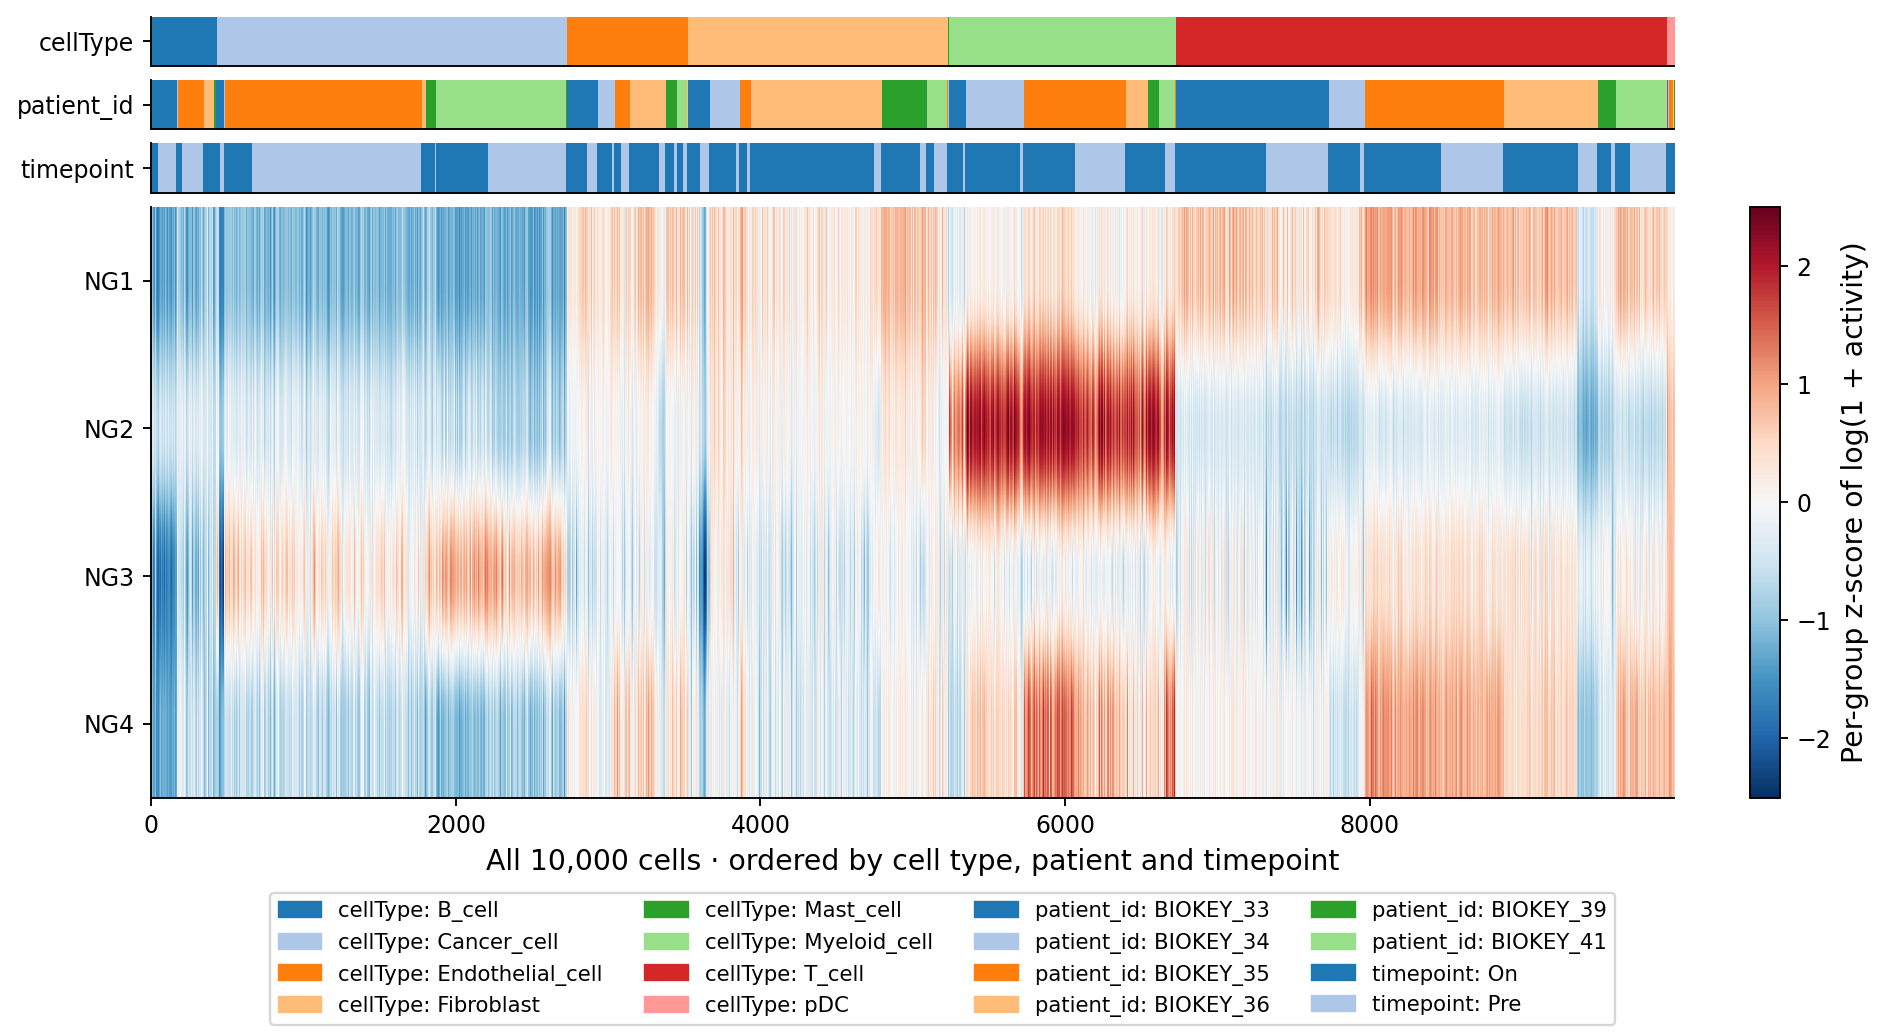

In [42]:
show_generated('factor_interpretation_k4/all_cells.png')

Every column represents one of the same 10,000 cells. Metadata strips identify the ordering; the activity color scale is clipped at ±2.5 for display only. This view reveals within-type heterogeneity hidden by mean summaries. The x-axis is an ordering, not pseudotime.

## Check patient representation and summarize selected constituents

Show sample coverage before inspecting constituent distributions. For a reproducible descriptive illustration, the violin plots use the first three ranked nodes in NG1; they are not selected using a clinical outcome or a significance test.

In [43]:
coverage=pd.crosstab(meta.cellType,meta.patient_id).reindex(types)
heat(coverage,'Cells available per patient and cell type','coverage','Number of cells',False)
# A declared descriptive display: first three nodes from NG1's ranked dictionary.
chosen=selected[selected.consensus_cluster==0].head(3).node_name.tolist()
fig,axes=plt.subplots(1,3,figsize=(12,5))
for ax,node in zip(axes,chosen):
 score=np.log1p(H@W[np.flatnonzero(nodes==node)[0]])
 ax.violinplot([score[meta.cellType.to_numpy()==t] for t in types],showmedians=True)
 ax.set_xticks(range(1,len(types)+1),types,rotation=60,ha='right');ax.set_title(textwrap.fill(node,28),fontsize=11)
 ax.set_ylabel('log(1 + reconstructed node activity)')
plt.tight_layout();save('constituents')
summary={'cells':a.n_obs,'factors':16,'selected_k':SELECTED_K,'group_sizes':np.bincount(labels).tolist(),'bootstraps':BOOTSTRAPS,'selected_nodes':len(selected),'seconds':time.time()-START,'cell_id_sha256':hashlib.sha256('\n'.join(a.obs_names).encode()).hexdigest()}
(OUT/'summary.json').write_text(json.dumps(summary,indent=2));print(summary,flush=True)

{'cells': 10000, 'factors': 16, 'selected_k': 4, 'group_sizes': [4, 3, 6, 3], 'bootstraps': 200, 'selected_nodes': 80, 'seconds': 12.618005990982056, 'cell_id_sha256': 'a47ad5d98b131c0e47129c7657dcc35515c675cddd510c60e89f986c21212d63'}


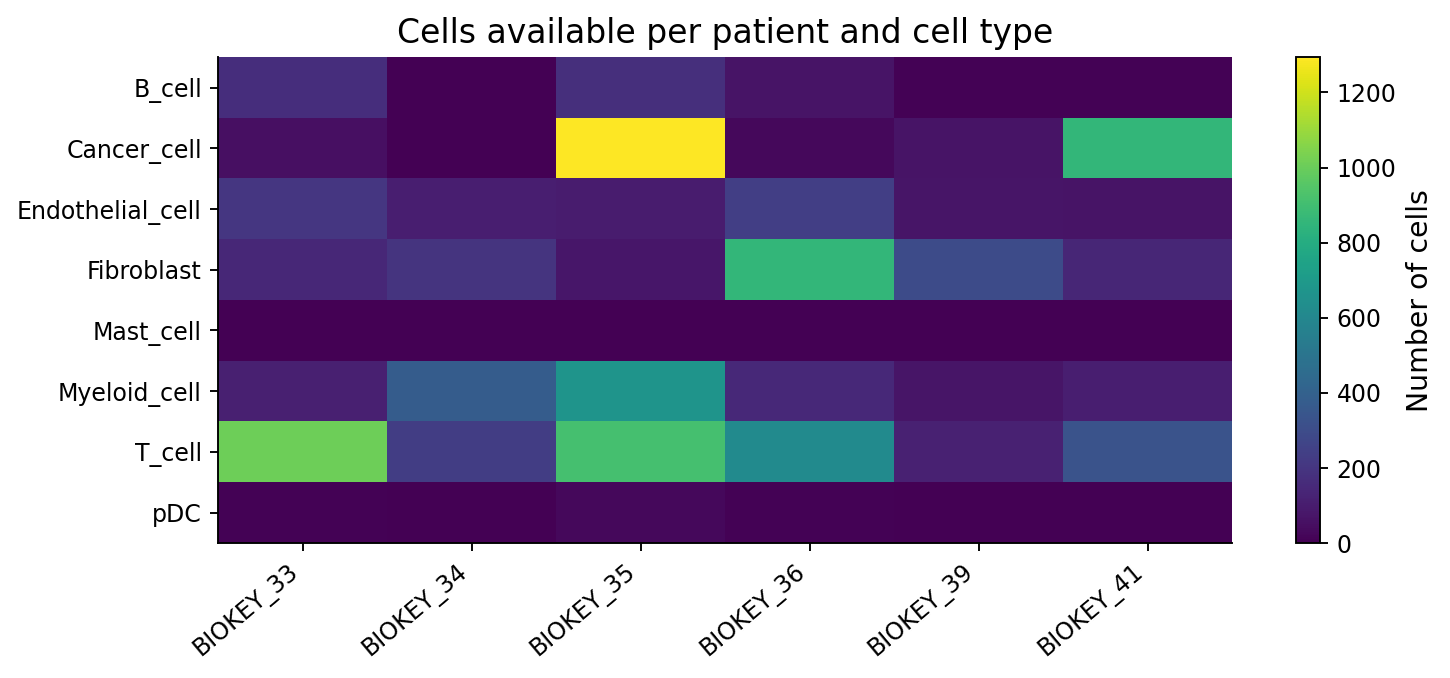

In [44]:
show_generated('factor_interpretation_k4/coverage.png')

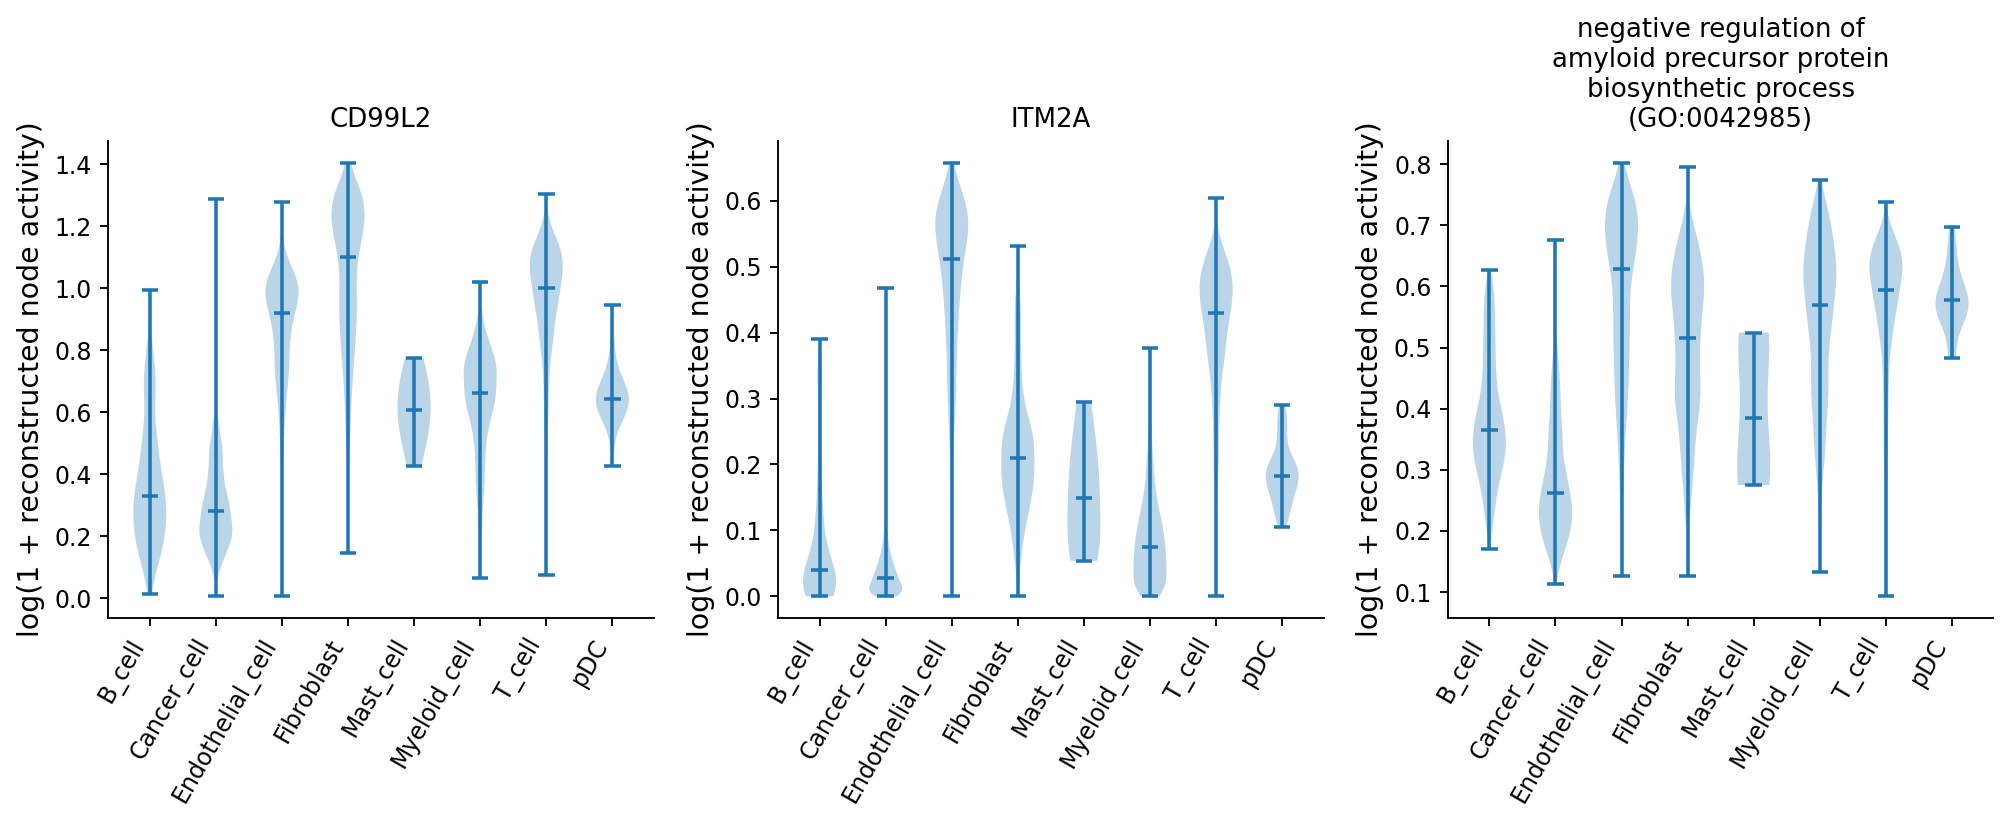

In [45]:
show_generated('factor_interpretation_k4/constituents.png')

Coverage counts show where patient representation is uneven. Violin plots show log-transformed reconstructed activity for individual constituents, with medians. Cells are pooled within source cell type; these distributions are descriptive and do not establish a patient-level treatment effect. Sparse types, including seven mast cells, have limited distributional resolution.

## Outputs and next step

The `factor_interpretation_k4/` output folder contains the consensus diagnostics, factor assignments, selected-node dictionary, node-selection audit, group means, signed associations, run summary and regenerated figures. The groups and activity profiles summarize this 10,000-cell fit.

Continue to [cell–cell signaling](../docs/tutorials/10000-signaling.md).

# Cell–cell signaling



Explore activity-based signaling in seven steps: **communication overview → sender/receiver roles → ligand–receptor contributions → permutation FDR → network organization → VEGF → On-minus-Pre differences**.

Run the code blocks in order in one Python session from the repository root, after fitting and activity reconstruction. Every analysis uses the same 10,000 cells and source `cellType` metadata. Scores are activity-based proxies, not CellChat communication probabilities or direct measurements of signaling. [Download the complete runnable script](../docs/downloads/signaling_walkthrough.py).

Set `SCKNIFE_INTERACTION_DB` to the directional interaction export described in [Input files](../docs/tutorial-inputs.md). The interaction export supplies directional ligand–receptor definitions alongside the fitted activities.

## Load and validate signaling inputs

In [46]:
"""Descriptive signaling for the fitted 10,000 cells; no patient or condition tests."""
import os,time,json,hashlib,resource,textwrap
from pathlib import Path
os.environ['MPLBACKEND']='Agg'
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

# Consistent, readable figure typography.
plt.rcParams.update({"font.size": 12, "axes.titlesize": 14,
                     "axes.labelsize": 12, "xtick.labelsize": 11,
                     "ytick.labelsize": 11, "legend.fontsize": 11,
                     "figure.titlesize": 15, "axes.spines.top": False,
                     "axes.spines.right": False})
from scknife.signaling import activity_lr as lr
from scknife.signaling import common
start=time.perf_counter()
root=Path.cwd();base=Path(os.environ.get('SCKNIFE_TUTORIAL_OUTPUT', root/'tutorial/outputs_10000'));out=base/'signaling';out.mkdir(exist_ok=True)
db_path=Path(os.environ['SCKNIFE_INTERACTION_DB'])
for mod in (lr,common):
 mod.ACTIVITY_PATH=base/'activity_scores.parquet';mod.CELLCHAT_DB_PATH=db_path
adata=sc.read_h5ad(base/'fitted_subset.h5ad')
assert adata.n_obs==10000
metadata=adata.obs.copy();key='cellType'
assert key in metadata and not metadata[key].isna().any()
db,wanted=lr.load_interactions()
_,nodes,cells=lr.activity_schema()
assert cells==list(adata.obs_names)
values,genes,coverage=lr.stream_activity_subset(wanted,nodes,cells,256)
groups=sorted(metadata[key].astype(str).unique());assert len(groups)>1
labels=metadata[key].astype(str).map({g:i for i,g in enumerate(groups)}).to_numpy(dtype=np.int16)
means,counts=lr.group_means(values,labels,len(groups));specificity=means/(means.mean(axis=1)[:,None]+1e-10)
pairs=lr.build_pairs(db,genes,means);error=lr.validate_vectorization(means,specificity,pairs)
comm=lr.communication_matrix(means,specificity,pairs);assert np.isfinite(comm).all() and (comm>=0).all()
details=lr.interaction_details(means,specificity,pairs,groups)
reconstructed=details.pivot_table(index='source',columns='target',values='weighted_score',aggfunc='sum',fill_value=0).reindex(index=groups,columns=groups,fill_value=0)
assert np.allclose(comm,reconstructed.to_numpy(),rtol=1e-10,atol=1e-10)
pd.DataFrame(comm,index=groups,columns=groups).to_csv(out/'communication_matrix.csv')
details.to_csv(out/'interaction_details.csv.gz',index=False,compression='gzip')
pd.DataFrame({'reference_cell_type':groups,'cells':counts}).to_csv(out/'group_counts.csv',index=False)
pairs.to_csv(out/'matched_interaction_components.csv',index=False)

  activity columns 256/10,000


  activity columns 512/10,000


  activity columns 768/10,000


  activity columns 1,024/10,000


  activity columns 1,280/10,000


...

  activity columns 9,216/10,000


  activity columns 9,472/10,000


  activity columns 9,728/10,000


  activity columns 9,984/10,000


  activity columns 10,000/10,000


Cell order is checked against the saved fit. Interaction-level scores must sum to the group communication matrix. Scores use group means and group-normalized specificity. Seven mast cells and 55 pDCs are retained; their small populations limit the stability of pooled summaries.

## 1. Sender–receiver activity heatmap

In [47]:
fig,ax=plt.subplots(figsize=(7,6));im=ax.imshow(comm,cmap='viridis',aspect='auto')
ax.set_xticks(range(len(groups)));ax.set_xticklabels([textwrap.fill(g,16) for g in groups],rotation=35,ha='right')
ax.set_yticks(range(len(groups)));ax.set_yticklabels([textwrap.fill(g,20) for g in groups])
ax.set_xlabel('Receiver source cell type');ax.set_ylabel('Sender source cell type')
ax.set_title('Descriptive communication scores · 10,000 cells');fig.colorbar(im,ax=ax,label='Weighted activity score')
fig.tight_layout();fig.savefig(out/'signaling_heatmap.png',dpi=160,bbox_inches='tight');plt.close(fig)

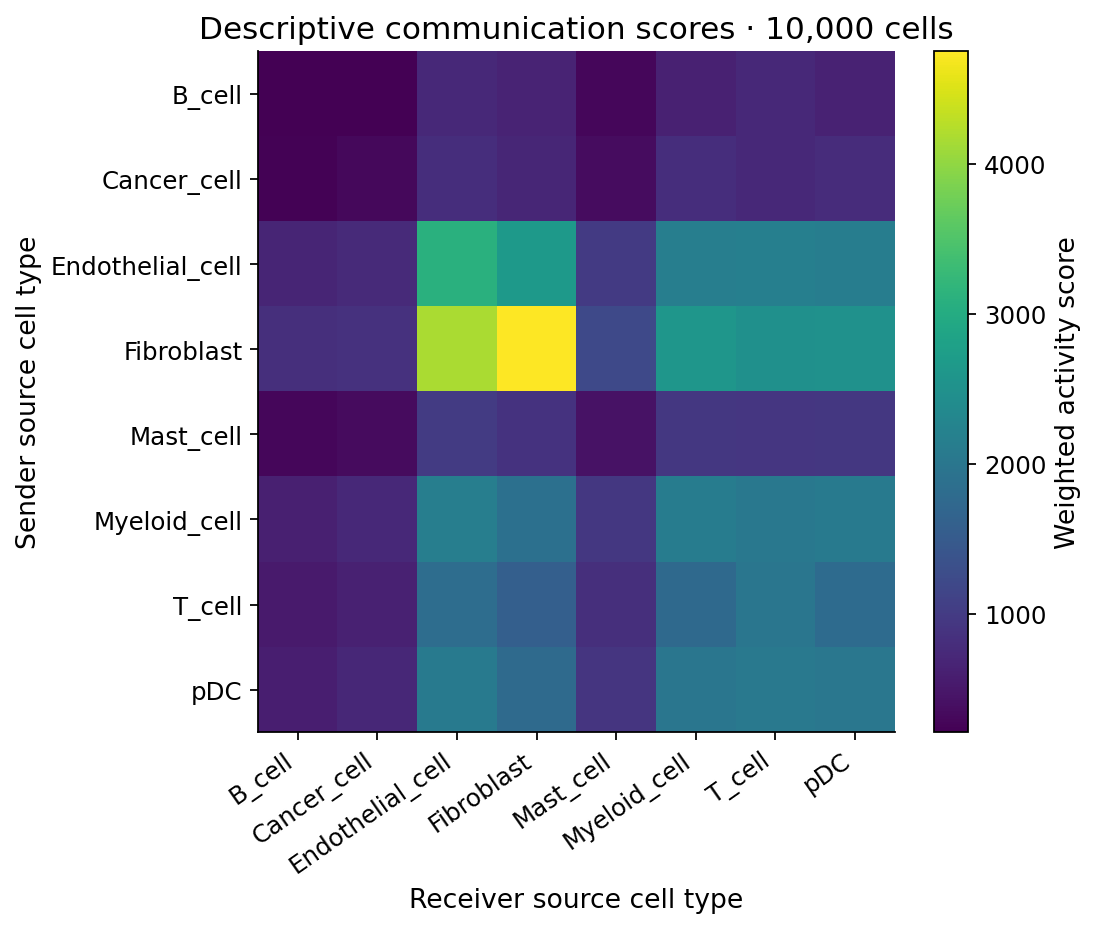

In [48]:
show_generated('signaling/signaling_heatmap.png')

Rows represent sender cell types and columns represent receivers. Color shows the sum of weighted interaction scores, including self-links. Higher scores indicate stronger activity-based support under this model; they do not indicate statistical significance.

## 2. Outgoing and incoming signaling strength

In [49]:
from scknife.signaling import plotting as plots

# Consistent, readable figure typography.
plt.rcParams.update({"font.size": 12, "axes.titlesize": 14,
                     "axes.labelsize": 12, "xtick.labelsize": 11,
                     "ytick.labelsize": 11, "legend.fontsize": 11,
                     "figure.titlesize": 15, "axes.spines.top": False,
                     "axes.spines.right": False})
plots.NODE_LABEL_SIZE_PT = 11
plots.TOP_LR_PAIRS = 15
plots.OUTPUT_DPI = 180
comm = pd.DataFrame(comm, index=groups, columns=groups)
general = out / 'general'

plots.plot_sender_receiver(comm, general)
# plots.plot_flow(comm, general)  # Optional dominant-flow view.

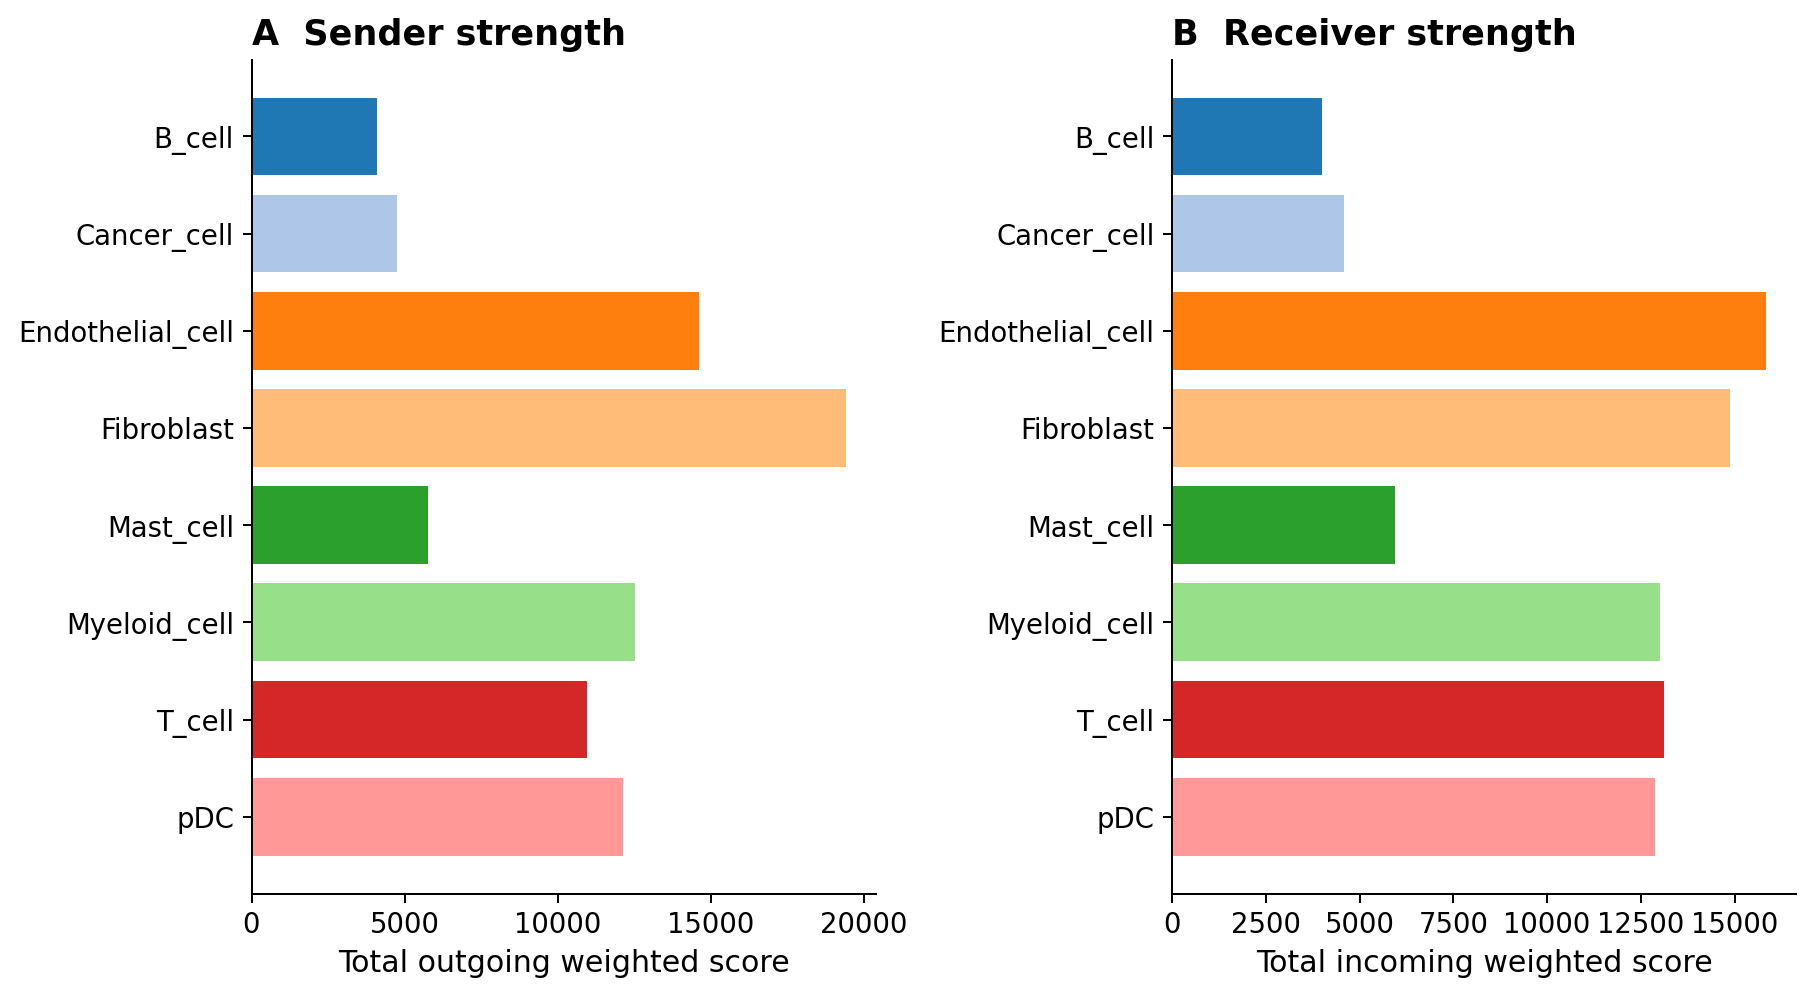

In [50]:
show_generated('signaling/general/01_sender_receiver.png')

Outgoing strength sums each row of the communication matrix; incoming strength sums each column. Both include self-links. These summarize scores rather than cell counts and identify prominent senders and receivers under the scoring model.

## 3. Ligand–receptor contributions

In [51]:
# Aggregate database components with identical ligand/receptor labels for display.
totals=details.groupby(['ligand','receptor'],sort=True).weighted_score.sum().sort_values(ascending=False,kind='stable').head(10)
contexts=details.groupby(['source','target'],sort=True).weighted_score.sum().sort_values(ascending=False,kind='stable').head(6)
agg=details.groupby(['ligand','receptor','source','target'],sort=True).weighted_score.sum()
rows=[]
for y,(lig,rec) in enumerate(totals.index):
 for x,(sender,receiver) in enumerate(contexts.index):
  score=float(agg.get((lig,rec,sender,receiver),0))
  rows.append(dict(ligand=lig,receptor=rec,source=sender,target=receiver,score=score,x=x,y=y))
bubbles=pd.DataFrame(rows);bubbles.to_csv(out/'selected_lr_bubbles.csv',index=False)
fig,ax=plt.subplots(figsize=(10,8));positive=bubbles[bubbles.score>0];sizes=280*positive.score/positive.score.max()
scat=ax.scatter(positive.x,positive.y,s=sizes,c=np.log1p(positive.score),cmap='viridis',edgecolors='gray',linewidths=.3)
ax.set_xticks(range(len(contexts)));ax.set_xticklabels([textwrap.fill(a,17)+'\n→\n'+textwrap.fill(b,17) for a,b in contexts.index],fontsize=11)
ax.set_yticks(range(len(totals)));ax.set_yticklabels([a+' → '+b for a,b in totals.index],fontsize=11);ax.invert_yaxis()
ax.set_xlabel('Sender → receiver source cell types');ax.set_ylabel('Ligand → receptor component')
ax.set_title('Top 10 ligand–receptor components in 6 strongest group pairs')
fig.colorbar(scat,ax=ax,label='log(1 + weighted score)')
fig.text(.5,.01,'Bubble area is proportional to weighted score; no significance test is shown.',ha='center',fontsize=11)
fig.tight_layout(rect=(0,.04,1,1));fig.savefig(out/'signaling_lr_bubbles.png',dpi=160,bbox_inches='tight');plt.close(fig)
# plots.plot_bubble(details, groups, general)  # Alternative group-pair overview.
# plots.plot_top_lr(details, general)  # Alternative pooled ligand–receptor ranking.

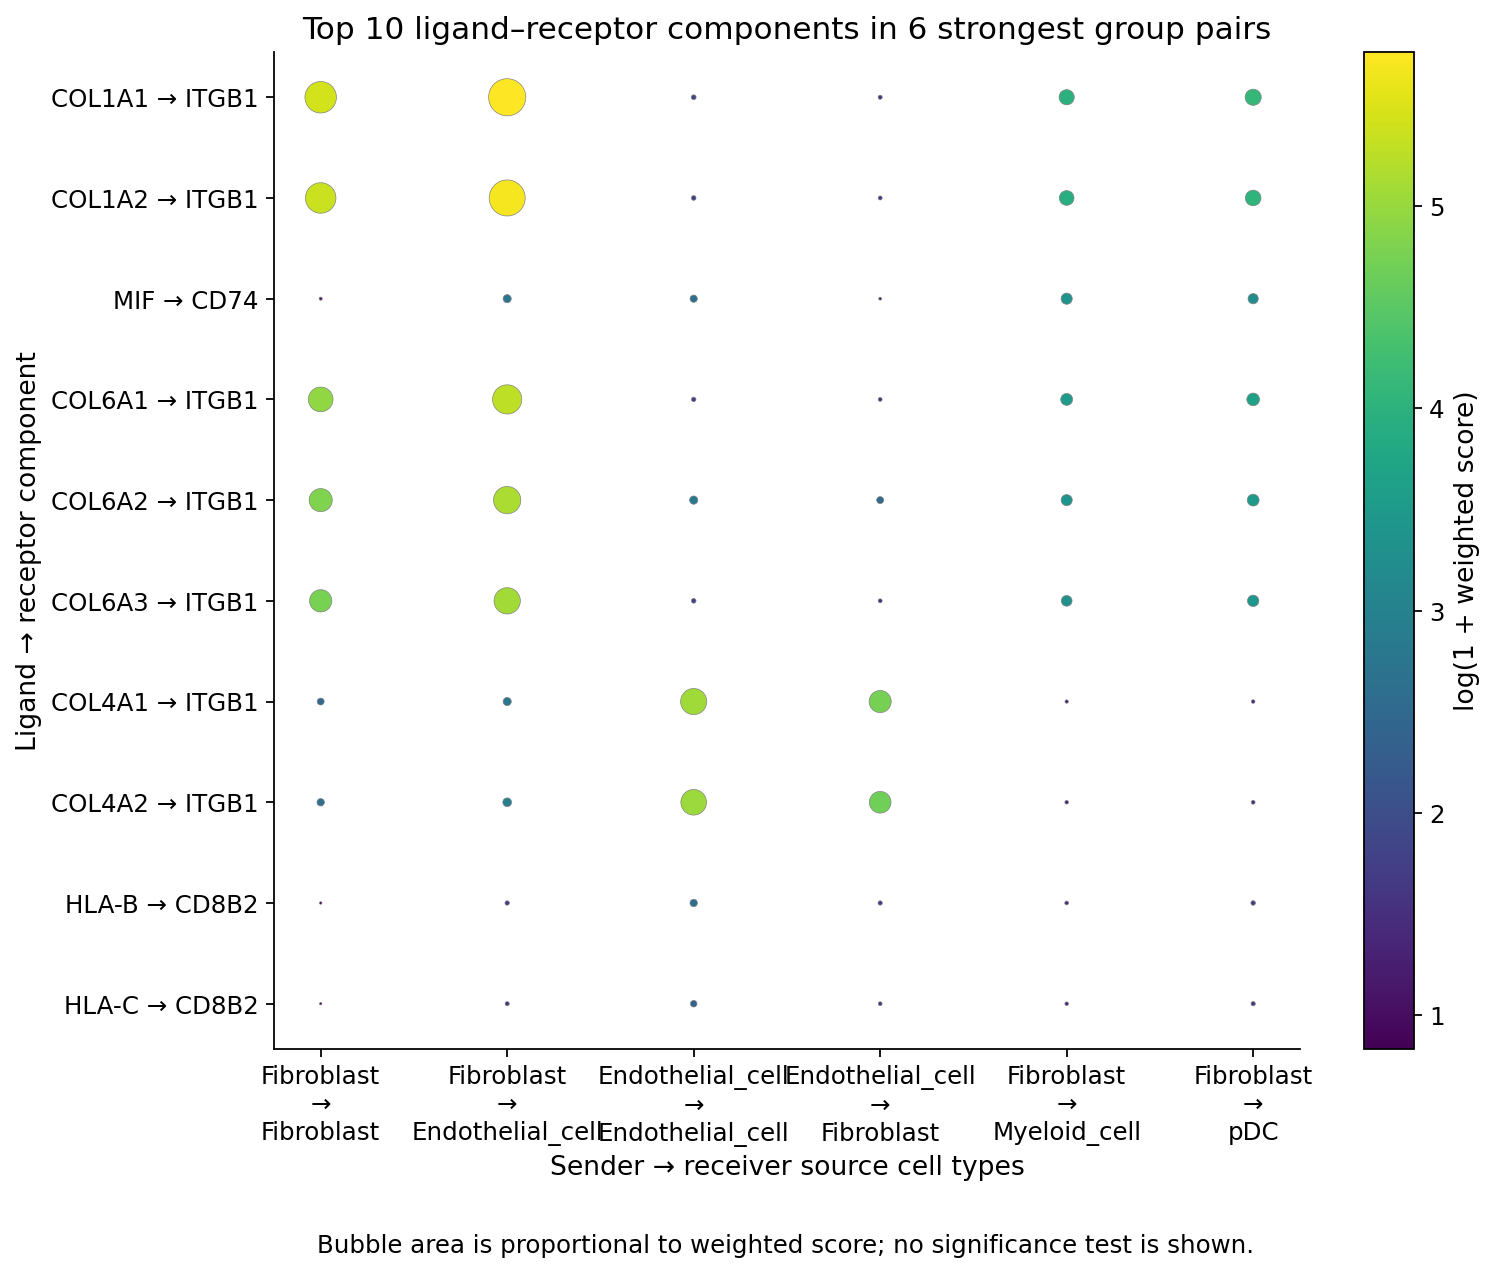

In [52]:
show_generated('signaling/signaling_lr_bubbles.png')

The ten highest-scoring ligand–receptor components and six strongest sender–receiver contexts are selected by pooled score. Bubble area represents score and color represents log(1 + score); neither represents FDR. The plot identifies interactions contributing to the group-level summaries.

## 4. Cell-label permutation FDR

Run or resume 1,000 global cell-label permutations with observed specificity held fixed. The null preserves group sizes. Apply Benjamini–Hochberg correction across all 64 sender–receiver pairs.

In [53]:
from pathlib import Path
import os,json,hashlib
import numpy as np
import pandas as pd
import scanpy as sc
import networkx as nx
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from statsmodels.stats.multitest import multipletests
from scknife.signaling import activity_lr as lr, common
base=Path(os.environ.get('SCKNIFE_TUTORIAL_OUTPUT','tutorial/outputs_10000'))
out=base/'signaling'/'inference';out.mkdir(parents=True,exist_ok=True)
for mod in (lr,common):
 mod.ACTIVITY_PATH=base/'activity_scores.parquet'
 mod.CELLCHAT_DB_PATH=Path(os.environ['SCKNIFE_INTERACTION_DB'])
 mod.DATA_DIR=out
adata=sc.read_h5ad(base/'fitted_subset.h5ad');meta=adata.obs.copy()
assert len(meta)==10000 and meta.index.is_unique
print(meta[['timepoint','expansion']].value_counts(dropna=False),flush=True)
db,wanted=lr.load_interactions();_,nodes,cells=lr.activity_schema()
assert cells==list(meta.index)
values,genes,coverage=lr.stream_activity_subset(wanted,nodes,cells,256)
groups=sorted(meta.cellType.astype(str).unique());labels=meta.cellType.astype(str).map({g:i for i,g in enumerate(groups)}).to_numpy(dtype=np.int16)
means,counts=lr.group_means(values,labels,len(groups));specificity=means/(means.mean(axis=1)[:,None]+1e-10)
pairs=lr.build_pairs(db,genes,means);observed=lr.communication_matrix(means,specificity,pairs)
saved=pd.read_csv(base/'signaling/communication_matrix.csv',index_col=0).loc[groups,groups]
assert np.allclose(observed,saved.to_numpy())
# Cell-label null; keep observed specificity fixed, matching the package method.
sig=hashlib.sha256(labels.tobytes()+json.dumps(groups).encode()).hexdigest()
pvalues,completed=lr.run_permutations(values,labels,observed,specificity,pairs,len(groups),1000,50,False,sig)
fdr=multipletests(pvalues.ravel(),method='fdr_bh')[1].reshape(pvalues.shape)
for name,v in [('communication_pvalues',pvalues),('communication_fdr',fdr)]:pd.DataFrame(v,index=groups,columns=groups).to_csv(out/(name+'.csv'))
def heatmap(v,title,filename,label,diverging=False):
 fig,ax=plt.subplots(figsize=(9,7));cmap=plt.get_cmap('RdBu_r' if diverging else 'viridis').copy();cmap.set_bad('#dddddd')
 bound=max(float(np.nanmax(np.abs(v))),1e-12)
 im=ax.imshow(v,cmap=cmap,aspect='auto',vmin=-bound if diverging else 0,vmax=bound)
 ax.set_xticks(range(len(groups)),groups,rotation=40,ha='right');ax.set_yticks(range(len(groups)),groups)
 ax.set_xlabel('Receiver cell type');ax.set_ylabel('Sender cell type');ax.set_title(title)
 fig.colorbar(im,ax=ax,label=label);fig.tight_layout();fig.savefig(out/filename,dpi=170);plt.close(fig)


heatmap(-np.log10(fdr),'Cell-label permutation FDR · 1,000 permutations','permutation_fdr.png','−log10(BH-adjusted p-value)')

timepoint  expansion
On         E            3818
Pre        E            3106
On         NE           1885
Pre        NE           1191
Name: count, dtype: int64


  activity columns 256/10,000


  activity columns 512/10,000


  activity columns 768/10,000


  activity columns 1,024/10,000


...

  permutations 800/1000 (80.87/s since process start)


  permutations 850/1000 (80.93/s since process start)


  permutations 900/1000 (81.19/s since process start)


  permutations 950/1000 (81.57/s since process start)


  permutations 1000/1000 (81.85/s since process start)


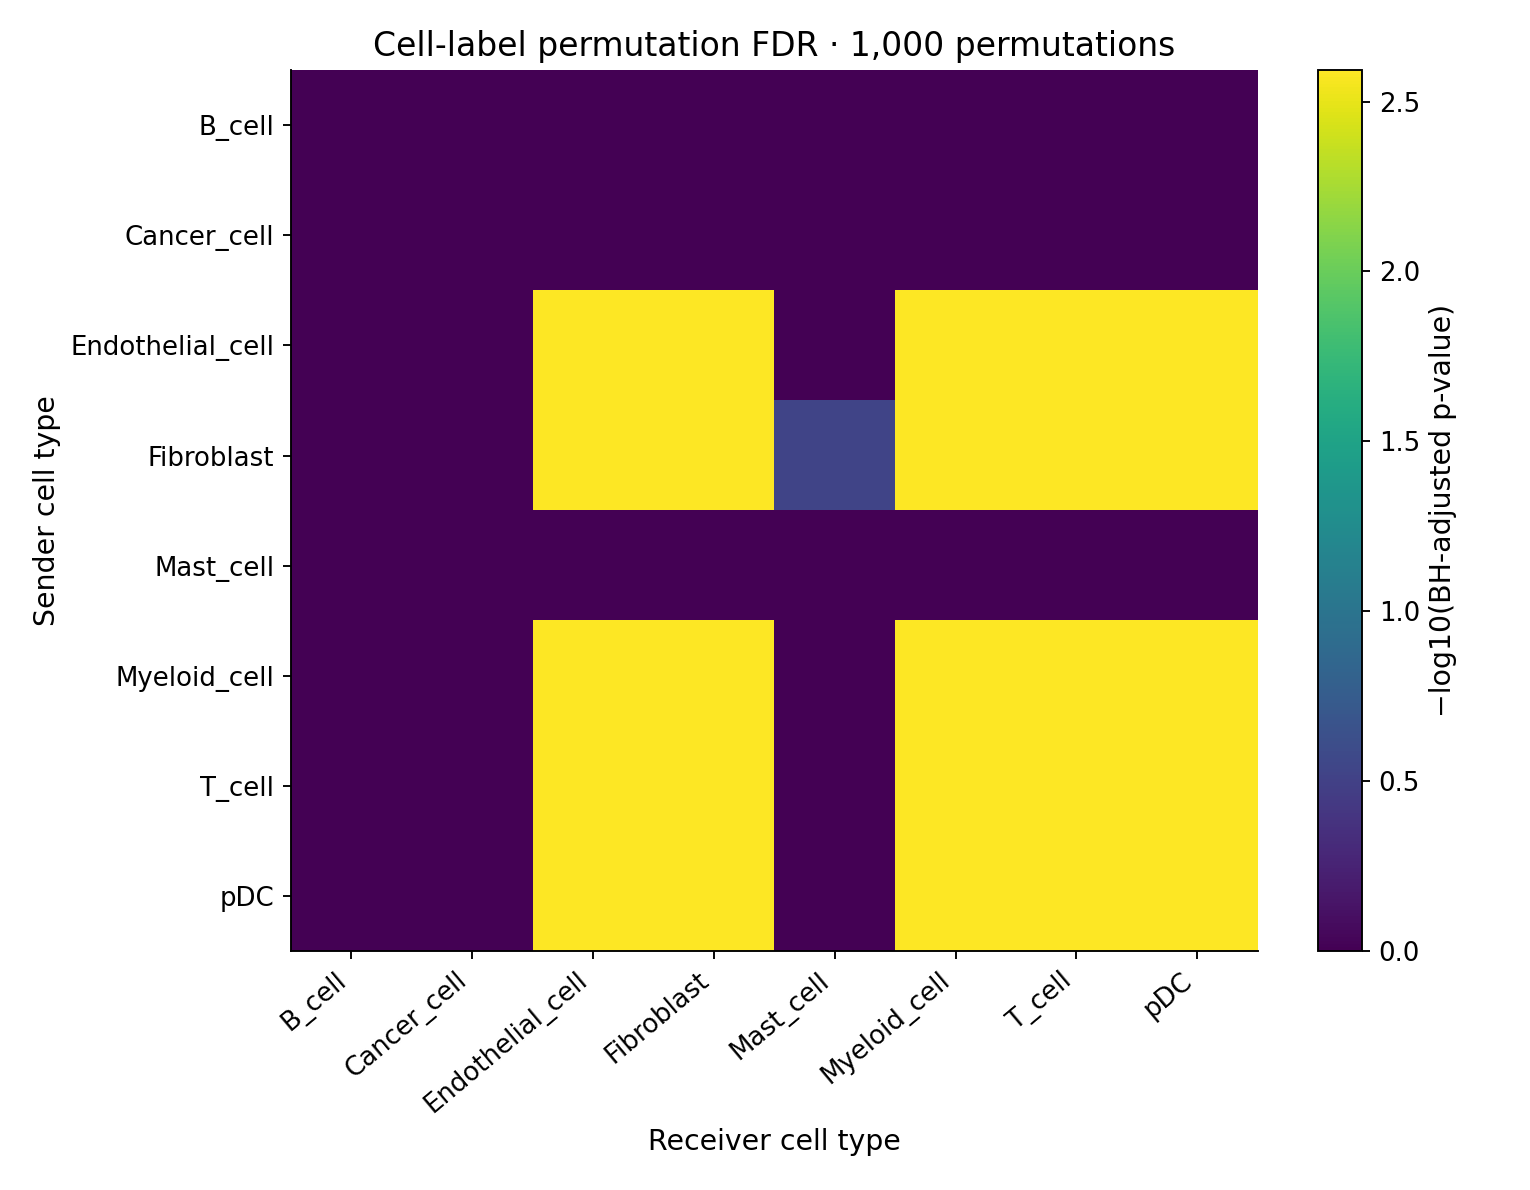

In [54]:
show_generated('signaling/inference/permutation_fdr.png')

Color shows −log10 of the BH-adjusted p-value. The test concerns sender–receiver totals under this cell-label null; it is not patient-blocked and does not test treatment effects or individual ligand–receptor pairs. With 1,000 permutations, the smallest attainable unadjusted p-value is 1/1,001. This view complements the activity-score heatmap rather than replacing it.

## 5. Network organization and centrality

In [55]:
plots.plot_network(comm, general, title='Cell-type communication network')

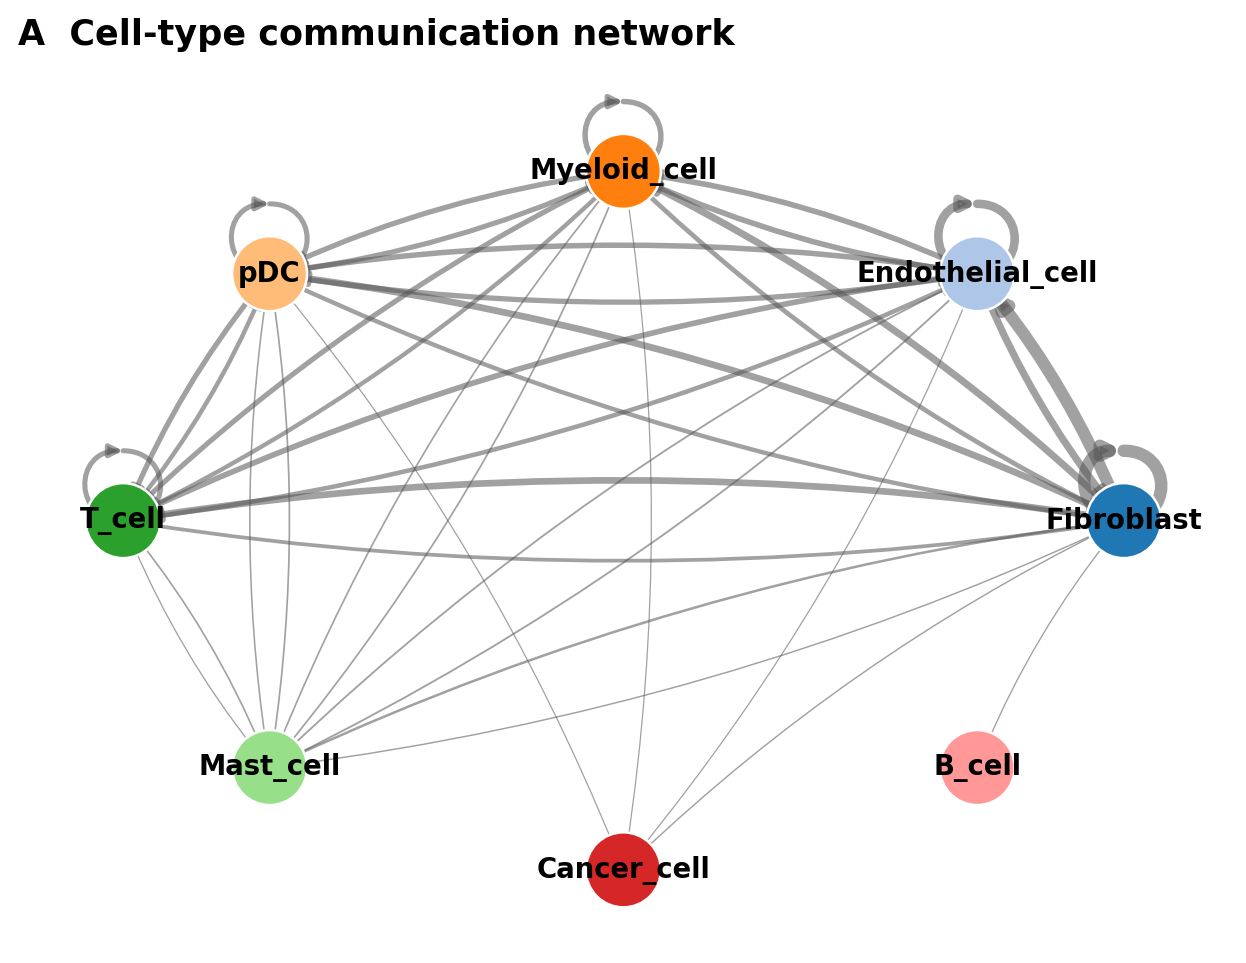

In [56]:
show_generated('signaling/general/06_hierarchical_network.png')

Arrows show direction for up to 40 positive links. Widths are scaled using the 2nd and 98th score percentiles; omitted links may still have positive scores. Circular positions are schematic, not physical locations.

In [57]:
# Network centrality: omit self-links; stronger edges have shorter inverse-score distances.
g=nx.DiGraph();g.add_nodes_from(groups)
for i,a in enumerate(groups):
 for j,b in enumerate(groups):
  if i!=j and observed[i,j]>0:g.add_edge(a,b,weight=float(observed[i,j]),distance=1/float(observed[i,j]))
between=nx.betweenness_centrality(g,weight='distance',normalized=True)
rank=nx.pagerank(g,weight='weight')
central=pd.DataFrame({'cell_type':groups,'outgoing_strength':[g.out_degree(a,weight='weight') for a in groups],'incoming_strength':[g.in_degree(a,weight='weight') for a in groups],'betweenness':[between[a] for a in groups],'pagerank':[rank[a] for a in groups]}).set_index('cell_type')
central.to_csv(out/'network_centrality.csv')
fig,axes=plt.subplots(2,2,figsize=(14,10))
for ax,col in zip(axes.flat,central):
 ax.barh(groups,central[col]);ax.invert_yaxis();ax.set_title(col.replace('_',' ').title());ax.set_xlabel('Score')
fig.suptitle('Descriptive centrality · self-links excluded');fig.tight_layout();fig.savefig(out/'network_centrality.png',dpi=170);plt.close(fig)

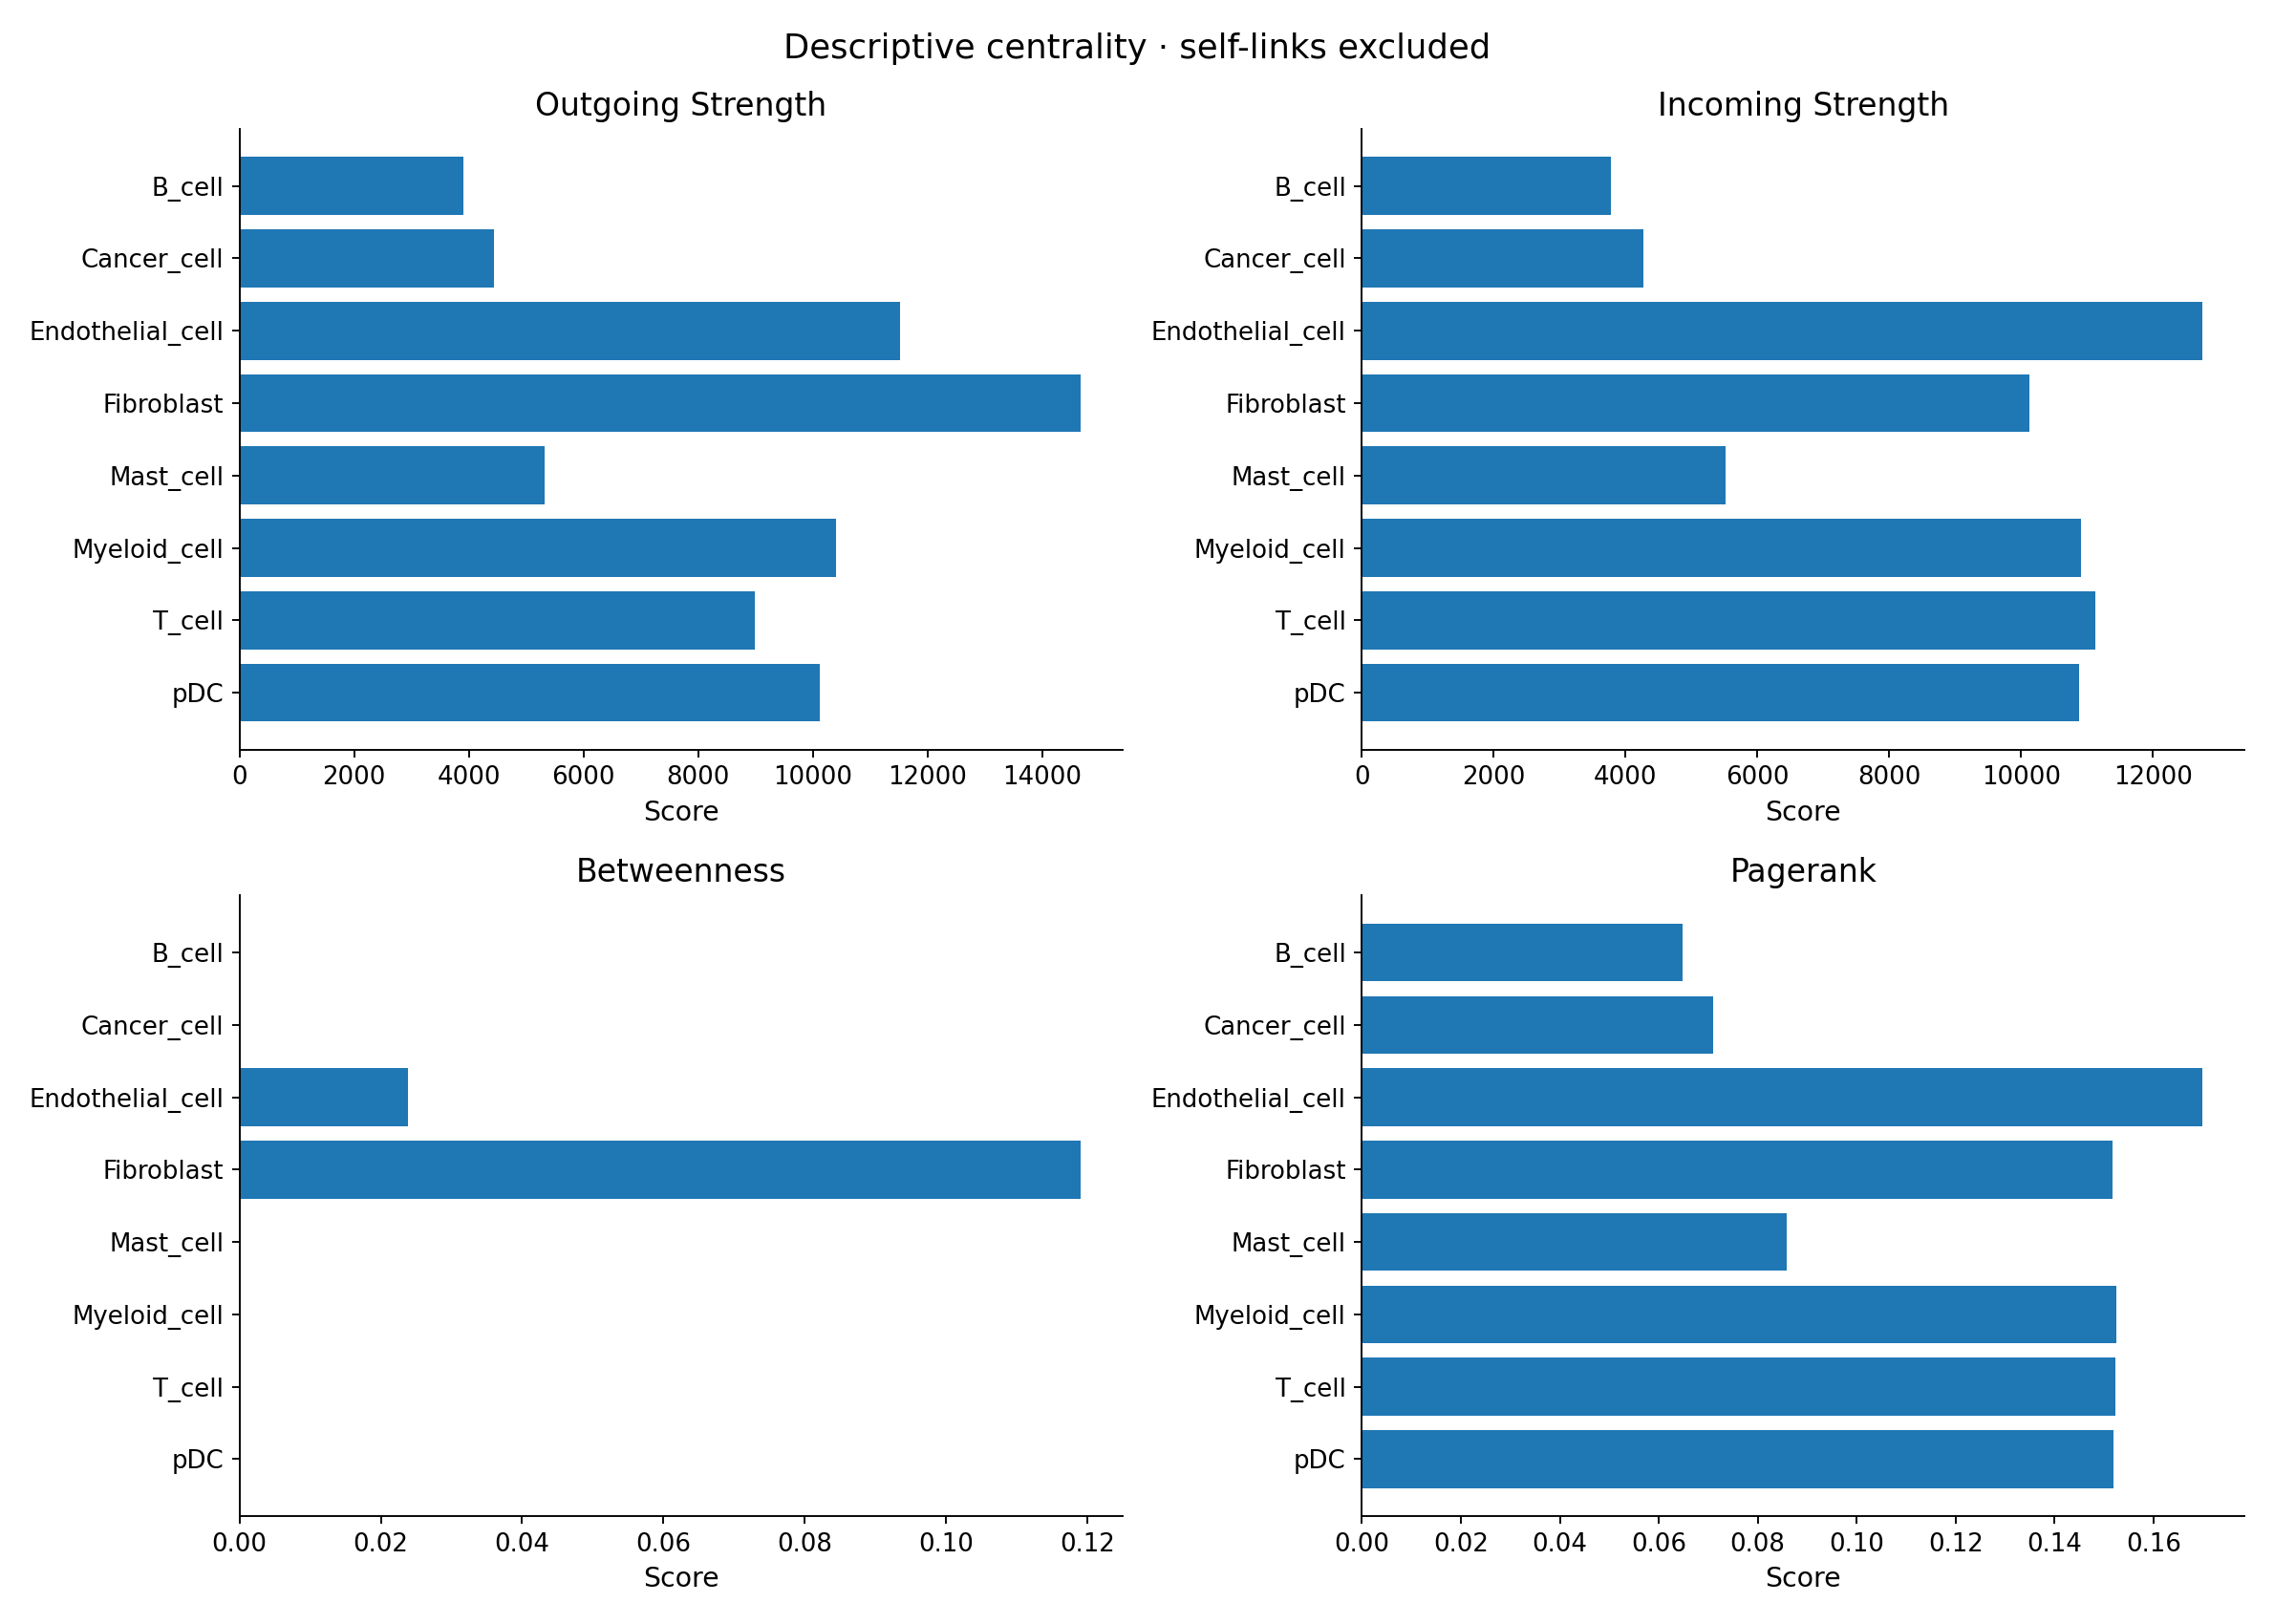

In [58]:
show_generated('signaling/inference/network_centrality.png')

Centrality uses the full positive-score network with self-links excluded. Strength sums edge scores, betweenness uses inverse score as distance, and PageRank uses score as weight. These describe network structure, not causal control. Their self-link convention differs explicitly from the inclusive totals in step 2.

## 6. Pathway example: VEGF

In [59]:
SELECTED_PATHWAY = 'VEGF'
# SELECTED_PATHWAY = 'CXCL'
# SELECTED_PATHWAY = 'TGFb'
# SELECTED_PATHWAY = 'WNT'
# SELECTED_PATHWAY = 'NOTCH'
# SELECTED_PATHWAY = 'IFN'
# SELECTED_PATHWAY = 'TNF'
frame = details.loc[details.pathway_name.astype(str) == SELECTED_PATHWAY].copy()
if frame.empty:
    raise ValueError('No interactions for ' + SELECTED_PATHWAY)
path_comm = frame.pivot_table(index='source', columns='target', values='weighted_score', aggfunc='sum', fill_value=0).reindex(index=groups, columns=groups, fill_value=0)
path_dir = base / 'signaling' / 'pathways' / SELECTED_PATHWAY

plots.plot_heatmaps(path_comm, None, path_dir, title=f'{SELECTED_PATHWAY} communication')

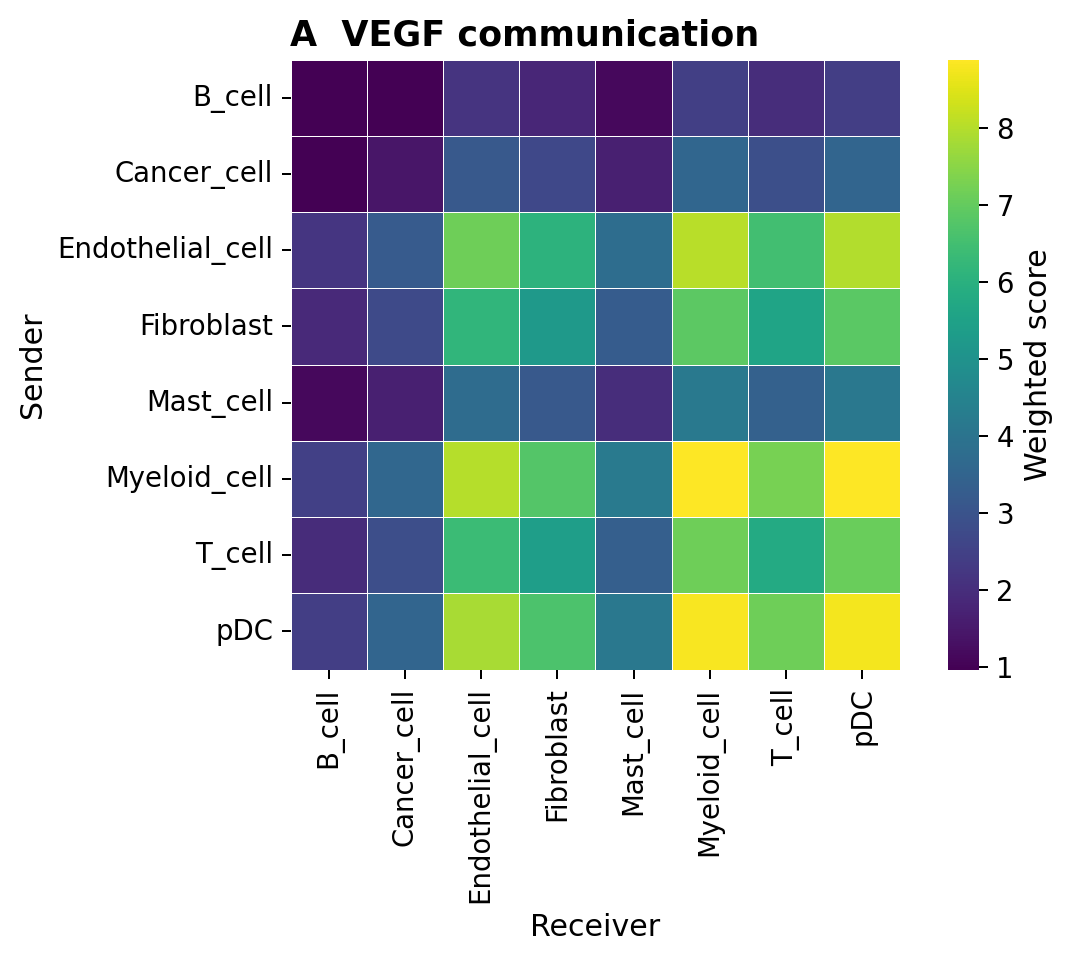

In [60]:
show_generated('signaling/pathways/VEGF/03_communication_heatmap.png')

This heatmap uses only VEGF records from the same interaction table. Its display range uses pathway-specific score percentiles, so colors should not be compared directly with the global heatmap. The FDR in step 4 applies to global sender–receiver totals, not individual pathways. An unavailable pathway raises an explicit error.

In [61]:
plots.plot_top_lr(frame, path_dir)
# plots.plot_sender_receiver(path_comm, path_dir)
# plots.plot_flow(path_comm, path_dir)
# plots.plot_bubble(frame, groups, path_dir)
# plots.plot_network(path_comm, path_dir, title=f"{SELECTED_PATHWAY} cell-type network")

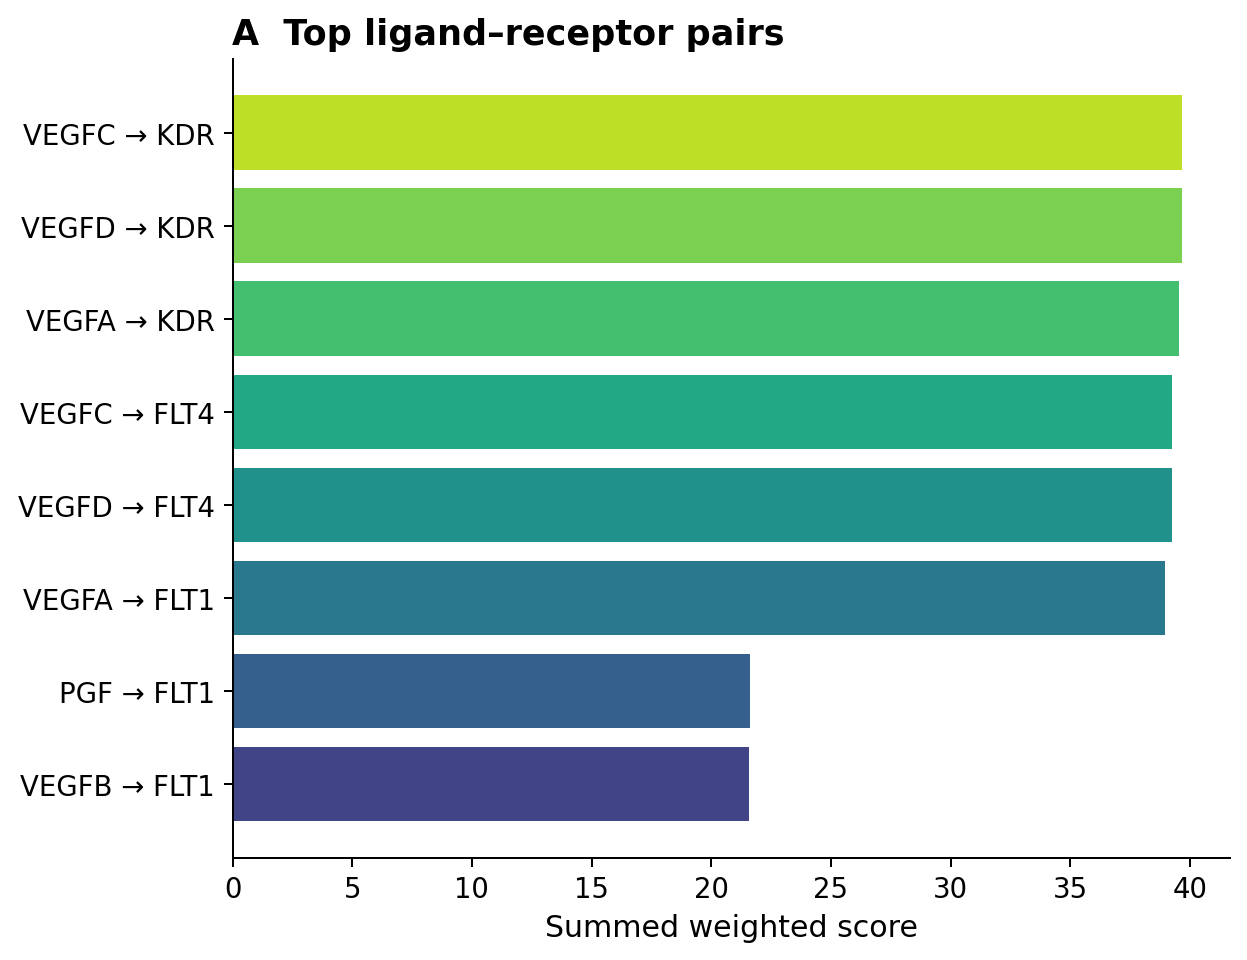

In [62]:
show_generated('signaling/pathways/VEGF/05_top_lr_pairs.png')

The ranking shows up to 15 VEGF ligand–receptor pairs by weighted score summed across cell-type pairs. It explains which interactions contribute to this pathway summary. Uncomment an alternative pathway or plotting call to explore another view.

## 7. On-minus-Pre signaling differences

Use exact timepoint labels and require at least ten cells per cell type in each condition. Pooled specificity and interaction definitions remain fixed across conditions.

In [63]:
contrast_report = {}
def draw_contrast(column, left, right, stem, title):
 matrices=[];group_counts=[]
 for condition in [left,right]:
  mask=meta[column].astype(str).eq(condition).to_numpy()
  m,c=lr.group_means(values[mask],labels[mask],len(groups));matrices.append(lr.communication_matrix(m,specificity,pairs));group_counts.append(c)
 # Require at least ten cells in each group/condition; unsupported pairs remain missing.
 eligible=(group_counts[0]>=10)&(group_counts[1]>=10)
 diff=matrices[0]-matrices[1];diff[~(eligible[:,None]&eligible[None,:])]=np.nan
 pd.DataFrame(diff,index=groups,columns=groups).to_csv(out/(stem+'.csv'))
 pd.DataFrame({left:group_counts[0],right:group_counts[1]},index=groups).to_csv(out/(stem+'_counts.csv'))
 heatmap(diff,title,stem+'.png',left+' − '+right+' weighted score',True)
 contrast_report[stem]={'excluded_cells':int((~meta[column].astype(str).isin([left,right])).sum()),'eligible_groups':list(np.array(groups)[eligible]),'counts':{left:list(map(int,group_counts[0])),right:list(map(int,group_counts[1]))}}

draw_contrast('timepoint', 'On', 'Pre', 'on_minus_pre', 'On minus Pre · pooled activity difference')
# draw_contrast('expansion', 'E', 'NE', 'expanded_minus_nonexpanded',
#               'E minus NE · clonotype expansion groups')

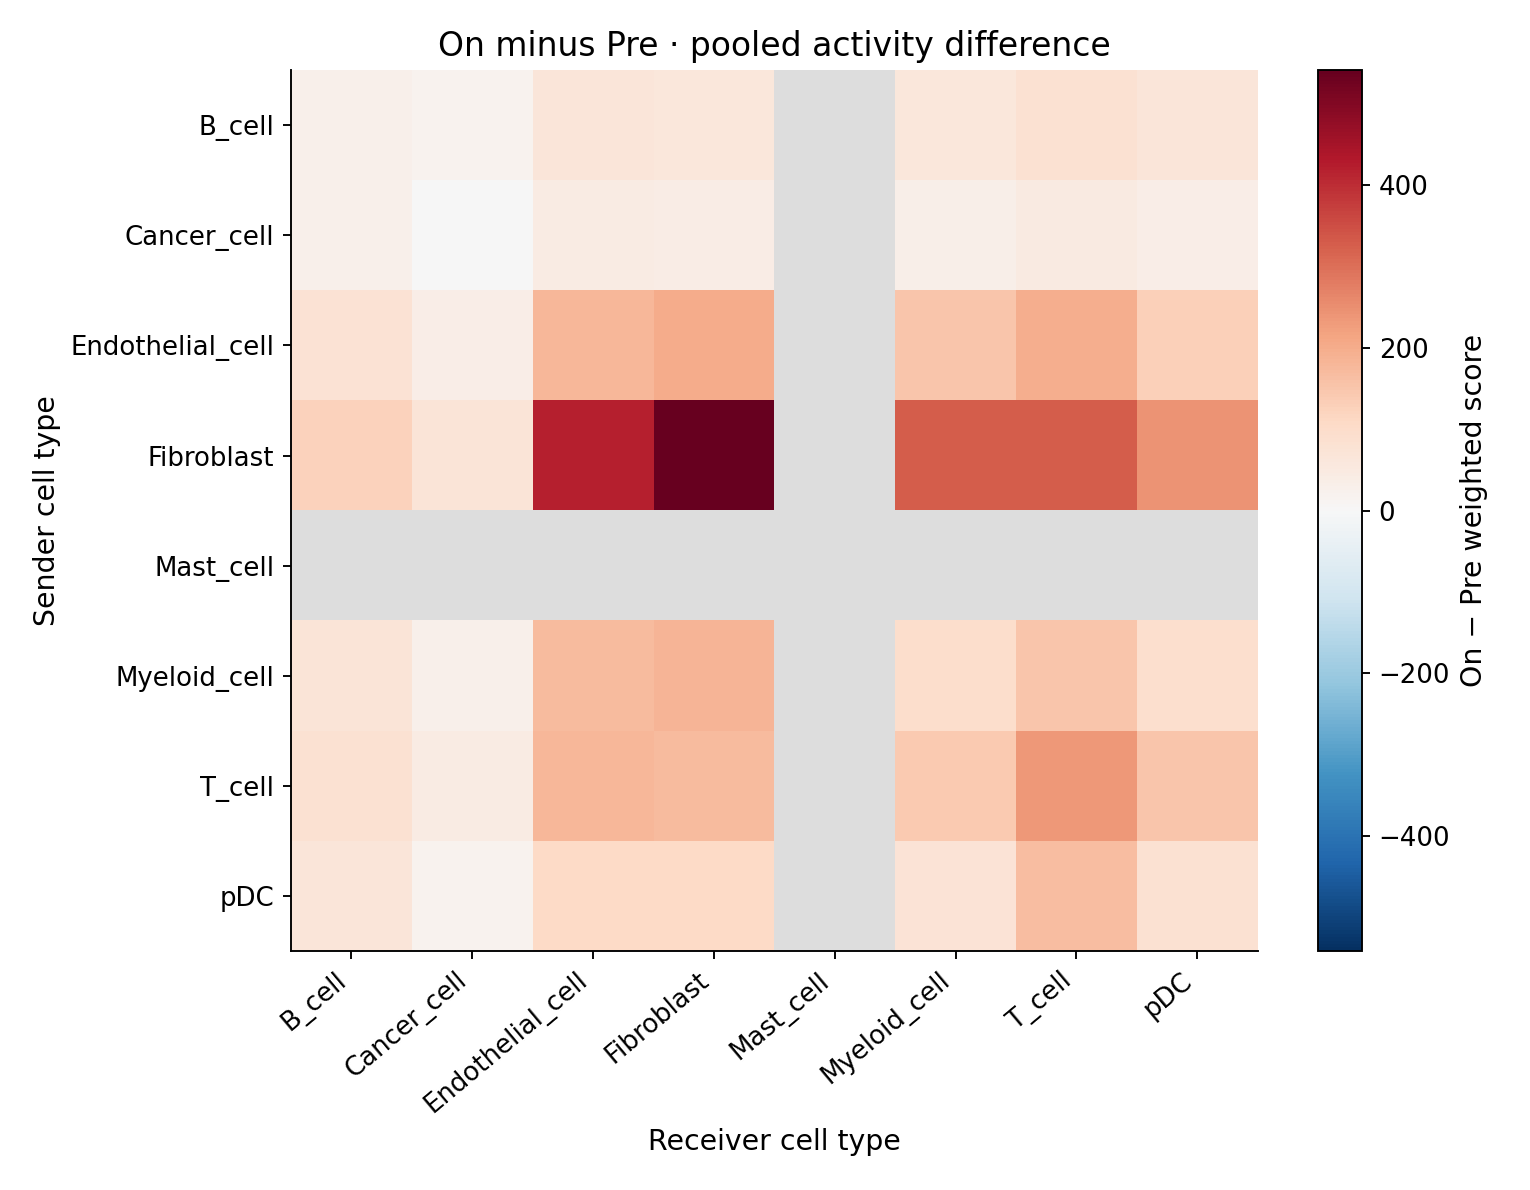

In [64]:
show_generated('signaling/inference/on_minus_pre.png')

Positive values indicate higher pooled scores On-treatment; negative values indicate higher scores Pre-treatment. Grey pairs lack sufficient cells in one or both conditions. This comparison is descriptive and unadjusted for patient composition, with no contrast p-values. The commented E/NE alternative refers to clonotype expansion/non-expansion, not clinical response.

## Outputs and next step

Scores and interaction tables are saved in `signaling/`; network plots in `signaling/general/`; permutation results, centrality and contrasts in `signaling/inference/`; pathway plots in `signaling/pathways/VEGF/`. For an optional extension, see [rank sensitivity and projection](../docs/tutorials/10000-validation.md).

# Optional: rank sensitivity and projection



**Prerequisite:** [model fitting](../docs/tutorials/10000-setup.md) for projection; complete the topic pages before reviewing their exported results. Run the command or its Python block, then review the exported results.

Split the selected sample into **8,000 training and 2,000 held-out cells**, seed 42. Fit ranks 8, 16 and 24 on training cells and project held-out expression onto each fixed `Rg @ W` basis using nonnegative least squares. The primary biological analysis remains the separate 16-factor fit on all 10,000 cells.

## Rank sensitivity and projection code

In [65]:
"""Exploratory rank sensitivity and held-out projection within the tutorial sample."""
import os,time,json,resource
from pathlib import Path
os.environ['MPLBACKEND']='Agg'
import numpy as np
import pandas as pd
import scanpy as sc
import networkx as nx
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 12, "axes.titlesize": 14,
                     "axes.labelsize": 12, "xtick.labelsize": 11,
                     "ytick.labelsize": 11, "legend.fontsize": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
from scipy.optimize import nnls
from scknife import run_full_pipeline
start=time.perf_counter()
ROOT=Path.cwd(); OUT=Path(os.environ.get('SCKNIFE_TUTORIAL_OUTPUT', ROOT/'tutorial/outputs_10000'))
adata=sc.read_h5ad(OUT/'fitted_subset.h5ad')
G=nx.read_graphml(ROOT/'graphs/version_1/unified_graph.graphml')
rng=np.random.default_rng(42); order=rng.permutation(adata.n_obs)
train=adata[order[:8000]].copy(); test=adata[order[8000:]].copy()
# Remove fitted results before fitting each training-only model.
train.uns.clear()
for col in [c for c in train.obs if c.startswith('H_graph_')]: del train.obs[col]
rows=[]; projections=[]
for rank in (8,16,24):
    model=run_full_pipeline(train.copy(),G,k=rank,lambda_reg=1,beta_W=.01,beta_H=.01,n_iter=60,tol=0,random_state=42,verbose=False)
    basis=np.asarray(model.uns['Rg'] @ model.uns['W_graph'])
    genes=model.var_names
    expression=test[:,genes].X
    expression=expression.toarray() if hasattr(expression,'toarray') else np.asarray(expression)
    predicted=np.column_stack([nnls(basis,x)[0] for x in expression])
    reconstructed=(basis@predicted).T
    error=np.linalg.norm(expression-reconstructed)/np.linalg.norm(expression)
    rows.append({'rank':rank,'training_cells':8000,'heldout_cells':2000,'relative_reconstruction_error':float(error)})
    if rank==16:
        projections=pd.DataFrame(predicted.T,index=test.obs_names,columns=[f'H_projected_{i}' for i in range(rank)])
    plt.close('all')
pd.DataFrame(rows).to_csv(OUT/'rank_sensitivity.csv',index=False)
projections.to_csv(OUT/'heldout_projected_factors.csv')
fig,ax=plt.subplots(figsize=(6,4));ax.plot([r['rank'] for r in rows],[r['relative_reconstruction_error'] for r in rows],marker='o')
ax.set_xticks([8,16,24]);ax.set_xlabel('Number of factors');ax.set_ylabel('Held-out relative reconstruction error')
ax.set_title('Exploratory rank sensitivity · 2,000 held-out cells')
fig.tight_layout();fig.savefig(OUT/'rank_sensitivity.png',dpi=160);plt.close(fig)
report={'elapsed_seconds':time.perf_counter()-start,'peak_rss_kib':resource.getrusage(resource.RUSAGE_SELF).ru_maxrss,'training_cells':8000,'heldout_cells':2000,'genes_selected_on_full_tutorial_sample':True,'purpose':'exploratory reconstruction diagnostic, not unbiased generalization or biological rank selection'}
(OUT/'validation_report.json').write_text(json.dumps(report,indent=2))
print(rows,report)

Starting Full scKNIFE (Graph-Regularized NMF) Pipeline...
Params - k=8, lambda=1, beta_W=0.01, beta_H=0.01, Iterations=60



Building gene-to-KG node mapping (Rg)...
Mapped 2000 genes to KG nodes.


Running scKNIFE Graph-Regularized NMF on CPU...


Epoch 0: Normalized Loss = 0.229607


Epoch 59: Normalized Loss = 0.188542
Storing H_graph components in adata.obs...
Stored W_graph in `adata.uns['W_graph']` (0.188542 final normalized loss)
Stored H_graph components in `adata.obs`
Running Standard NMF...


...

Running scKNIFE Graph-Regularized NMF on CPU...
Epoch 0: Normalized Loss = 0.225668


Epoch 59: Normalized Loss = 0.176612
Storing H_graph components in adata.obs...
Stored W_graph in `adata.uns['W_graph']` (0.176612 final normalized loss)
Stored H_graph components in `adata.obs`
Running Standard NMF...


Storing H_std components in adata.obs...
Stored W_std in `adata.uns['W_std']`
Stored H_std components in `adata.obs`
Std NMF -> Corr: 0.7283, Frobenius: 2758.29, Relative: 0.5921



Standard NMF:
   Pearson Correlation     : 0.7283
   Frobenius Error         : 2758.2888
   Relative Frobenius Error: 0.5921

scKNIFE (Graph-Regularized NMF):
   Pearson Correlation     : 0.7264
   Frobenius Error         : 2766.4881
   Relative Frobenius Error: 0.5938

Pipeline complete!
Results stored in `adata.obs` and `adata.uns`:
   - `W_std`, `W_graph`
   - `H_std_{i}`, `H_graph_{i}`
   - `loss_history`
   - `Rg`, `node_names`



[{'rank': 8, 'training_cells': 8000, 'heldout_cells': 2000, 'relative_reconstruction_error': 0.6129397752181226}, {'rank': 16, 'training_cells': 8000, 'heldout_cells': 2000, 'relative_reconstruction_error': 0.5997204679560902}, {'rank': 24, 'training_cells': 8000, 'heldout_cells': 2000, 'relative_reconstruction_error': 0.5931428251498104}] {'elapsed_seconds': 186.42864002403803, 'peak_rss_kib': 7760144, 'training_cells': 8000, 'heldout_cells': 2000, 'genes_selected_on_full_tutorial_sample': True, 'purpose': 'exploratory reconstruction diagnostic, not unbiased generalization or biological rank selection'}


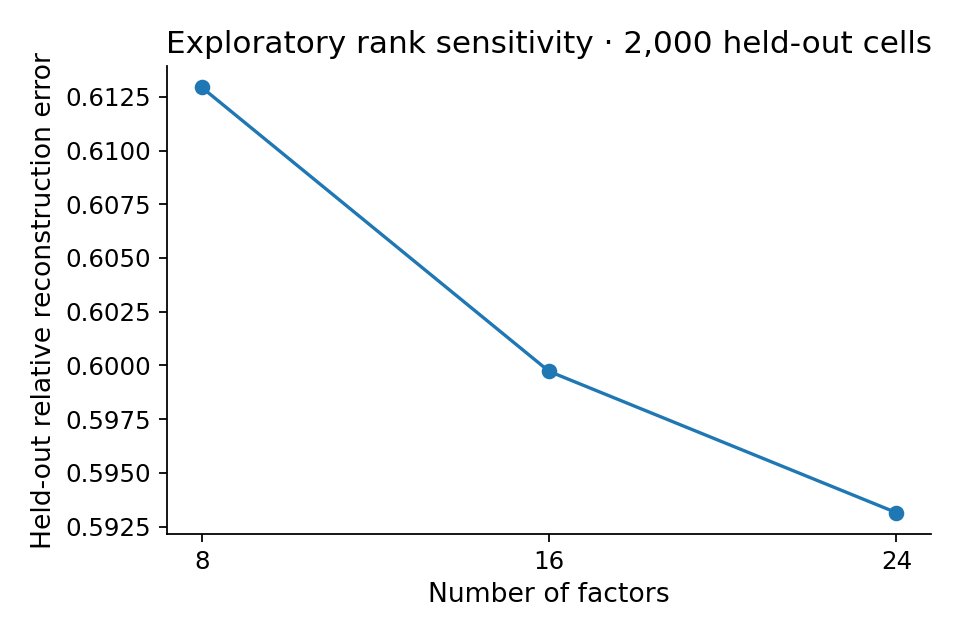

In [66]:
show_generated('rank_sensitivity.png')

Relative held-out reconstruction error across the three tested ranks.

Errors decrease from **0.61294** at rank 8 to **0.59972** at rank 16 and **0.59314** at rank 24. Because gene selection used the full sample, this is an exploratory reconstruction diagnostic, not an unbiased generalization benchmark or proof of an optimal biological rank.

The diagnostic plot has factor count on the x-axis and relative held-out reconstruction error on the y-axis; lower error means better reconstruction for this split. It does not establish better cell identities.

## Save and review the primary outputs

Primary results use `fitted_subset.h5ad` and `activity_scores.parquet`, with source `cellType` metadata retained. Review `sampling_audit.csv`, `sample_metadata.csv`, and results in `metabolic_walkthrough/`, `factor_interpretation_k4/` and `signaling/`. Preserve cell identifiers and ordering when reusing these outputs.

## Completion

All main analyses use the same 10,000-cell fit and preserve source labels. The optional rank sensitivity and projection section uses an 8,000/2,000 split within that sample. Reuse the exported activities with biological relationships appropriate to your next question. VEGF and On minus Pre are worked examples; commented choices show where to select alternatives.

See [biological resources and citations](../docs/graph-resources.md) for upstream resource details.